# Esperimenti preliminari con i VLM

In questo notebook si vanno a verificare preliminarmente le capacità di Qwen 3.5 2B e Gemma 4 E2B, in particolare se ne valutano le capacità su piccole quantità di dati e si controlla che dati, immagini, richieste al server e salvataggio dei risultati funzionino correttamente.

Tutte le impostazioni principali sono modificabili tramite il file di oconfigurazione "**config_vlm.yaml**" presente in '**/configs/**'.

## Librerie e percorsi

In [1]:
#librerie principali
import json
import pandas as pd
import yaml
import requests
import time
import base64
import mimetypes
import shlex
import shutil
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from IPython.display import display, Image as DisplayImage
from collections import Counter

In [22]:
#cerchiamo la cartella principale del progetto
PROJECT_ROOT = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "data" / "processed").is_dir():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Non trovo la cartella data/processed. "
        "Apri il notebook dalla cartella del progetto o da una sua sottocartella."
    )

#carichiamo la configurazione esterna
CONFIG_PATH = PROJECT_ROOT / "configs" / "config_vlm.yaml"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(
        f"File di configurazione non trovato: {CONFIG_PATH}. "
        "Inserisci config_vlm.yaml nella cartella results/vlm_preliminary."
    )

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

if not isinstance(config, dict):
    raise ValueError("Il file config_vlm.yaml non contiene una configurazione valida.")

#cartelle dei dataset preparati
PROCESSED_DIR = PROJECT_ROOT / config["paths"]["processed_dir"]
KANDY_DIR = PROCESSED_DIR / config["datasets"]["kandy"]["folder"]
RWR_DIR = PROCESSED_DIR / config["datasets"]["rwr_plus"]["folder"]
OVERLAP_DIR = PROCESSED_DIR / config["datasets"]["overlap"]["folder"]

#cartelle per i risultati dei test preliminari
RESULTS_DIR = PROJECT_ROOT / config["paths"]["results_dir"]
EXPERIMENTS_DIR = PROJECT_ROOT / config["paths"]["experiments_dir"]
CACHE_DIR = EXPERIMENTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

print("progetto:", PROJECT_ROOT)
print("configurazione:", CONFIG_PATH)
print("risultati:", RESULTS_DIR)
print("esperimenti:", EXPERIMENTS_DIR)


progetto: /home/cosimo/progetti/tesi
configurazione: /home/cosimo/progetti/tesi/configs/config_vlm.yaml
risultati: /home/cosimo/progetti/tesi/results
esperimenti: /home/cosimo/progetti/tesi/results/vlm_preliminary


## Caricamento degli Indici e Controllo Immagini

Carichiamo gli indici prodotti dal notebook precedente e gli esempi dei task che andremo a sottoporre ai modelli e ne verifichiamo la correttezza.

In [23]:
#CONTROLLO DEGLI INDICI 

#controlliamo che i manifest principali esistano
KANDY_MANIFEST_PATH = KANDY_DIR / config["datasets"]["kandy"]["manifest"]
RWR_MANIFEST_PATH = RWR_DIR / config["datasets"]["rwr_plus"]["manifest"]
OVERLAP_MANIFEST_PATH = OVERLAP_DIR / config["datasets"]["overlap"]["manifest"]
OVERLAP_IMAGE_MANIFEST_PATH = OVERLAP_DIR / config["datasets"]["overlap"]["image_manifest"]
CROSS_TEST_MANIFEST_PATH = OVERLAP_DIR / config["datasets"]["overlap"]["cross_test_manifest"]

manifest_paths = {
    "KANDY Bongard": KANDY_MANIFEST_PATH,
    "Bongard-RWR+": RWR_MANIFEST_PATH,
    "Intersezione": OVERLAP_MANIFEST_PATH,
    "Immagini intersezione": OVERLAP_IMAGE_MANIFEST_PATH,
    "Cross-dataset": CROSS_TEST_MANIFEST_PATH
}

for name, path in manifest_paths.items():
    print(f"{name}: {'OK' if path.is_file() else 'mancante'}")

missing = [str(path) for path in manifest_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Mancano alcuni manifest. Esegui prima 1.2-DATASETS.ipynb:\n" +
        "\n".join(missing)
    )

#leggiamo i manifest
kandy_manifest = pd.read_csv(KANDY_MANIFEST_PATH)
rwr_manifest = pd.read_csv(RWR_MANIFEST_PATH)
overlap_manifest = pd.read_csv(OVERLAP_MANIFEST_PATH)
overlap_image_manifest = pd.read_csv(OVERLAP_IMAGE_MANIFEST_PATH)
cross_test_manifest = pd.read_csv(CROSS_TEST_MANIFEST_PATH)

print("\nProblemi KANDY Bongard:", len(kandy_manifest))
print("Profili Bongard-RWR+:", len(rwr_manifest))
print("Problemi di intersezione:", len(overlap_manifest))
print("Immagini nell'intersezione:", len(overlap_image_manifest))
print("Episodi cross-dataset:", len(cross_test_manifest))

display(kandy_manifest.head(2))
display(rwr_manifest.head(2))

KANDY Bongard: OK
Bongard-RWR+: OK
Intersezione: OK
Immagini intersezione: OK
Cross-dataset: OK

Problemi KANDY Bongard: 38
Profili Bongard-RWR+: 38
Problemi di intersezione: 3
Immagini nell'intersezione: 36
Episodi cross-dataset: 6


,problem_id,level,task_id,positive_images,negative_images,n_positive,n_negative,positive_blank_slots,negative_blank_slots,whole_image,left_image,right_image
0,easy-0,easy,0,"[""single/easy-0/positive/positive_01.png"", ""si...","[""single/easy-0/negative/negative_01.png"", ""si...",6,6,0,0,bongard/easy-0/whole.png,bongard/easy-0/left.png,bongard/easy-0/right.png
1,easy-1,easy,1,"[""single/easy-1/positive/positive_01.png"", ""si...","[""single/easy-1/negative/negative_01.png"", ""si...",6,6,0,0,bongard/easy-1/whole.png,bongard/easy-1/left.png,bongard/easy-1/right.png


,profile_id,id,concept_group,left_concept,right_concept,n_left,n_right,diversity,left_context,left_test,right_context,right_test,whole_image,left_side_image,right_side_image
0,Q20,30022,Similarity,Areas of figures approximately equal,Areas of figures differ greatly,3,6,0.175,"[""single/Q20/left/context_01.jpg"", ""single/Q20...",single/Q20/left/test.jpg,"[""single/Q20/right/context_01.jpg"", ""single/Q2...",single/Q20/right/test.jpg,bongard_original/Q20/reconstructed/whole.png,bongard_original/Q20/reconstructed/left.png,bongard_original/Q20/reconstructed/right.png
1,Q14,91034,Size,A large hole,A small hole,6,6,0.224,"[""single/Q14/left/context_01.jpg"", ""single/Q14...",single/Q14/left/test.jpg,"[""single/Q14/right/context_01.jpg"", ""single/Q1...",single/Q14/right/test.jpg,bongard_original/Q14/reconstructed/whole.png,bongard_original/Q14/reconstructed/left.png,bongard_original/Q14/reconstructed/right.png


In [24]:
#CONTROLLO IMMAGINI

#raccogliamo tutti i percorsi delle immagini
image_paths = {}

def add_images(name, folder, paths):
    for path in paths:
        full_path = folder / path
        image_paths[str(full_path)] = (name, full_path)


#immagini KANDY
for _, row in kandy_manifest.iterrows():

    for column in ["positive_images", "negative_images"]:
        add_images("KANDY", KANDY_DIR, json.loads(row[column]))

    add_images("KANDY", KANDY_DIR, [
        row["whole_image"],
        row["left_image"],
        row["right_image"]
    ])


#immagini Bongard-RWR+
for _, row in rwr_manifest.iterrows():

    for column in ["left_context", "right_context"]:
        add_images("RWR+", RWR_DIR, json.loads(row[column]))

    add_images("RWR+", RWR_DIR, [
        row["left_test"],
        row["right_test"],
        row["whole_image"],
        row["left_side_image"],
        row["right_side_image"]
    ])


#immagini dell'intersezione
add_images(
    "Intersezione",
    OVERLAP_DIR,
    overlap_image_manifest["output_image"].tolist()
)

for _, row in overlap_manifest.iterrows():
    add_images("Intersezione", OVERLAP_DIR, [
        row["whole_image"],
        row["left_image"],
        row["right_image"]
    ])


#immagini degli episodi cross-dataset
for _, row in cross_test_manifest.iterrows():

    for column in ["left_context_kandy", "right_context_kandy"]:
        add_images("Cross-dataset", OVERLAP_DIR, json.loads(row[column]))

    add_images("Cross-dataset", OVERLAP_DIR, [row["target_image"]])


#verifichiamo esistenza e leggibilità
missing = []
unreadable = []
checked = []

for name, path in image_paths.values():

    if not path.is_file():
        missing.append((name, str(path)))
        continue

    try:
        with Image.open(path) as image:
            image.load()

        checked.append(name)

    except Exception as error:
        unreadable.append((name, str(path), str(error)))


#mostriamo i risultati
print("Immagini da controllare:", len(image_paths))
print("Immagini leggibili:", len(checked))
print("Immagini mancanti:", len(missing))
print("Immagini non leggibili:", len(unreadable))

if missing:
    print("\nImmagini mancanti:")
    for name, path in missing:
        print(name, path)

if unreadable:
    print("\nImmagini non leggibili:")
    for name, path, error in unreadable:
        print(name, path, error)

if missing or unreadable:
    raise ValueError("Il controllo delle immagini non è stato superato.")

print("\nTutte le immagini sono presenti e leggibili.")

Immagini da controllare: 1220
Immagini leggibili: 1220
Immagini mancanti: 0
Immagini non leggibili: 0

Tutte le immagini sono presenti e leggibili.


KANDY Bongard


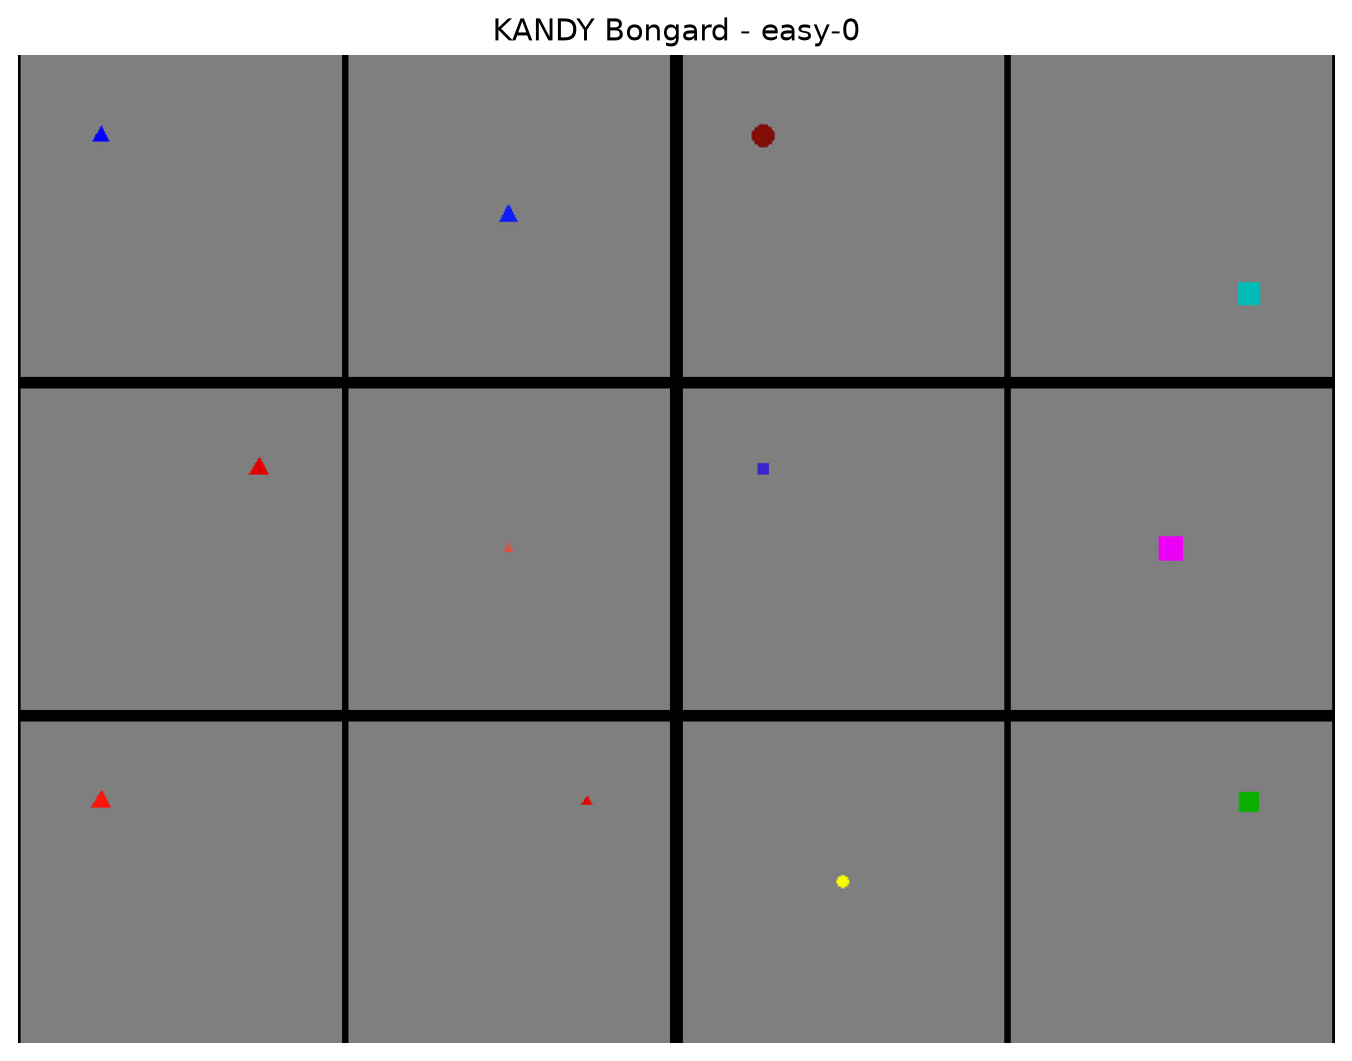

Bongard-RWR+


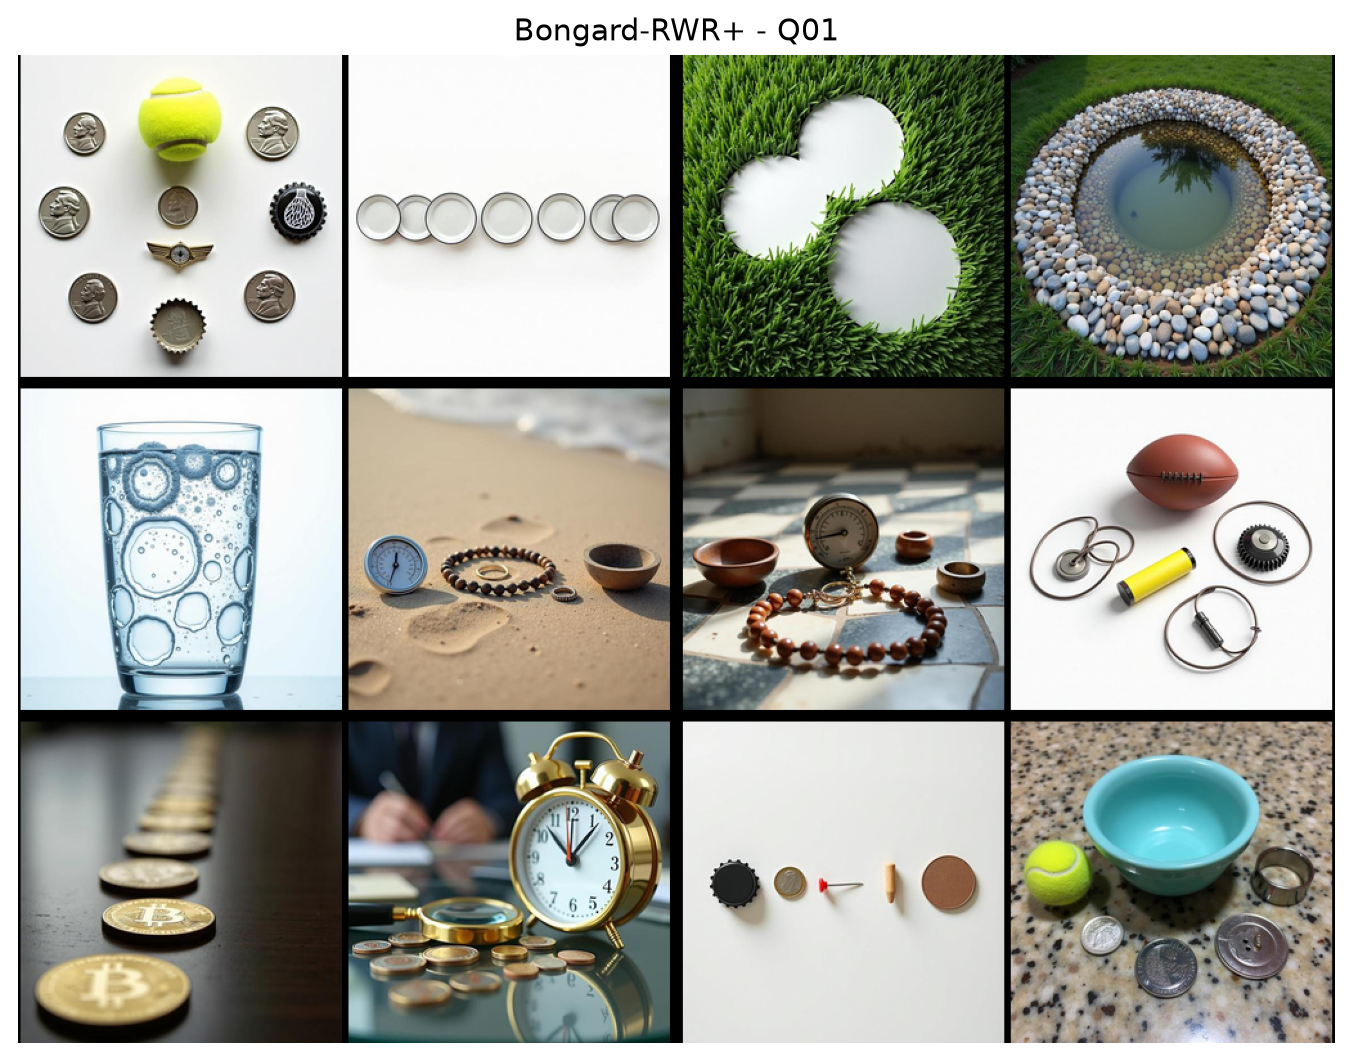

Intersezione


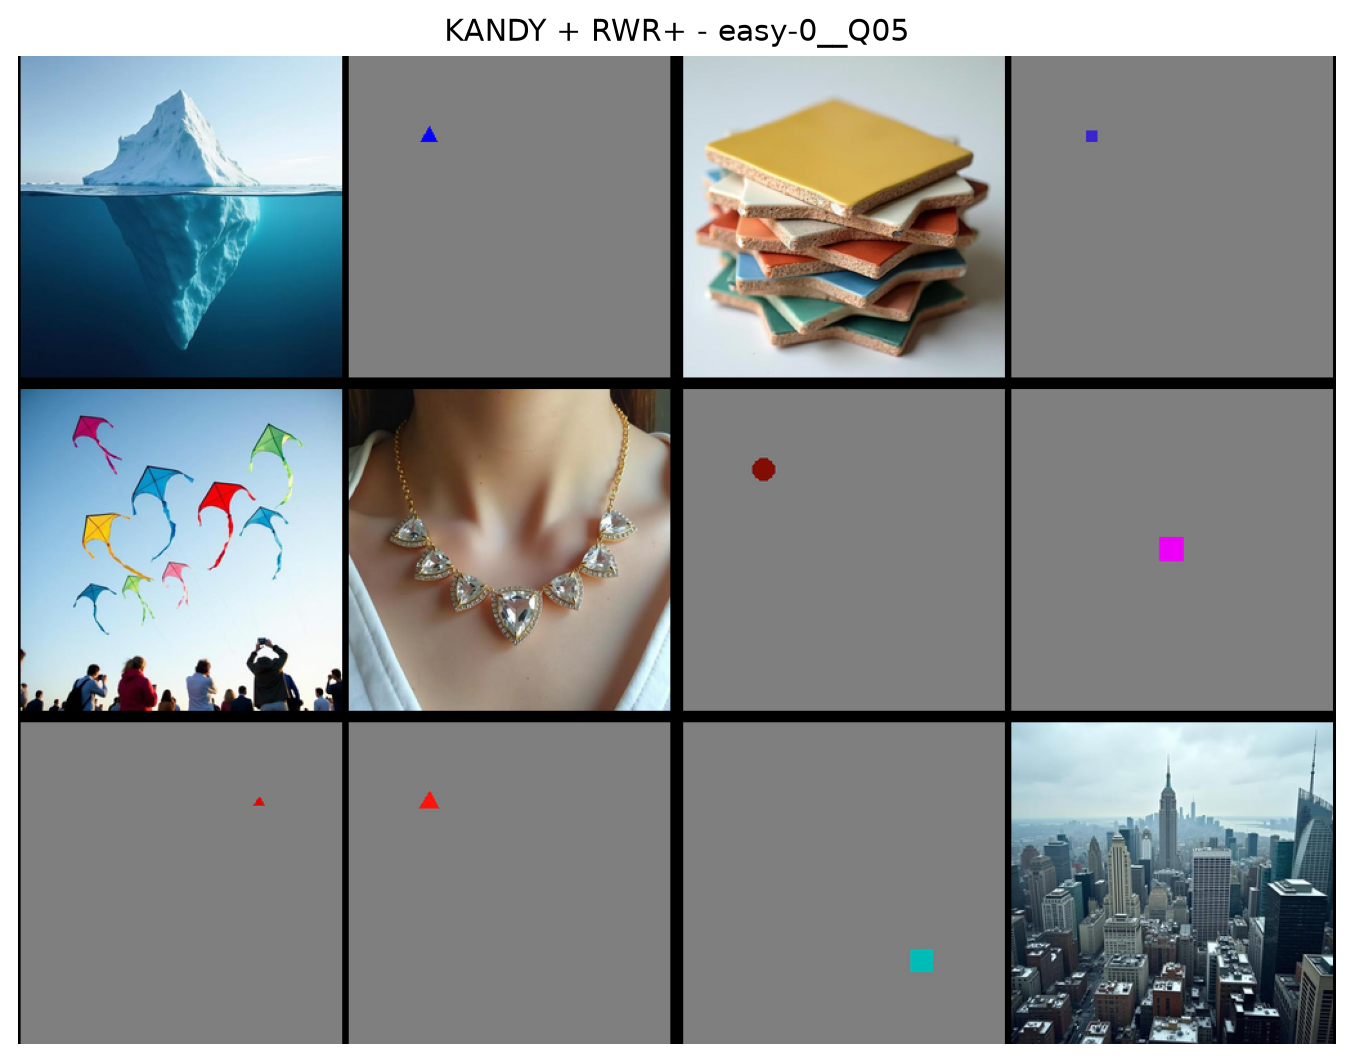

Cross-dataset


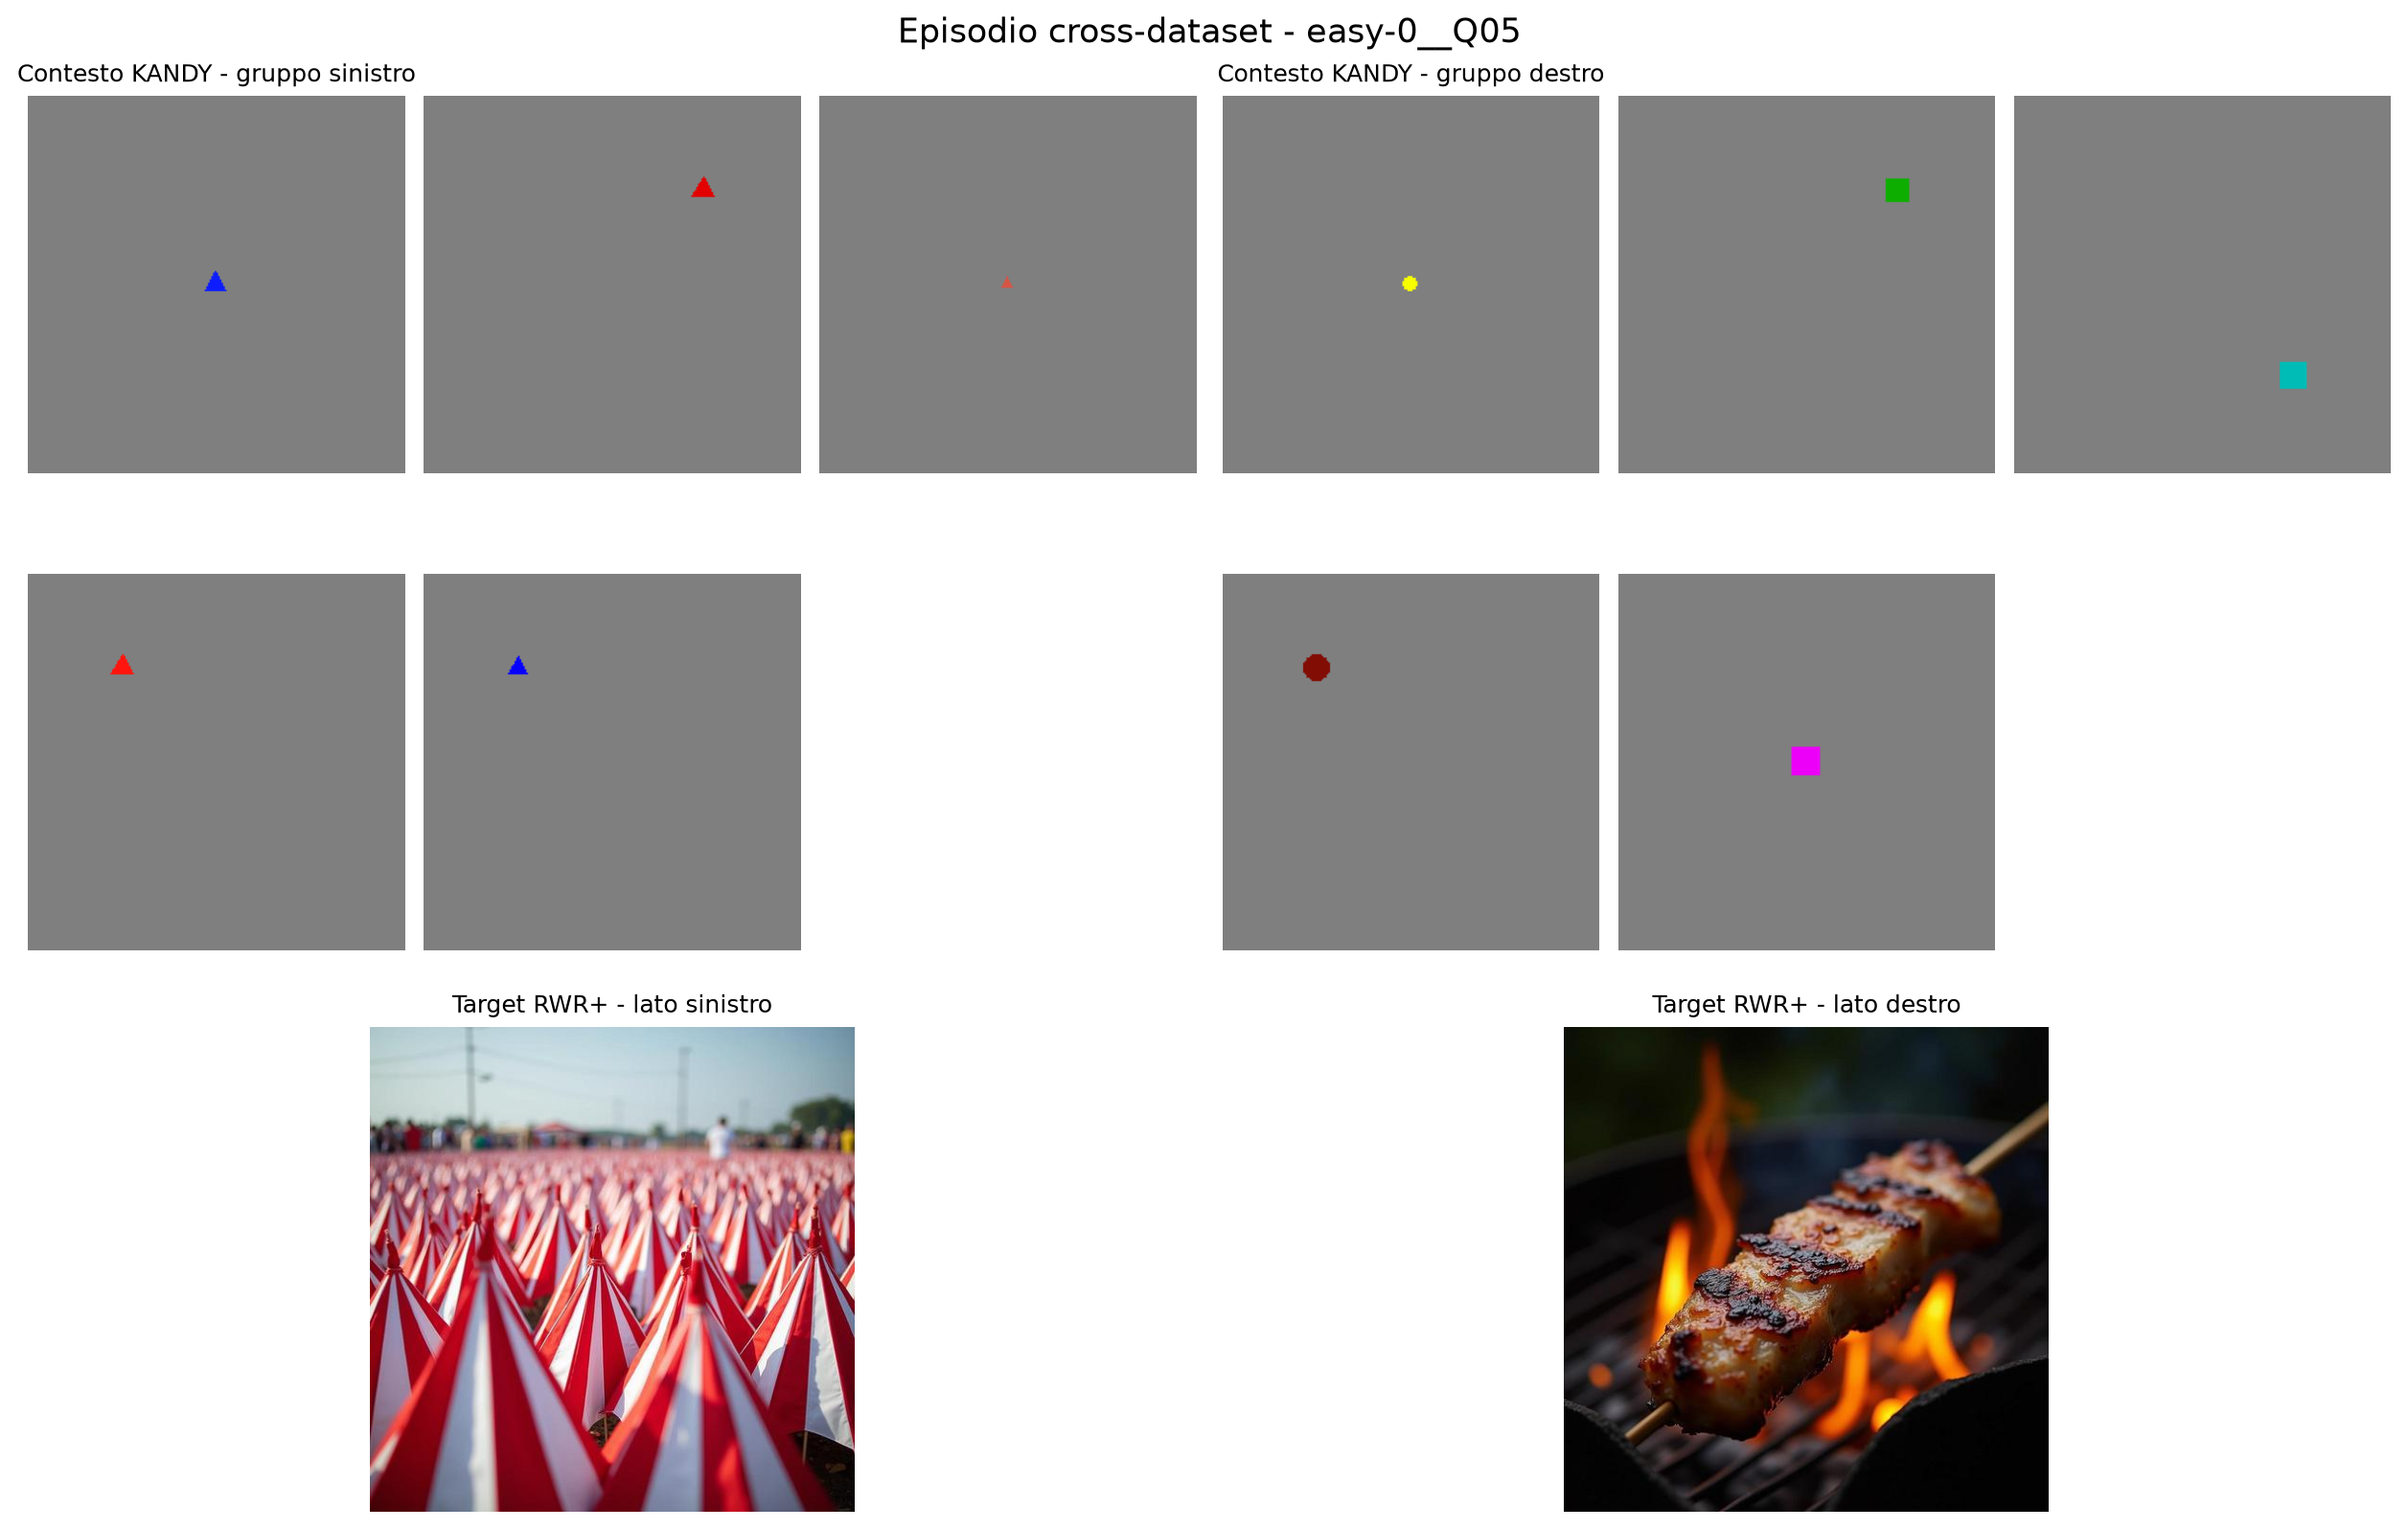

In [25]:
#REMINDER DEI TASK

#carichiamo gli esempi generati nel notebook 1.2
EXAMPLES_DIR = RESULTS_DIR / "dataset_examples"

examples = {
    "KANDY Bongard": "kandy_bongard.png",
    "Bongard-RWR+": "rwr_plus.png",
    "Intersezione": "kandy_rwr_overlap.png",
    "Cross-dataset": "cross_dataset.png"
}

#controlliamo che gli esempi esistano
for name, filename in examples.items():

    image_path = EXAMPLES_DIR / filename

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Immagine non trovata: {image_path}. "
            "Esegui prima la cella di visualizzazione del notebook 1.2."
        )

    print(name)
    display(DisplayImage(filename=str(image_path)))

## Caricamento e Configurazione dei Modelli Locali

In questa sezione configuriamo i modelli che utilizzeremo durante gli esperimenti preliminari; come già avvertito nell'introduzione di questo notebook, per gestire in maniera flessibile le diverse impostazioni, utilizziamo un file di configurazione esterno (config_vlm.yaml).

### Modelli utilizzati

Per gli esperimenti preliminari sono stati selezionato due modelli multimodali di piccole dimensioni:

- **Qwen 3.5 2B Q4_K_M**
- **Gemma 4 E2B-it Q4_0**

Per ogni modello vengono specificati nel file YAML:
- label: nome descrittivo del modello.
- repo: repository di Hugging Face in cui sono conservati i file.
- model_file: file GGUF contenente i pesi del modello.
- mmproj_file: file del proiettore multimodale necessario per elaborare gli input visivi.

### Configurazione dell'ambiente di esecuzione

Per eseguire i modelli si è utilizzaro **llama.cpp**, un motore di inferenza open source; tra gli strumenti messi a disposizione dal progetto è presente llama-server, che consente di esporre il modello attraverso un'interfaccia HTTP compatibile con le API OpenAI. In questo modo, applicazioni esterne possono inviare richieste e riceverne le risposte attraverso chiamate HTTP.

La configurazione del server è definita attraverso i seguenti parametri:

- executable: identifica il programma da utilizzare per avviare il server.
- host: specifica l'indirizzo di rete sul quale il server deve mettersi in ascolto.
- port: indica la porta di rete sulla quale il server riceve le richieste.
- context_size: definisce la dimensione massima della finestra di contesto, espressa in token; comprende le informazioni fornite in ingresso e lo spazio necessario per la generazione della risposta.
- cpu_threads: stabilisce il numero di thread CPU da utilizzare durante l'elaborazione.
- gpu_layers: indica il numero di layer del modello da trasferire ed eseguire sulla GPU.
- mmproj_offload: indica se consentire il trasferimento del proiettore multimodale sulla GPU. Il valore true abilita l'offload, mentre false lo disabilita.
- request_timeout: stabilisce il tempo massimo di attesa, espresso in secondi, concesso al client per ricevere una risposta dal server prima che la richiesta venga considerata scaduta.

### Configurazione degli esperimenti

Oltre ai parametri relativi all'ambiente di esecuzione, il file YAML contiene le impostazioni che regolano la generazione delle risposte e la selezione degli esempi da sottoporre ai test.

I principali parametri sono:

- run_mode: identifica la modalità di esecuzione degli esperimenti. Può distinguere una fase preliminare (*pilot*), caratterizzata da un numero limitato di esempi, da un'esecuzione completa (*full*).
- pilot_limit: definisce il numero massimo di esempi da selezionare per ciascun test durante la modalità preliminare.
- temperature: controlla la variabilità della generazione, influenzando la distribuzione di probabilità utilizzata per selezionare i token. Valori più bassi favoriscono risposte meno variabili, mentre valori più alti aumentano la diversità delle generazioni.
- top_p: controlla la selezione dei token considerando il più piccolo insieme di token la cui probabilità cumulativa raggiunge il valore specificato.
- seed: definisce il seme utilizzato per inizializzare i generatori di numeri casuali, favorendo la ripetibilità delle operazioni che dipendono dalla casualità.
- thinking_enabled: indica se abilitare la modalità di ragionamento esplicito (*thinking*), quando supportata dal modello e dal runtime utilizzato.

In [26]:
#SELEZIONE E VERIFICA DEL MODELLO LOCALE SCELTO

#selezioniamo il modello dal file yaml
ACTIVE_MODEL = config["models"]["active"]
AVAILABLE_MODELS = config["models"]["available"]

if ACTIVE_MODEL not in AVAILABLE_MODELS:
    raise ValueError(f"Modello non riconosciuto: {ACTIVE_MODEL}")

model_info = AVAILABLE_MODELS[ACTIVE_MODEL]
MODEL_LABEL = model_info["label"]

#cartella della cache hugging face
HF_HUB_DIR = Path(config["models"]["hf_cache_dir"]).expanduser()


def find_model_file(path_key, file_key):
    #se nel yaml è indicato un percorso diretto utilizziamo quello
    configured_path = model_info.get(path_key)

    if configured_path:
        path = Path(configured_path).expanduser()
        if not path.is_absolute():
            path = PROJECT_ROOT / path

        if not path.is_file():
            raise FileNotFoundError(f"File non trovato: {path}")

        return path

    #altrimenti cerchiamo il file nella cache hugging face
    snapshot_dir = HF_HUB_DIR / model_info["repo"] / "snapshots"
    matches = [
        path for path in snapshot_dir.glob(f"*/{model_info[file_key]}")
        if path.is_file()
    ]

    if not matches:
        raise FileNotFoundError(
            f"File non trovato: {model_info[file_key]}\n"
            f"Percorso controllato: {snapshot_dir}"
        )

    #se ci sono più snapshot scegliamo quello modificato più di recente
    matches.sort(key=lambda path: path.stat().st_mtime, reverse=True)
    return matches[0]


#individuiamo modello e proiettore multimodale
model_path = find_model_file("model_path", "model_file")
mmproj_path = find_model_file("mmproj_path", "mmproj_file")

print("Modello:", MODEL_LABEL)
print("File GGUF:", model_path)
print("File mmproj:", mmproj_path)

Modello: Qwen 3.5 2B Q4_K_M
File GGUF: /home/cosimo/.cache/huggingface/hub/models--gguf--Qwen3.5-2B-GGUF/snapshots/47f5192dcee31b32db0ba0acc04cccef89cb4b2c/qwen3.5-2b-Q4_K_M.gguf
File mmproj: /home/cosimo/.cache/huggingface/hub/models--gguf--Qwen3.5-2B-GGUF/snapshots/47f5192dcee31b32db0ba0acc04cccef89cb4b2c/mmproj-qwen3.5-2b-F16.gguf


In [27]:
#leggiamo le impostazioni del server
server_config = config["server"]

SERVER_EXECUTABLE = server_config["executable"]
SERVER_HOST = server_config["host"]
SERVER_PORT = int(server_config["port"])

BASE_URL = f"http://{SERVER_HOST}:{SERVER_PORT}/v1"

CONTEXT_SIZE = int(server_config["context_size"])
CPU_THREADS = int(server_config["cpu_threads"])
REQUEST_TIMEOUT = int(server_config["request_timeout"])
THINKING_BUDGET = int(server_config["reasoning_budget"])
THINKING_BUDGET_MESSAGE = server_config["reasoning_budget_message"]


#leggiamo le impostazioni degli esperimenti
experiment_config = config["experiment"]

RUN_MODE = experiment_config["run_mode"]
PILOT_LIMIT = int(experiment_config["pilot_limit"])
TEMPERATURE = float(experiment_config["temperature"])
TOP_P = float(experiment_config["top_p"])
RANDOM_SEED = int(experiment_config["seed"])
THINKING_ENABLED = bool(experiment_config["thinking_enabled"])
MAX_OUTPUT_TOKENS = int(experiment_config["max_output_tokens"])


#prepariamo il comando per avviare il server
server_command = [
    SERVER_EXECUTABLE,
    "-m", str(model_path),
    "--mmproj", str(mmproj_path),
    "--host", SERVER_HOST,
    "--port", str(SERVER_PORT),
    "-c", str(CONTEXT_SIZE),
    "-t", str(CPU_THREADS),
    "-ngl", str(server_config["gpu_layers"])
]


#impostiamo il proiettore multimodale
if server_config["mmproj_offload"]:
    server_command.append("--mmproj-offload")
else:
    server_command.append("--no-mmproj-offload")


#impostiamo il ragionamento
if THINKING_ENABLED:
    server_command.extend([
        "--reasoning", "on",
        "--reasoning-budget", str(THINKING_BUDGET),
        "--reasoning-budget-message", THINKING_BUDGET_MESSAGE
    ])
else:
    server_command.extend(["--reasoning", "off"])


#prepariamo la cartella dei risultati
MODEL_LABEL = model_info["label"]
MODEL_RESULTS_DIR = EXPERIMENTS_DIR / ACTIVE_MODEL
MODEL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)


#mostriamo la configurazione
print("Modello:", MODEL_LABEL)
print("Contesto:", CONTEXT_SIZE)
print("Thread CPU:", CPU_THREADS)
print("Thinking:", THINKING_ENABLED)
print("Budget ragionamento:", THINKING_BUDGET)
print("Output massimo:", MAX_OUTPUT_TOKENS)
print("Modalità:", RUN_MODE)
print("Cartella risultati:", MODEL_RESULTS_DIR)

print("\nComando da eseguire in un secondo terminale:\n")
print(shlex.join(server_command))


#controlliamo la disponibilità di llama-server
if shutil.which(SERVER_EXECUTABLE) is None:
    print("\nATTENZIONE: llama-server non è stato trovato nel PATH.")

Modello: Qwen 3.5 2B Q4_K_M
Contesto: 8192
Thread CPU: 8
Thinking: True
Budget ragionamento: 512
Output massimo: 1024
Modalità: full
Cartella risultati: /home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b

Comando da eseguire in un secondo terminale:

llama-server -m /home/cosimo/.cache/huggingface/hub/models--gguf--Qwen3.5-2B-GGUF/snapshots/47f5192dcee31b32db0ba0acc04cccef89cb4b2c/qwen3.5-2b-Q4_K_M.gguf --mmproj /home/cosimo/.cache/huggingface/hub/models--gguf--Qwen3.5-2B-GGUF/snapshots/47f5192dcee31b32db0ba0acc04cccef89cb4b2c/mmproj-qwen3.5-2b-F16.gguf --host 127.0.0.1 --port 8080 -c 8192 -t 8 -ngl 0 --no-mmproj-offload --reasoning on --reasoning-budget 512 --reasoning-budget-message 'Stop analyzing and provide the final answer now. Follow the requested output format exactly.'


Problema: easy-0
Immagine: /home/cosimo/progetti/tesi/data/processed/dataset_1_kandy/single/easy-0/positive/positive_01.png


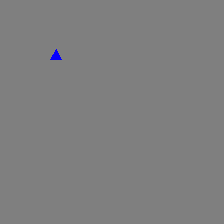


Tempo di risposta: 52.41 secondi
Fine generazione: stop
Token utilizzati: {'completion_tokens': 532, 'prompt_tokens': 99, 'total_tokens': 631, 'prompt_tokens_details': {'cached_tokens': 0}}

Descrizione del modello:
L'immagine mostra uno sfondo grigio uniforme. In alto a sinistra, c'è un piccolo triangolo di colore blu.


In [29]:
#PICCOLO TEST PRELIMINARE

#selezioniamo una singola immagine dal dataset
sample_row = kandy_manifest.iloc[0]

sample_images = json.loads(sample_row["positive_images"])
sample_image_path = KANDY_DIR / sample_images[0]

if not sample_image_path.is_file():
    raise FileNotFoundError(f"Immagine non trovata: {sample_image_path}")


#visualizziamo l'immagine selezionata
print("Problema:", sample_row["problem_id"])
print("Immagine:", sample_image_path)

display(DisplayImage(filename=str(sample_image_path)))


#convertiamo l'immagine in base64
#in questo modo possiamo inserire
#l'immagine sotto forma di testo
#direttamente all'interno del json
#con cui facciamo la richiesta http
mime_type, _ = mimetypes.guess_type(sample_image_path.name)

if not mime_type or not mime_type.startswith("image/"):
    raise ValueError("Formato immagine non riconosciuto.")

image_base64 = base64.b64encode(
    sample_image_path.read_bytes()
).decode("utf-8")

image_data_url = f"data:{mime_type};base64,{image_base64}"


#prepariamo la richiesta multimodale
payload = {
    "model": MODEL_LABEL,
    "messages": [
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": (
                        "Osserva attentamente l'immagine. "
                        "Descrivi brevemente in italiano le forme "
                        "geometriche e i colori che riesci a riconoscere. "
                        "Non inventare elementi non visibili."
                    )
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": image_data_url
                    }
                }
            ]
        }
    ],
    "temperature": TEMPERATURE,
    "top_p": TOP_P,
    "seed": RANDOM_SEED,
    "max_tokens": 1024,
    "stream": False
}

#inviamo la richiesta al modello
start_time = time.perf_counter()

try:
    response = requests.post(
        f"{BASE_URL}/chat/completions",
        json=payload,
        timeout=REQUEST_TIMEOUT
    )

except requests.exceptions.Timeout:
    raise RuntimeError("Timeout durante l'elaborazione dell'immagine.")

except requests.exceptions.ConnectionError:
    raise RuntimeError("Connessione al server interrotta.")


elapsed_time = time.perf_counter() - start_time


#controlliamo la risposta
if response.status_code != 200:
    print("Errore HTTP:", response.status_code)
    print("Risposta del server:", response.text)
    raise RuntimeError("Inferenza multimodale non completata.")


#recuperiamo il risultato
result = response.json()
choices = result.get("choices", [])

if not choices:
    raise RuntimeError(f"Nessuna risposta generata: {result}")

message = choices[0].get("message", {})
raw_response = message.get("content")


#mostriamo i risultati
print("\nTempo di risposta:", round(elapsed_time, 2), "secondi")
print("Fine generazione:", choices[0].get("finish_reason"))
print("Token utilizzati:", result.get("usage"))

if not raw_response or not raw_response.strip():
    print("\nMessaggio completo:", message)
    raise RuntimeError("Il modello non ha restituito testo.")

print("\nDescrizione del modello:")
print(raw_response)

## Primo Test - Induzione della regola

In questo primo esperimento il modello riceve in input una matrice Bongard completa e il l'obiettivo è quello di individuare autonomamente i concetti visivi che caratterizzano i due gruppi e formulare la regola che permette di distinguerli.

Il test viene applicato sia al dataset KANDY Bongard sia a Bongard-RWR+.

In [30]:
#PREPARAZIONE DEI TASK

#carichiamo il catalogo dei concetti kandy
KANDY_CONCEPTS_PATH = PROCESSED_DIR / "metadata" / "concept_comparison_kandy_rwr.csv"

if not KANDY_CONCEPTS_PATH.is_file():
    raise FileNotFoundError("Catalogo dei concetti KANDY non trovato.")

kandy_concepts = pd.read_csv(KANDY_CONCEPTS_PATH)

#recuperiamo un solo concetto per problema
kandy_concepts = kandy_concepts[
    ["problem_id", "kandy_concept"]
].drop_duplicates()

if kandy_concepts["problem_id"].duplicated().any():
    raise ValueError("Sono presenti più concetti per lo stesso problema KANDY.")


#associamo i concetti ai problemi kandy
kandy_test_data = kandy_manifest.merge(
    kandy_concepts,
    on="problem_id",
    how="left",
    validate="one_to_one"
)

if kandy_test_data["kandy_concept"].isna().any():
    raise ValueError("Alcuni problemi KANDY non hanno un concetto di riferimento.")


#selezioniamo i problemi da utilizzare
if RUN_MODE == "pilot":

    if PILOT_LIMIT < 1:
        raise ValueError("PILOT_LIMIT deve essere almeno 1.")

    kandy_test_data = kandy_test_data.head(PILOT_LIMIT)
    rwr_test_data = rwr_manifest.head(PILOT_LIMIT)

elif RUN_MODE == "full":

    rwr_test_data = rwr_manifest.copy()

else:
    raise ValueError("RUN_MODE deve essere pilot oppure full.")


#prepariamo l'elenco dei problemi
test1_tasks = []

for _, row in kandy_test_data.iterrows():

    test1_tasks.append({
        "dataset": "KANDY",
        "problem_id": row["problem_id"],
        "image_path": KANDY_DIR / row["whole_image"],
        "reference": {
            "concept": row["kandy_concept"],
            "positive_side": "left",
            "negative_side": "right"
        }
    })


for _, row in rwr_test_data.iterrows():

    test1_tasks.append({
        "dataset": "RWR+",
        "problem_id": row["profile_id"],
        "image_path": RWR_DIR / row["whole_image"],
        "reference": {
            "left_concept": row["left_concept"],
            "right_concept": row["right_concept"]
        }
    })


#controlliamo i problemi selezionati
for task in test1_tasks:

    if not task["image_path"].is_file():
        raise FileNotFoundError(
            f"Immagine non trovata: {task['image_path']}"
        )

print("Problemi KANDY:", len(kandy_test_data))
print("Problemi RWR+:", len(rwr_test_data))
print("Totale problemi:", len(test1_tasks))

Problemi KANDY: 38
Problemi RWR+: 38
Totale problemi: 76


In [ ]:
#PRIMO TEST

import re
from datetime import datetime


system_prompt = """
You are an expert in visual concept learning and Bongard problems.

Your task is to discover the abstract visual rules that distinguish
two groups of images.

The input is a composite image arranged as a grid of 4 columns
and 3 rows.

The first two columns contain the LEFT group.
The last two columns contain the RIGHT group.

Each group can contain up to six examples.
Some cells may be completely blank because fewer than six
examples are available. Blank cells are empty placeholders
and must be ignored.

Analyze all non-empty examples belonging to each group.

The defining concept is not necessarily the identity or category
of the depicted objects.

It may involve:
- geometric properties
- colors and patterns
- size and area
- number of objects
- shape and orientation
- spatial relationships
- similarity and differences
- presence or absence of specific features

Focus on properties that consistently distinguish the two groups.

Avoid incidental details and superficial descriptions.
Look for the simplest abstract rule that explains all examples.
"""

user_prompt = """
Analyze the attached Bongard matrix.

IMPORTANT LAYOUT:
- The matrix has 4 columns and 3 rows.
- Columns 1 and 2 represent the LEFT group.
- Columns 3 and 4 represent the RIGHT group.
- Each group can contain up to six examples.
- Completely blank white cells are unused placeholders.
  Do not consider them as examples.

Compare all non-empty examples from both groups.

Identify the defining concept of the LEFT group and the
defining concept of the RIGHT group.

Do not simply describe the objects.
Look for the abstract property or relationship that
distinguishes the two groups.

Return exactly two lines:

LEFT_RULE: [defining concept of the left group]
RIGHT_RULE: [defining concept of the right group]

Use one concise sentence for each rule.
Do not include introductory text, explanations or markdown.
"""


#funzione per estrarre le regole dalla risposta
def parse_rules(raw_response):

    text = re.sub(r"```[a-zA-Z]*|```", "", raw_response)

    values = {}
    current_field = None

    for line in text.splitlines():

        line = line.strip().strip("*").strip()
        line = re.sub(r"^[-*]\s*", "", line)

        match = re.match(
            r"^(LEFT[_ ]RULE|RIGHT[_ ]RULE)\s*:\s*(.*)$",
            line,
            re.IGNORECASE
        )

        if match:

            current_field = match.group(1).upper().replace(" ", "_")
            values[current_field] = match.group(2).strip()

        elif current_field and line:

            values[current_field] += " " + line

    #controlliamo che entrambe le regole siano presenti
    left_rule = values.get("LEFT_RULE", "")
    right_rule = values.get("RIGHT_RULE", "")

    if not left_rule or not right_rule:
        return None

    return {
        "left_rule": left_rule,
        "right_rule": right_rule
    }


#recuperiamo il modello caricato nel server
model_response = requests.get(
    f"{BASE_URL}/models",
    timeout=10
)

model_response.raise_for_status()

available_models = model_response.json().get("data", [])

if not available_models:
    raise RuntimeError("Nessun modello disponibile nel server.")

SERVER_MODEL_NAME = available_models[0]["id"]


#prepariamo il file dei risultati
run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

RESULT_FILE = MODEL_RESULTS_DIR / (
    f"test_1_rule_induction_{run_timestamp}.jsonl"
)

records = []


#eseguiamo il test sui problemi selezionati
for index, task in enumerate(test1_tasks, start=1):

    print(
        f"\nProblema {index}/{len(test1_tasks)}: "
        f"{task['dataset']} - {task['problem_id']}"
    )

    start_time = time.perf_counter()
    response = None

    record = {
        "model": ACTIVE_MODEL,
        "dataset": task["dataset"],
        "problem_id": task["problem_id"],
        "image_path": str(task["image_path"].relative_to(PROJECT_ROOT)),
        "reference": task["reference"],
        "thinking_enabled": THINKING_ENABLED,
        "reasoning_budget": THINKING_BUDGET,
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "prompt_version": "v3",
        "raw_response": None,
        "reasoning_response": None,
        "parsed_response": None,
        "status": "pending",
        "finish_reason": None,
        "usage": None,
        "elapsed_seconds": None,
        "semantic_review": "pending"
    }

    try:

        #convertiamo la matrice in base64
        image_data_url = image_to_data_url(task["image_path"])

        #prepariamo la richiesta al modello
        payload = {
            "model": SERVER_MODEL_NAME,
            "messages": [
                {
                    "role": "system",
                    "content": system_prompt
                },
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "image_url",
                            "image_url": {
                                "url": image_data_url
                            }
                        },
                        {
                            "type": "text",
                            "text": user_prompt
                        }
                    ]
                }
            ],
            "temperature": TEMPERATURE,
            "top_p": TOP_P,
            "seed": RANDOM_SEED,
            "max_tokens": MAX_OUTPUT_TOKENS,
            "stream": False
        }

        #inviamo la richiesta al modello
        response = requests.post(
            f"{BASE_URL}/chat/completions",
            json=payload,
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        result = response.json()
        choices = result.get("choices", [])

        if not choices:
            raise ValueError("Il server non ha restituito risposte.")

        message = choices[0].get("message", {})

        raw_response = message.get("content") or ""
        reasoning_response = message.get("reasoning_content") or ""

        #registriamo la risposta originale
        record["raw_response"] = raw_response
        record["reasoning_response"] = reasoning_response
        record["finish_reason"] = choices[0].get("finish_reason")
        record["usage"] = result.get("usage")
        record["timings"] = result.get("timings")

        #controlliamo il formato della risposta
        if not raw_response.strip():

            if reasoning_response:
                record["status"] = "reasoning_without_final"
            else:
                record["status"] = "empty_output"

        else:

            parsed_response = parse_rules(raw_response)

            if parsed_response is None:

                if record["finish_reason"] == "length":
                    record["status"] = "truncated_output"
                else:
                    record["status"] = "invalid_output_format"

            else:

                record["parsed_response"] = parsed_response
                record["status"] = "valid_output"

    except requests.exceptions.Timeout:

        record["status"] = "timeout_error"

    except requests.exceptions.HTTPError as error:

        record["status"] = "http_error"
        record["error"] = (
            response.text[:3000] if response is not None
            else str(error)
        )

    except requests.exceptions.RequestException as error:

        record["status"] = "request_error"
        record["error"] = str(error)

    except Exception as error:

        record["status"] = "execution_error"
        record["error"] = str(error)

    finally:

        record["elapsed_seconds"] = round(
            time.perf_counter() - start_time, 2
        )

        #salviamo ogni risultato
        records.append(record)

        with open(RESULT_FILE, "a", encoding="utf-8") as file:
            file.write(json.dumps(record, ensure_ascii=False) + "\n")

        print("Stato:", record["status"])
        print("Tempo:", record["elapsed_seconds"], "secondi")

        if record["status"] != "valid_output":
            print("Risposta:", record["raw_response"])
            print("Reasoning disponibile:", bool(record["reasoning_response"]))


#mostriamo un riepilogo dei risultati
results_df = pd.DataFrame(records)

display(
    results_df[
        [
            "dataset",
            "problem_id",
            "status",
            "finish_reason",
            "elapsed_seconds"
        ]
    ]
)

print("\nRisultati salvati in:", RESULT_FILE) 

## Primo Test - Risultati

Qwen 3.5 2B: 152 annotazioni caricate da /home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b/review_qwen.jsonl
Gemma 4 E2B-it: 152 annotazioni caricate da /home/cosimo/progetti/tesi/results/vlm_preliminary/gemma4_e2b_it/review_gemma.jsonl

Qwen 3.5 2B: 76 record caricati
File: /home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b/test_1_rule_induction_20261113_223003.jsonl

Gemma 4 E2B-it: 76 record caricati
File: /home/cosimo/progetti/tesi/results/vlm_preliminary/gemma4_e2b_it/test_1_rule_induction_20261114_101700.jsonl


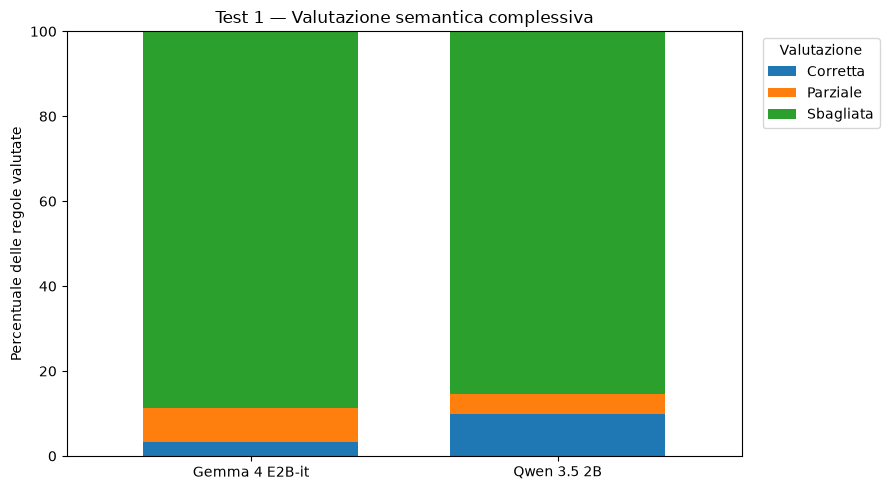

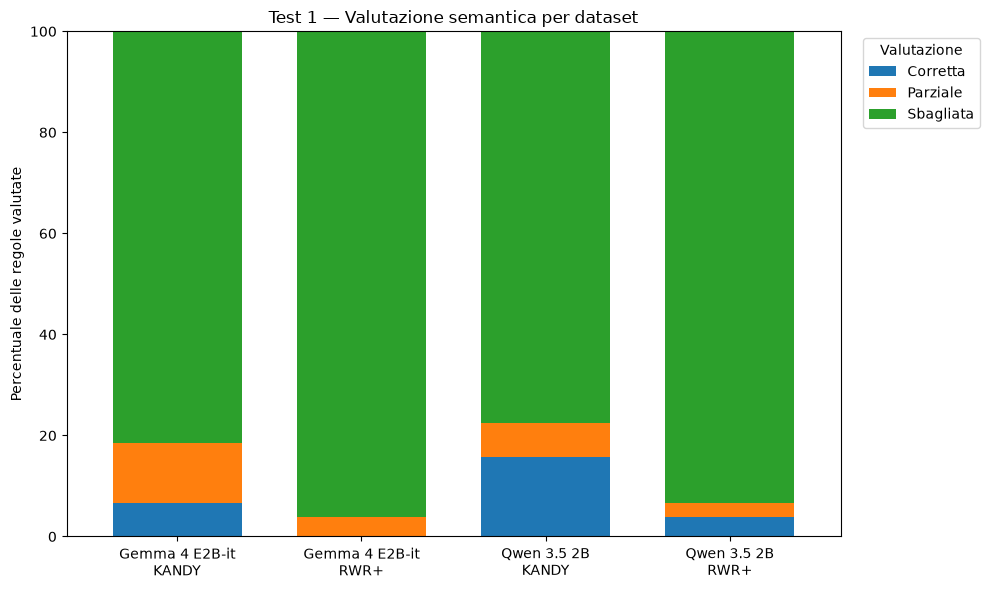

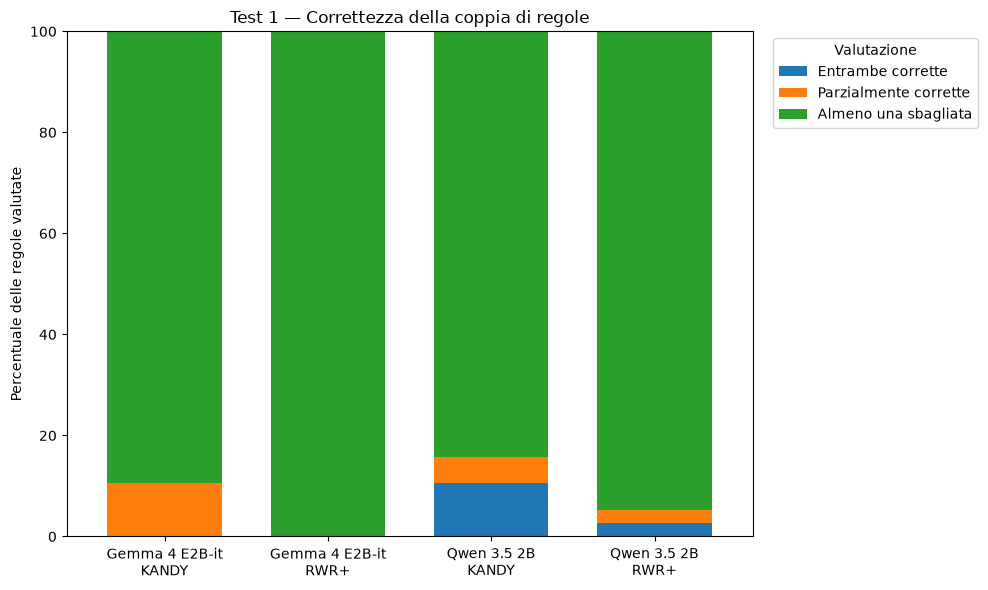

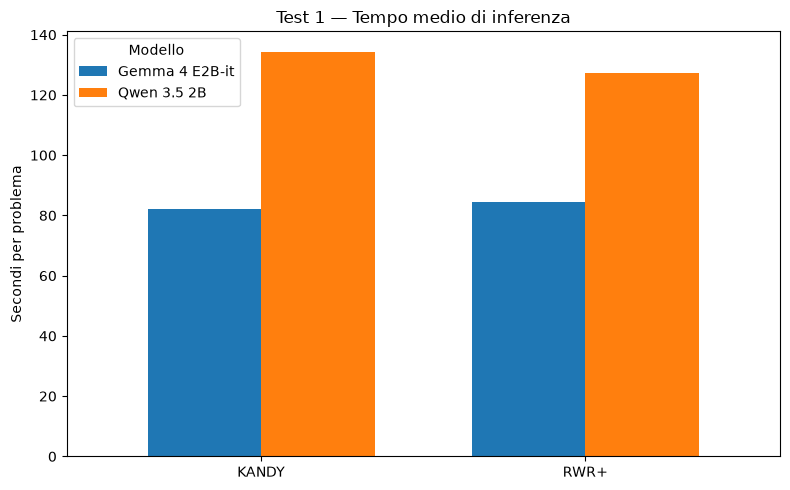

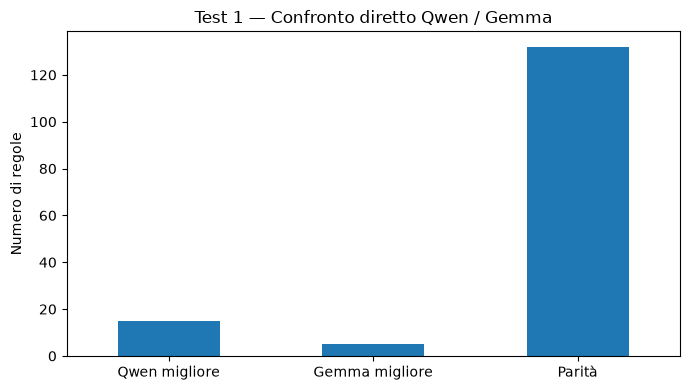


METRICHE SEMANTICHE PER MODELLO


,model_label,regole_totali,regole_valutate,copertura_%,corrette,parziali,sbagliate,corrette_%,parziali_%,sbagliate_%,punteggio_medio
0,Gemma 4 E2B-it,152,152,100.0,5,12,135,3.3,7.9,88.8,0.072
1,Qwen 3.5 2B,152,152,100.0,15,7,130,9.9,4.6,85.5,0.122



METRICHE SEMANTICHE PER DATASET


,model_label,dataset,regole_totali,regole_valutate,copertura_%,corrette,parziali,sbagliate,corrette_%,parziali_%,sbagliate_%,punteggio_medio
0,Gemma 4 E2B-it,KANDY,76,76,100.0,5,9,62,6.6,11.8,81.6,0.125
1,Gemma 4 E2B-it,RWR+,76,76,100.0,0,3,73,0.0,3.9,96.1,0.020
2,Qwen 3.5 2B,KANDY,76,76,100.0,12,5,59,15.8,6.6,77.6,0.191
3,Qwen 3.5 2B,RWR+,76,76,100.0,3,2,71,3.9,2.6,93.4,0.053



METRICHE SEMANTICHE PER LATO


,model_label,dataset,side,regole_totali,regole_valutate,copertura_%,corrette,parziali,sbagliate,corrette_%,parziali_%,sbagliate_%,punteggio_medio
0,Gemma 4 E2B-it,KANDY,left,38,38,100.0,5,5,28,13.2,13.2,73.7,0.197
1,Gemma 4 E2B-it,KANDY,right,38,38,100.0,0,4,34,0.0,10.5,89.5,0.053
2,Gemma 4 E2B-it,RWR+,left,38,38,100.0,0,3,35,0.0,7.9,92.1,0.039
3,Gemma 4 E2B-it,RWR+,right,38,38,100.0,0,0,38,0.0,0.0,100.0,0.000
4,Qwen 3.5 2B,KANDY,left,38,38,100.0,8,3,27,21.1,7.9,71.1,0.250
5,Qwen 3.5 2B,KANDY,right,38,38,100.0,4,2,32,10.5,5.3,84.2,0.132
6,Qwen 3.5 2B,RWR+,left,38,38,100.0,2,1,35,5.3,2.6,92.1,0.066
7,Qwen 3.5 2B,RWR+,right,38,38,100.0,1,1,36,2.6,2.6,94.7,0.039


... (3 outputs left out)

,model,dataset,record,output_validi_%,tempo_medio_s,tempo_mediano_s,tempo_totale_min,completion_token_medi,token_s_medi
0,Qwen 3.5 2B,KANDY,38,97.4,134.41,147.27,85.12,578.4,8.68
1,Qwen 3.5 2B,RWR+,38,97.4,127.22,135.69,80.57,574.7,10.01
2,Gemma 4 E2B-it,KANDY,38,100.0,82.20,77.33,52.06,574.8,9.63
3,Gemma 4 E2B-it,RWR+,38,100.0,84.56,84.29,53.55,575.2,9.31



CONFRONTO DIRETTO QWEN / GEMMA


comparison
Parità            132
Qwen migliore      15
Gemma migliore      5
Name: count, dtype: int64


File salvati in: /home/cosimo/progetti/tesi/results/vlm_preliminary/test1_comparison


In [13]:
#METRICHE COMPARATIVE PRIMO TEST: QWEN E GEMMA

#configurazione
MODEL_LABELS = {
    "qwen35_2b": "Qwen 3.5 2B",
    "gemma4_e2b_it": "Gemma 4 E2B-it"
}

#se necessario, indicare il percorso completo dei JSONL dei risultati
RUN_FILES = {
    "qwen35_2b": None,
    "gemma4_e2b_it": None
}

#cartella principale dei risultati
if "RESULTS_ROOT" in globals():
    RESULTS_DIR = Path(RESULTS_ROOT)
elif "PROJECT_ROOT" in globals():
    RESULTS_DIR = Path(PROJECT_ROOT) / "results" / "vlm_preliminary"
else:
    RESULTS_DIR = Path.cwd() / "results" / "vlm_preliminary"

if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f"Cartella risultati non trovata: {RESULTS_DIR}")


#percorsi dei file di revisione
REVIEW_FILES = {
    "qwen35_2b": RESULTS_DIR / "qwen35_2b" / "review_qwen.jsonl",
    "gemma4_e2b_it": RESULTS_DIR / "gemma4_e2b_it" / "review_gemma.jsonl"
}

#cartella in cui salveremo tabelle e grafici
OUTPUT_DIR = RESULTS_DIR / "test1_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


#lettura jsonl
def leggi_jsonl(path):
    records = []

    with Path(path).open("r", encoding="utf-8") as file:
        for numero, line in enumerate(file, start=1):
            if not line.strip():
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"JSON non valido in {Path(path).name}, riga {numero}: {exc}"
                )

    return records


#normalizzazione dei valori
def normalizza(value):
    return str(value or "").strip().lower()


def path_key(value):
    return str(Path(str(value)).expanduser().resolve())


#controlliamo i file delle revisioni
for model_key, path in REVIEW_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"File di revisione non trovato per {model_key}: {path}"
        )


#carichiamo le revisioni separatamente per modello
revisioni = {}

for model_key, path in REVIEW_FILES.items():
    records = leggi_jsonl(path)

    revisioni[model_key] = pd.DataFrame(records)

    print(
        f"{MODEL_LABELS[model_key]}: "
        f"{len(records)} annotazioni caricate da {path}"
    )


#individuazione dei file dei risultati
def trova_run(model_key):
    explicit = RUN_FILES.get(model_key)

    if explicit is not None:
        path = Path(explicit).expanduser().resolve()

        if not path.is_file():
            raise FileNotFoundError(path)

        return path

    model_dir = RESULTS_DIR / model_key

    if not model_dir.is_dir():
        raise FileNotFoundError(
            f"Cartella dei risultati non trovata: {model_dir}"
        )

    candidates = list(
        model_dir.rglob("test_1_rule_induction*.jsonl")
    )

    if not candidates:
        raise FileNotFoundError(
            f"Nessun JSONL del Test 1 trovato in {model_dir}"
        )

    #recuperiamo i percorsi dei risultati annotati
    review_df = revisioni[model_key]

    reviewed_sources = set()

    if "source_jsonl" in review_df.columns:
        reviewed_sources = {
            str(value).strip()
            for value in review_df["source_jsonl"].dropna()
        }

    #cerchiamo il file indicato nelle annotazioni
    matched = []

    for candidate in candidates:
        candidate_path = path_key(candidate)

        candidate_names = {
            candidate.name,
            candidate_path
        }

        if any(
            source in candidate_names or Path(source).name == candidate.name
            for source in reviewed_sources
        ):
            matched.append(candidate.resolve())

    matched = list(set(matched))

    if len(matched) == 1:
        return matched[0]

    preferred = [
        path for path in candidates
        if path.name == "test_1_rule_induction.jsonl"
    ]

    if len(preferred) == 1:
        return preferred[0].resolve()

    if len(candidates) == 1:
        return candidates[0].resolve()

    raise RuntimeError(
        f"Ho trovato più JSONL per {model_key} e non riesco "
        "a individuare con certezza quello revisionato.\n"
        "Imposta RUN_FILES con il percorso del risultato corretto:\n" +
        "\n".join(str(p) for p in candidates)
    )


run_paths = {
    model: trova_run(model)
    for model in MODEL_LABELS
}


#carichiamo i risultati
runs = {}

for model_key, path in run_paths.items():
    records = leggi_jsonl(path)

    #controlliamo che il modello registrato sia quello atteso
    models_found = {
        normalizza(record.get("model"))
        for record in records
    }

    if model_key not in models_found:
        raise ValueError(
            f"Il file {path.name} non contiene risultati "
            f"registrati come {model_key}. Modelli trovati: {models_found}"
        )

    runs[model_key] = records

    print(
        f"\n{MODEL_LABELS[model_key]}: "
        f"{len(records)} record caricati"
    )
    print("File:", path)


#unifichiamo i giudizi
ASSESSMENTS = {
    "correct": "correct",
    "corretta": "correct",
    "partial": "partial",
    "parzialmente corretta": "partial",
    "incorrect": "incorrect",
    "sbagliata": "incorrect"
}


#ricerca della revisione associata a un problema e a un lato
def cerca_revisione(model_key, source_path, dataset, problem_id, side):

    df = revisioni[model_key]

    campi_obbligatori = [
        "dataset", "problem_id", "side", "assessment"
    ]

    mancanti = [
        col for col in campi_obbligatori
        if col not in df.columns
    ]

    if mancanti:
        raise ValueError(
            f"Nel file {REVIEW_FILES[model_key].name} "
            f"mancano questi campi: {mancanti}"
        )

    matches = df[
        (df["dataset"].apply(normalizza) == normalizza(dataset)) &
        (df["problem_id"].apply(normalizza) == normalizza(problem_id)) &
        (df["side"].apply(normalizza) == normalizza(side))
    ].copy()

    if matches.empty:
        return {}

    #prima proviamo a identificare il JSONL esatto
    if "source_jsonl" in matches.columns:
        exact = matches[
            matches["source_jsonl"].apply(
                lambda x: path_key(x) == path_key(source_path)
            )
        ]

        if not exact.empty:
            matches = exact
        else:
            #fallback sul nome del file
            same_name = matches[
                matches["source_jsonl"].apply(
                    lambda x: Path(str(x)).name == Path(source_path).name
                )
            ]

            if not same_name.empty:
                matches = same_name

    #se esistono più annotazioni, manteniamo l'ultima
    if "updated_at" in matches.columns:
        matches = matches.sort_values("updated_at")

    return matches.iloc[-1].to_dict()


#recuperiamo la regola di riferimento
def inverti_concetto(concept):
    concept = str(concept or "").strip()

    for old, new in [
        ("Presenza di ", "Assenza di "),
        ("Presenza ", "Assenza "),
        ("presenza di ", "assenza di "),
        ("presenza ", "assenza "),
        ("Presence of ", "Absence of "),
        ("Presence ", "Absence "),
        ("presence of ", "absence of "),
        ("presence ", "absence ")
    ]:
        if concept.startswith(old):
            return new + concept[len(old):]

    return f"Assenza del concetto: {concept}" if concept else ""


def regola_riferimento(record, side):
    reference = record.get("reference") or {}
    dataset = normalizza(record.get("dataset"))

    if isinstance(reference, dict):

        #se sono già presenti entrambe le regole
        left = reference.get("left_rule") or reference.get("left_concept")
        right = reference.get("right_rule") or reference.get("right_concept")

        if left or right:
            return str(left if side == "left" else right or "").strip()

        #struttura usata per KANDY
        concept = str(reference.get("concept", "")).strip()

        if concept:
            positive = normalizza(reference.get("positive_side", "left"))

            if side == positive:
                return concept

            return inverti_concetto(concept)

    #struttura di fallback per RWR+
    key = "left_concept" if side == "left" else "right_concept"

    return str(reference.get(key, "")).strip()


#recuperiamo la regola prodotta dal modello
def regola_modello(record, side):
    parsed = record.get("parsed_response") or {}

    if isinstance(parsed, dict):
        value = parsed.get(f"{side}_rule")

        if value:
            return str(value).strip()

    raw = str(record.get("raw_response") or "")

    pattern = rf"(?im)^\s*{side.upper()}_RULE\s*:\s*(.*?)\s*$"
    match = re.search(pattern, raw)

    return match.group(1).strip() if match else ""


#costruiamo il dataset delle revisioni
rows = []

for model_key, records in runs.items():

    source_path = run_paths[model_key]

    for record in records:

        dataset = record.get("dataset", "")
        problem_id = record.get("problem_id", "")

        for side in ["left", "right"]:

            annotation = cerca_revisione(
                model_key,
                source_path,
                dataset,
                problem_id,
                side
            )

            assessment = ASSESSMENTS.get(
                normalizza(annotation.get("assessment")),
                "not_reviewed"
            )

            reference_rule = (
                annotation.get("reference_rule")
                or regola_riferimento(record, side)
            )

            model_rule = (
                annotation.get("model_rule")
                or regola_modello(record, side)
            )

            rows.append({
                "model": model_key,
                "model_label": MODEL_LABELS[model_key],
                "dataset": dataset,
                "problem_id": problem_id,
                "side": side,
                "assessment": assessment,
                "reference_rule": reference_rule,
                "model_rule": model_rule,
                "notes": annotation.get("notes", ""),
                "status": record.get("status", ""),
                "elapsed_seconds": record.get("elapsed_seconds"),
                "raw_response": record.get("raw_response", ""),
                "source_jsonl": str(source_path)
            })


dettaglio = pd.DataFrame(rows)

if dettaglio.empty:
    raise ValueError("Non sono stati costruiti record da analizzare.")


#assegniamo un punteggio numerico ai giudizi
dettaglio["score"] = dettaglio["assessment"].map({
    "correct": 1.0,
    "partial": 0.5,
    "incorrect": 0.0
})


#riepilogo semantico delle singole regole
def riepilogo_semantico(df, gruppi):

    output = []

    categorie = ["correct", "partial", "incorrect"]

    for keys, frame in df.groupby(gruppi, dropna=False):

        if not isinstance(keys, tuple):
            keys = (keys,)

        valutate = frame[
            frame["assessment"].isin(categorie)
        ]

        n_totali = len(frame)
        n_valutate = len(valutate)

        counts = valutate["assessment"].value_counts()

        row = dict(zip(gruppi, keys))

        row.update({
            "regole_totali": n_totali,
            "regole_valutate": n_valutate,
            "copertura_%": round(
                n_valutate / n_totali * 100, 1
            ) if n_totali else np.nan,
            "corrette": int(counts.get("correct", 0)),
            "parziali": int(counts.get("partial", 0)),
            "sbagliate": int(counts.get("incorrect", 0)),
            "corrette_%": round(
                counts.get("correct", 0) / n_valutate * 100, 1
            ) if n_valutate else np.nan,
            "parziali_%": round(
                counts.get("partial", 0) / n_valutate * 100, 1
            ) if n_valutate else np.nan,
            "sbagliate_%": round(
                counts.get("incorrect", 0) / n_valutate * 100, 1
            ) if n_valutate else np.nan,
            "punteggio_medio": round(
                valutate["score"].mean(), 3
            ) if n_valutate else np.nan
        })

        output.append(row)

    return pd.DataFrame(output)


metriche_modello = riepilogo_semantico(
    dettaglio, ["model_label"]
)

metriche_dataset = riepilogo_semantico(
    dettaglio, ["model_label", "dataset"]
)

metriche_lato = riepilogo_semantico(
    dettaglio, ["model_label", "dataset", "side"]
)


#valutazione della coppia di regole per problema
def valuta_problema(gruppo):

    giudizi = dict(zip(gruppo["side"], gruppo["assessment"]))

    left = giudizi.get("left", "not_reviewed")
    right = giudizi.get("right", "not_reviewed")

    if left not in ASSESSMENTS.values() or right not in ASSESSMENTS.values():
        return "incomplete"

    if left == "correct" and right == "correct":
        return "fully_correct"

    if "incorrect" in [left, right]:
        return "incorrect"

    return "partially_correct"


problemi_rows = []

for (model, label, dataset, problem_id), gruppo in dettaglio.groupby(
    ["model", "model_label", "dataset", "problem_id"],
    dropna=False
):
    problemi_rows.append({
        "model": model,
        "model_label": label,
        "dataset": dataset,
        "problem_id": problem_id,
        "problem_assessment": valuta_problema(gruppo)
    })

problemi = pd.DataFrame(problemi_rows)


#riepilogo della correttezza delle coppie
def riepilogo_problemi(df):

    rows = []

    categorie = [
        "fully_correct",
        "partially_correct",
        "incorrect"
    ]

    for (model, dataset), frame in df.groupby(
        ["model_label", "dataset"], dropna=False
    ):

        valutati = frame[
            frame["problem_assessment"].isin(categorie)
        ]

        counts = valutati["problem_assessment"].value_counts()
        n = len(valutati)

        rows.append({
            "model": model,
            "dataset": dataset,
            "problemi_totali": len(frame),
            "problemi_valutati": n,
            "incompleti": int(
                frame["problem_assessment"].eq("incomplete").sum()
            ),
            "entrambi_corretti": int(counts.get("fully_correct", 0)),
            "parzialmente_corretti": int(counts.get("partially_correct", 0)),
            "almeno_una_sbagliata": int(counts.get("incorrect", 0)),
            "entrambi_corretti_%": round(
                counts.get("fully_correct", 0) / n * 100, 1
            ) if n else np.nan,
            "parzialmente_corretti_%": round(
                counts.get("partially_correct", 0) / n * 100, 1
            ) if n else np.nan,
            "almeno_una_sbagliata_%": round(
                counts.get("incorrect", 0) / n * 100, 1
            ) if n else np.nan
        })

    return pd.DataFrame(rows)


metriche_problemi = riepilogo_problemi(problemi)


#metriche tecniche e tempi
tecniche = []

for model_key, records in runs.items():

    frame = pd.DataFrame(records)

    for dataset, gruppo in frame.groupby("dataset", dropna=False):

        elapsed = pd.to_numeric(
            gruppo["elapsed_seconds"], errors="coerce"
        )

        validi = int(gruppo["status"].eq("valid_output").sum())
        n = len(gruppo)

        completion = gruppo["usage"].apply(
            lambda x: x.get("completion_tokens")
            if isinstance(x, dict) else np.nan
        )

        timings = gruppo["timings"].apply(
            lambda x: x.get("predicted_per_second")
            if isinstance(x, dict) else np.nan
        )

        tecniche.append({
            "model": MODEL_LABELS[model_key],
            "dataset": dataset,
            "record": n,
            "output_validi_%": round(validi / n * 100, 1) if n else np.nan,
            "tempo_medio_s": round(elapsed.mean(), 2),
            "tempo_mediano_s": round(elapsed.median(), 2),
            "tempo_totale_min": round(elapsed.sum() / 60, 2),
            "completion_token_medi": round(
                pd.to_numeric(completion, errors="coerce").mean(), 1
            ),
            "token_s_medi": round(
                pd.to_numeric(timings, errors="coerce").mean(), 2
            )
        })

metriche_tecniche = pd.DataFrame(tecniche)


#confronto diretto sui problemi valutati da entrambi
dettaglio_paired = dettaglio[
    dettaglio["assessment"].isin(["correct", "partial", "incorrect"])
].copy()

paired = dettaglio_paired.pivot_table(
    index=["dataset", "problem_id", "side"],
    columns="model",
    values="score",
    aggfunc="last"
).reset_index()

confronto_modelli = pd.DataFrame()

if {"qwen35_2b", "gemma4_e2b_it"}.issubset(paired.columns):

    valid_pairs = paired.dropna(
        subset=["qwen35_2b", "gemma4_e2b_it"]
    ).copy()

    valid_pairs["comparison"] = np.select(
        [
            valid_pairs["qwen35_2b"] > valid_pairs["gemma4_e2b_it"],
            valid_pairs["qwen35_2b"] < valid_pairs["gemma4_e2b_it"]
        ],
        ["Qwen migliore", "Gemma migliore"],
        default="Parità"
    )

    confronto_modelli = valid_pairs.copy()


#visualizzazioni
CATEGORIES = ["correct", "partial", "incorrect"]

CATEGORY_LABELS = {
    "correct": "Corretta",
    "partial": "Parziale",
    "incorrect": "Sbagliata"
}


def tabella_percentuali(df, index_columns):

    frame = df[df["assessment"].isin(CATEGORIES)]

    if frame.empty:
        return pd.DataFrame()

    table = (
        frame.groupby(index_columns + ["assessment"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=CATEGORIES, fill_value=0)
    )

    table = table.div(
        table.sum(axis=1).replace(0, np.nan),
        axis=0
    ) * 100

    return table.rename(columns=CATEGORY_LABELS)


def grafico_stacked(table, title, filename, figsize=(9, 5)):

    if table.empty:
        print(f"Grafico non prodotto: {title}")
        return

    fig, ax = plt.subplots(figsize=figsize)

    table.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        width=0.7
    )

    ax.set_title(title)
    ax.set_ylabel("Percentuale delle regole valutate")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(
        title="Valutazione",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


#1 distribuzione complessiva dei giudizi
overall_table = tabella_percentuali(
    dettaglio, ["model_label"]
)

grafico_stacked(
    overall_table,
    "Test 1 — Valutazione semantica complessiva",
    "01_valutazione_semantica_totale.png"
)


#2 confronto per dataset
dataset_table = tabella_percentuali(
    dettaglio, ["model_label", "dataset"]
)

if not dataset_table.empty:
    dataset_table.index = [
        f"{model}\n{dataset}"
        for model, dataset in dataset_table.index
    ]

grafico_stacked(
    dataset_table,
    "Test 1 — Valutazione semantica per dataset",
    "02_valutazione_semantica_dataset.png",
    figsize=(10, 6)
)


#3 correttezza complessiva della coppia di regole
pair_categories = [
    "fully_correct",
    "partially_correct",
    "incorrect"
]

pair_labels = {
    "fully_correct": "Entrambe corrette",
    "partially_correct": "Parzialmente corrette",
    "incorrect": "Almeno una sbagliata"
}

pair_table = (
    problemi[
        problemi["problem_assessment"].isin(pair_categories)
    ]
    .groupby(["model_label", "dataset", "problem_assessment"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=pair_categories, fill_value=0)
)

if not pair_table.empty:

    pair_table = pair_table.div(
        pair_table.sum(axis=1).replace(0, np.nan),
        axis=0
    ) * 100

    pair_table = pair_table.rename(columns=pair_labels)

    pair_table.index = [
        f"{model}\n{dataset}"
        for model, dataset in pair_table.index
    ]

grafico_stacked(
    pair_table,
    "Test 1 — Correttezza della coppia di regole",
    "03_correttezza_coppia_regole.png",
    figsize=(10, 6)
)


#4 confronto dei tempi medi di inferenza
if not metriche_tecniche.empty:

    time_table = metriche_tecniche.pivot(
        index="dataset",
        columns="model",
        values="tempo_medio_s"
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    time_table.plot(
        kind="bar",
        ax=ax,
        width=0.7
    )

    ax.set_title("Test 1 — Tempo medio di inferenza")
    ax.set_ylabel("Secondi per problema")
    ax.set_xlabel("")
    ax.legend(title="Modello")
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "04_tempi_inferenza.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


#5 confronto diretto sui problemi comuni
if not confronto_modelli.empty:

    counts = confronto_modelli["comparison"].value_counts()

    fig, ax = plt.subplots(figsize=(7, 4))

    counts.reindex(
        ["Qwen migliore", "Gemma migliore", "Parità"],
        fill_value=0
    ).plot(kind="bar", ax=ax)

    ax.set_title("Test 1 — Confronto diretto Qwen / Gemma")
    ax.set_ylabel("Numero di regole")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "05_confronto_diretto_modelli.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)


#salvataggio delle tabelle
dettaglio.to_csv(
    OUTPUT_DIR / "test1_revisioni_dettaglio.csv",
    index=False
)

metriche_modello.to_csv(
    OUTPUT_DIR / "test1_metriche_per_modello.csv",
    index=False
)

metriche_dataset.to_csv(
    OUTPUT_DIR / "test1_metriche_per_dataset.csv",
    index=False
)

metriche_lato.to_csv(
    OUTPUT_DIR / "test1_metriche_per_lato.csv",
    index=False
)

problemi.to_csv(
    OUTPUT_DIR / "test1_valutazione_problemi.csv",
    index=False
)

metriche_problemi.to_csv(
    OUTPUT_DIR / "test1_metriche_coppie.csv",
    index=False
)

metriche_tecniche.to_csv(
    OUTPUT_DIR / "test1_metriche_tecniche.csv",
    index=False
)

confronto_modelli.to_csv(
    OUTPUT_DIR / "test1_confronto_diretto.csv",
    index=False
)


#riepilogo finale
print("\nMETRICHE SEMANTICHE PER MODELLO")
display(metriche_modello)

print("\nMETRICHE SEMANTICHE PER DATASET")
display(metriche_dataset)

print("\nMETRICHE SEMANTICHE PER LATO")
display(metriche_lato)

print("\nCORRETTEZZA DELLE COPPIE DI REGOLE")
display(metriche_problemi)

print("\nMETRICHE TECNICHE")
display(metriche_tecniche)

if not confronto_modelli.empty:
    print("\nCONFRONTO DIRETTO QWEN / GEMMA")
    display(confronto_modelli["comparison"].value_counts())

print("\nFile salvati in:", OUTPUT_DIR)

## Secondo Test - Applicazione della Regola

In questo secondo esperimento si verifica se il modello sia in grado di applicare una regola già nota a una singola immagine; a differenza del primo test, in cui il modello deve capire le regole che distinguono i due gruppi in modo autonomo, in questo esso riceve entrambe le regole corrette.

Il modello riceve dunque:
- una singola immagine;
- la regola che caratterizza il gruppo LEFT;
- la regola che caratterizza il gruppo RIGHT.

Il compito è quello di stabilire a quale dei due gruppi appartenga l'immagine, restituendo esclusivamente "LEFT" oppure "RIGHT".

In [12]:
#PREPARAZIONE DEI TASK DEL SECONDO TEST

import random

#configurazione del campione
TEST2_IMAGES_PER_DATASET = 25
TEST2_PAIRED_PROBLEMS = 12

#selezione casuale riproducibile
test2_rng = random.Random(RANDOM_SEED)


#leggiamo gli elenchi di immagini dagli indici
def parse_image_list(value):

    if isinstance(value, list):
        paths = value

    elif pd.isna(value) or str(value).strip() == "":
        return []

    else:
        paths = json.loads(value)

    if not isinstance(paths, list):
        raise ValueError(
            "Il manifest deve contenere un elenco di immagini."
        )

    return [
        (index, str(path).strip())
        for index, path in enumerate(paths)
        if path is not None and str(path).strip()
    ]


#definiamo le due regole dei problemi KANDY
def kandy_rules(concept):

    concept = str(concept).strip()

    if not concept:
        raise ValueError("Concetto KANDY vuoto.")

    #siccome kandy ha una regola esplicita solo per il lato sinistro
    #utilizziamo l'assenza della regola come regola del lato destro
    prefixes = [
        ("Presence of ", "Absence of "),
        ("Presence ", "Absence "),
        ("Presenza di ", "Assenza di "),
        ("Presenza ", "Assenza ")
    ]

    for positive_prefix, negative_prefix in prefixes:

        if concept.lower().startswith(positive_prefix.lower()):
            negative_rule = (
                negative_prefix + concept[len(positive_prefix):]
            )
            break

    else:
        #negazione descrittiva per gli altri concetti
        negative_rule = (
            f"Does not satisfy the following pattern: {concept}"
        )

    return {
        "left": concept,
        "right": negative_rule
    }


#prepariamo i problemi KANDY disponibili
def prepara_kandy_problems():

    problems = []

    for _, row in kandy_test_data.iterrows():

        problem_id = str(row["problem_id"])
        rules = kandy_rules(row["kandy_concept"])

        images = {
            "left": parse_image_list(row["positive_images"]),
            "right": parse_image_list(row["negative_images"])
        }

        if not images["left"] or not images["right"]:
            continue

        problems.append({
            "problem_id": problem_id,
            "rules": rules,
            "images": images
        })

    return problems


#prepariamo i profili RWR+ disponibili
def prepara_rwr_problems():

    problems = []

    for _, row in rwr_test_data.iterrows():

        problem_id = str(row["profile_id"])

        rules = {
            "left": str(row["left_concept"]).strip(),
            "right": str(row["right_concept"]).strip()
        }

        if not rules["left"] or not rules["right"]:
            continue

        images = {
            "left": parse_image_list(row["left_context"]),
            "right": parse_image_list(row["right_context"])
        }

        if not images["left"] or not images["right"]:
            continue

        problems.append({
            "problem_id": problem_id,
            "rules": rules,
            "images": images
        })

    return problems


#carichiamo i problemi dei due dataset
available_problems = {
    "KANDY": prepara_kandy_problems(),
    "RWR+": prepara_rwr_problems()
}


#selezioniamo 12 problemi con entrambi i lati disponibili
#e un tredicesimo problema per l'immagine aggiuntiva
def seleziona_problemi(dataset, problems, extra_side):

    if len(problems) < TEST2_PAIRED_PROBLEMS + 1:
        raise ValueError(
            f"{dataset}: servono almeno "
            f"{TEST2_PAIRED_PROBLEMS + 1} problemi disponibili."
        )

    shuffled = problems.copy()
    test2_rng.shuffle(shuffled)

    paired = shuffled[:TEST2_PAIRED_PROBLEMS]
    remaining = shuffled[TEST2_PAIRED_PROBLEMS:]

    #il problema aggiuntivo deve avere immagini sul lato richiesto
    extra_candidates = [
        problem for problem in remaining
        if problem["images"][extra_side]
    ]

    if not extra_candidates:
        raise ValueError(
            f"{dataset}: nessun problema disponibile "
            f"per l'immagine aggiuntiva sul lato {extra_side}."
        )

    extra_problem = test2_rng.choice(extra_candidates)

    return paired, extra_problem


#selezione bilanciata:
#KANDY riceve un'immagine aggiuntiva LEFT
#RWR+ riceve un'immagine aggiuntiva RIGHT
selected_problems = {}

for dataset, problems in available_problems.items():

    extra_side = "left" if dataset == "KANDY" else "right"

    paired, extra = seleziona_problemi(
        dataset,
        problems,
        extra_side
    )

    selected_problems[dataset] = {
        "paired": paired,
        "extra": extra,
        "extra_side": extra_side
    }


#aggiungiamo le singole prove
IMAGE_TASKS = []


def aggiungi_immagine(dataset, problem, image_side, image_item):

    image_index, relative_path = image_item

    folder = KANDY_DIR if dataset == "KANDY" else RWR_DIR
    image_path = folder / relative_path

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Immagine {dataset} non trovata: {image_path}"
        )

    #ogni immagine viene confrontata con entrambe le regole
    for rule_side in ["left", "right"]:

        IMAGE_TASKS.append({
            "task_id": (
                f"apply::{dataset}::{problem['problem_id']}::"
                f"{image_side}::{image_index:02d}::{rule_side}"
            ),
            "test": "test_2_rule_application",
            "dataset": dataset,
            "problem_id": problem["problem_id"],
            "image_side": image_side,
            "image_index": image_index,
            "image_path": image_path,
            "rule_side": rule_side,
            "rule_text": problem["rules"][rule_side],

            "correct_answer": (
                "YES" if image_side == rule_side else "NO"
            )
        })


#creiamo le prove per i due dataset
for dataset, selection in selected_problems.items():

    #12 problemi: un'immagine per ciascun lato
    for problem in selection["paired"]:

        for image_side in ["left", "right"]:

            selected_image = test2_rng.choice(
                problem["images"][image_side]
            )

            aggiungi_immagine(
                dataset,
                problem,
                image_side,
                selected_image
            )

    #un tredicesimo problema: una sola immagine
    extra_problem = selection["extra"]
    extra_side = selection["extra_side"]

    selected_image = test2_rng.choice(
        extra_problem["images"][extra_side]
    )

    aggiungi_immagine(
        dataset,
        extra_problem,
        extra_side,
        selected_image
    )


#creiamo il dataframe delle prove
test2_tasks_df = pd.DataFrame(IMAGE_TASKS)

TEST2_TASKS = test2_tasks_df.to_dict("records")


#controlli di coerenza
if len(TEST2_TASKS) != 100:
    raise ValueError(
        f"Attese 100 richieste, trovate {len(TEST2_TASKS)}."
    )

if test2_tasks_df["task_id"].duplicated().any():
    raise ValueError("Sono presenti task duplicati.")

if not test2_tasks_df["image_path"].apply(
    lambda path: Path(path).is_file()
).all():
    raise FileNotFoundError("Una o più immagini non sono disponibili.")

if test2_tasks_df["correct_answer"].value_counts().to_dict() != {
    "YES": 50,
    "NO": 50
}:
    raise ValueError("Le risposte attese YES/NO non sono bilanciate.")


#riepilogo
print("\nRIEPILOGO DEL SECONDO TEST")
print("Richieste per modello:", len(TEST2_TASKS))
print("Richieste totali per due modelli:", len(TEST2_TASKS) * 2)

print("\nImmagini selezionate per dataset:")
display(
    test2_tasks_df
    .groupby(["dataset", "image_side"])
    .agg(
        immagini=("task_id", "count"),
        problemi=("problem_id", "nunique")
    )
)

print("\nDistribuzione delle risposte attese:")
display(
    test2_tasks_df
    .groupby(["dataset", "correct_answer"])
    .size()
    .unstack(fill_value=0)
)

print("\nProblemi selezionati:")
display(
    pd.DataFrame([
        {
            "dataset": dataset,
            "problem_id": problem["problem_id"],
            "tipo": "paired"
        }
        for dataset, selection in selected_problems.items()
        for problem in selection["paired"]
    ] + [
        {
            "dataset": dataset,
            "problem_id": selection["extra"]["problem_id"],
            "tipo": f"extra_{selection['extra_side']}"
        }
        for dataset, selection in selected_problems.items()
    ])
)

print("\nAnteprima delle prove:")
display(
    test2_tasks_df[
        [
            "task_id",
            "dataset",
            "problem_id",
            "image_side",
            "rule_side",
            "rule_text",
            "correct_answer",
            "image_path"
        ]
    ].head(12)
)


RIEPILOGO DEL SECONDO TEST
Richieste per modello: 100
Richieste totali per due modelli: 200

Immagini selezionate per dataset:


immagini  problemi
dataset image_side                    
KANDY   left              26        13
        right             24        12
RWR+    left              24        12
        right             26        13


Distribuzione delle risposte attese:


correct_answer,NO,YES
dataset,,
KANDY,25,25
RWR+,25,25



Problemi selezionati:


,dataset,problem_id,tipo
0,KANDY,easy-11,paired
1,KANDY,hard-13,paired
2,KANDY,easy-10,paired
3,KANDY,hard-12,paired
4,KANDY,hard-14,paired
5,KANDY,hard-9,paired
6,KANDY,easy-12,paired
7,KANDY,easy-5,paired
8,KANDY,hard-5,paired
9,KANDY,hard-10,paired



Anteprima delle prove:


,task_id,dataset,problem_id,image_side,rule_side,rule_text,correct_answer,image_path
0,apply::KANDY::easy-11::left::05::left,KANDY,easy-11,left,left,Triangolo rosso all'estrema destra e presenza ...,YES,/home/cosimo/progetti/tesi/data/processed/data...
1,apply::KANDY::easy-11::left::05::right,KANDY,easy-11,left,right,Does not satisfy the following pattern: Triang...,NO,/home/cosimo/progetti/tesi/data/processed/data...
2,apply::KANDY::easy-11::right::01::left,KANDY,easy-11,right,left,Triangolo rosso all'estrema destra e presenza ...,NO,/home/cosimo/progetti/tesi/data/processed/data...
3,apply::KANDY::easy-11::right::01::right,KANDY,easy-11,right,right,Does not satisfy the following pattern: Triang...,YES,/home/cosimo/progetti/tesi/data/processed/data...
4,apply::KANDY::hard-13::left::01::left,KANDY,hard-13,left,left,Pseudo-palindromi,YES,/home/cosimo/progetti/tesi/data/processed/data...
5,apply::KANDY::hard-13::left::01::right,KANDY,hard-13,left,right,Does not satisfy the following pattern: Pseudo...,NO,/home/cosimo/progetti/tesi/data/processed/data...
6,apply::KANDY::hard-13::right::03::left,KANDY,hard-13,right,left,Pseudo-palindromi,NO,/home/cosimo/progetti/tesi/data/processed/data...
7,apply::KANDY::hard-13::right::03::right,KANDY,hard-13,right,right,Does not satisfy the following pattern: Pseudo...,YES,/home/cosimo/progetti/tesi/data/processed/data...
8,apply::KANDY::easy-10::left::03::left,KANDY,easy-10,left,left,Triangolo rosso all'estrema destra con più ogg...,YES,/home/cosimo/progetti/tesi/data/processed/data...
9,apply::KANDY::easy-10::left::03::right,KANDY,easy-10,left,right,Does not satisfy the following pattern: Triang...,NO,/home/cosimo/progetti/tesi/data/processed/data...


In [ ]:
#SECONDO TEST - APPLICAZIONE DELLA REGOLA

import re
from datetime import datetime


#prompt di sistema
system_prompt_test2 = """
You are an expert in visual concept recognition and Bongard problems.

Your task is to determine whether a single image satisfies
a given visual concept.

You will receive:
- one image
- one visual rule

Carefully inspect the image and compare its visual properties
with the provided rule.

Do not infer properties that are not visible.
Do not use external knowledge.
Focus only on the visual content of the image and the given rule.

Your answer must be exactly one of the following:
YES
NO

Do not provide explanations, descriptions or additional text.
"""


#prompt utente
def user_prompt_test2(task):

    return f"""
Determine whether the attached image satisfies the following rule:

RULE: {task["rule_text"]}

Answer YES if the image satisfies the rule.
Answer NO if the image does not satisfy the rule.

Return only YES or NO.
"""


#convertiamo l'immagine in base64
def image_to_data_url(image_path):

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Immagine non trovata: {image_path}"
        )

    mime_type, _ = mimetypes.guess_type(image_path.name)

    if not mime_type or not mime_type.startswith("image/"):
        raise ValueError(
            f"Formato immagine non riconosciuto: {image_path}"
        )

    image_base64 = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    return f"data:{mime_type};base64,{image_base64}"


#estraiamo YES o NO dalla risposta
def parse_membership(raw_response):

    if not raw_response:
        return None

    text = re.sub(
        r"```[a-zA-Z]*|```",
        "",
        str(raw_response)
    ).strip()

    #proviamo prima a interpretare un eventuale JSON
    try:
        data = json.loads(text)

        if isinstance(data, dict):
            value = data.get("membership") or data.get("answer")

            if str(value).strip().lower() in ["yes", "no"]:
                return {
                    "membership": str(value).strip().lower()
                }

    except (json.JSONDecodeError, TypeError):
        pass

    #cerchiamo una risposta YES/NO nel testo
    matches = re.findall(
        r"\b(YES|NO)\b",
        text,
        flags=re.IGNORECASE
    )

    #accettiamo il risultato solo se non ambiguo
    unique_values = set(value.lower() for value in matches)

    if len(unique_values) == 1:
        return {
            "membership": unique_values.pop()
        }

    return None


#recuperiamo il modello caricato nel server
model_response = requests.get(
    f"{BASE_URL}/models",
    timeout=10
)

model_response.raise_for_status()

available_models = model_response.json().get("data", [])

if not available_models:
    raise RuntimeError("Nessun modello disponibile nel server.")

SERVER_MODEL_NAME = available_models[0]["id"]

print("Modello selezionato:", ACTIVE_MODEL)
print("Modello caricato nel server:", SERVER_MODEL_NAME)


#prepariamo il file dei risultati
run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

RESULT_FILE = MODEL_RESULTS_DIR / (
    f"test_2_rule_application_{run_timestamp}.jsonl"
)

records = []


#eseguiamo il test sulle singole immagini
for index, task in enumerate(TEST2_TASKS, start=1):

    print(
        f"\nProva {index}/{len(TEST2_TASKS)}: "
        f"{task['dataset']} - {task['problem_id']}"
    )

    print(
        f"Immagine: {task['image_side']} | "
        f"Regola: {task['rule_side']}"
    )

    start_time = time.perf_counter()
    response = None

    image_path = Path(task["image_path"])

    #percorso relativo al progetto, quando possibile
    try:
        relative_image_path = str(
            image_path.relative_to(PROJECT_ROOT)
        )
    except ValueError:
        relative_image_path = str(image_path)

    record = {
        "test": "test_2_rule_application",
        "task_id": task["task_id"],
        "model": ACTIVE_MODEL,
        "model_label": MODEL_LABEL,
        "server_model_name": SERVER_MODEL_NAME,

        "dataset": task["dataset"],
        "problem_id": task["problem_id"],

        "image_path": relative_image_path,
        "input_images": [relative_image_path],

        "image_side": task["image_side"],
        "image_index": task["image_index"],

        "rule_side": task["rule_side"],
        "rule_text": task["rule_text"],

        #riferimento utilizzato solo nella valutazione
        "correct_answer": task["correct_answer"],
        "reference": {
            "image_side": task["image_side"],
            "rule_side": task["rule_side"],
            "rule_text": task["rule_text"],
            "correct_answer": task["correct_answer"]
        },

        "thinking_enabled": THINKING_ENABLED,
        "reasoning_budget": THINKING_BUDGET,
        "max_output_tokens": MAX_OUTPUT_TOKENS,
        "temperature": TEMPERATURE,
        "top_p": TOP_P,
        "seed": RANDOM_SEED,

        "prompt_version": "test2_v1_single_rule_yes_no",

        "raw_response": None,
        "reasoning_response": None,
        "parsed_response": None,
        "predicted_answer": None,
        "is_correct": None,

        "status": "pending",
        "finish_reason": None,
        "usage": None,
        "timings": None,
        "elapsed_seconds": None,

        "semantic_review": "pending"
    }

    try:

        #convertiamo l'immagine in base64
        image_data_url = image_to_data_url(image_path)

        #prepariamo la richiesta multimodale
        payload = {
            "model": SERVER_MODEL_NAME,

            "messages": [
                {
                    "role": "system",
                    "content": system_prompt_test2
                },
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "image_url",
                            "image_url": {
                                "url": image_data_url
                            }
                        },
                        {
                            "type": "text",
                            "text": user_prompt_test2(task)
                        }
                    ]
                }
            ],

            "temperature": TEMPERATURE,
            "top_p": TOP_P,
            "seed": RANDOM_SEED,
            "max_tokens": MAX_OUTPUT_TOKENS,
            "stream": False
        }

        #inviamo la richiesta al modello
        response = requests.post(
            f"{BASE_URL}/chat/completions",
            json=payload,
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        result = response.json()
        choices = result.get("choices", [])

        if not choices:
            raise ValueError(
                "Il server non ha restituito risposte."
            )

        message = choices[0].get("message", {})

        raw_response = message.get("content") or ""
        reasoning_response = message.get("reasoning_content") or ""

        #registriamo la risposta originale
        record["raw_response"] = raw_response
        record["reasoning_response"] = reasoning_response
        record["finish_reason"] = choices[0].get("finish_reason")
        record["usage"] = result.get("usage")
        record["timings"] = result.get("timings")

        #analizziamo la risposta
        if not raw_response.strip():

            if reasoning_response:
                record["status"] = "reasoning_without_final"
            else:
                record["status"] = "empty_output"

        else:

            parsed_response = parse_membership(raw_response)

            if parsed_response is None:

                if record["finish_reason"] == "length":
                    record["status"] = "truncated_output"
                else:
                    record["status"] = "invalid_output_format"

            else:

                predicted_answer = parsed_response["membership"]

                record["parsed_response"] = parsed_response
                record["predicted_answer"] = predicted_answer.upper()

                record["is_correct"] = (
                    predicted_answer.upper() == task["correct_answer"]
                )

                record["status"] = "valid_output"

    except requests.exceptions.Timeout:

        record["status"] = "timeout_error"

    except requests.exceptions.HTTPError as error:

        record["status"] = "http_error"

        record["error"] = (
            response.text[:3000]
            if response is not None
            else str(error)
        )

    except requests.exceptions.RequestException as error:

        record["status"] = "request_error"
        record["error"] = str(error)

    except Exception as error:

        record["status"] = "execution_error"
        record["error"] = str(error)

    finally:

        record["elapsed_seconds"] = round(
            time.perf_counter() - start_time,
            2
        )

        #salviamo ogni risultato immediatamente
        records.append(record)

        with open(RESULT_FILE, "a", encoding="utf-8") as file:
            file.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

        print("Stato:", record["status"])
        print("Risposta:", record["predicted_answer"])
        print("Corretta:", record["is_correct"])
        print("Tempo:", record["elapsed_seconds"], "secondi")


#riepilogo dei risultati
results_test2_df = pd.DataFrame(records)

print("\nRIEPILOGO DEL SECONDO TEST")

display(
    results_test2_df[
        [
            "dataset",
            "problem_id",
            "image_side",
            "rule_side",
            "correct_answer",
            "predicted_answer",
            "is_correct",
            "status",
            "elapsed_seconds"
        ]
    ]
)


#calcoliamo l'accuracy preliminare
valid_results = results_test2_df[
    results_test2_df["status"] == "valid_output"
]

if not valid_results.empty:

    print(
        "\nAccuracy complessiva:",
        round(valid_results["is_correct"].mean() * 100, 2),
        "%"
    )

    display(
        valid_results
        .groupby("dataset")["is_correct"]
        .agg(["count", "mean"])
        .assign(
            accuracy_percent=lambda df: df["mean"] * 100
        )
    )


print("\nRisultati salvati in:", RESULT_FILE)

### Secondo Test- Risultati

Richieste caricate: 200
Modelli: ['Qwen 3.5 2B Q4_K_M', 'Gemma 4 E2B-it Q4_0']

1. METRICHE GENERALI E PER CLASSE


,model,dataset,richieste,YES_attesi,NO_attesi,accuracy_%,balanced_accuracy_%,precision_yes_%,recall_yes_%,f1_yes_%,precision_no_%,recall_no_%,f1_no_%,macro_f1_%,mcc,cohen_kappa,output_validi_%,accuracy_su_validi_%
0,Gemma 4 E2B-it Q4_0,KANDY,50,25,25,70.0,70.0,72.73,64.0,68.09,67.86,76.0,71.70,69.89,0.403,0.40,100.0,70.0
1,Gemma 4 E2B-it Q4_0,RWR+,50,25,25,76.0,76.0,78.26,72.0,75.00,74.07,80.0,76.92,75.96,0.522,0.52,100.0,76.0
2,Qwen 3.5 2B Q4_K_M,KANDY,50,25,25,60.0,60.0,69.23,36.0,47.37,56.76,84.0,67.74,57.56,0.228,0.20,100.0,60.0
3,Qwen 3.5 2B Q4_K_M,RWR+,50,25,25,82.0,82.0,86.36,76.0,80.85,78.57,88.0,83.02,81.93,0.645,0.64,100.0,82.0



2. MATRICE DI CONFUSIONE


prediction_label                            YES  NO  NON PARSABILE
model_label         dataset correct_answer                        
Gemma 4 E2B-it Q4_0 KANDY   NO                6  19              0
                            YES              16   9              0
                    RWR+    NO                5  20              0
                            YES              18   7              0
Qwen 3.5 2B Q4_K_M  KANDY   NO                4  21              0
                            YES               9  16              0
                    RWR+    NO                3  22              0
                            YES              19   6              0


3. PRESTAZIONI PER LATO IMMAGINE E REGOLA


,model,dataset,image_side,rule_side,combinazione,classe_attesa,richieste,corrette,accuracy_%,risposte_yes_%,risposte_no_%,output_validi_%
0,Gemma 4 E2B-it Q4_0,KANDY,left,left,Immagine LEFT / Regola LEFT,YES,13,6,46.15,46.15,53.85,100.0
1,Gemma 4 E2B-it Q4_0,KANDY,left,right,Immagine LEFT / Regola RIGHT,NO,13,8,61.54,38.46,61.54,100.0
2,Gemma 4 E2B-it Q4_0,KANDY,right,left,Immagine RIGHT / Regola LEFT,NO,12,11,91.67,8.33,91.67,100.0
3,Gemma 4 E2B-it Q4_0,KANDY,right,right,Immagine RIGHT / Regola RIGHT,YES,12,10,83.33,83.33,16.67,100.0
4,Gemma 4 E2B-it Q4_0,RWR+,left,left,Immagine LEFT / Regola LEFT,YES,12,10,83.33,83.33,16.67,100.0
5,Gemma 4 E2B-it Q4_0,RWR+,left,right,Immagine LEFT / Regola RIGHT,NO,12,11,91.67,8.33,91.67,100.0
6,Gemma 4 E2B-it Q4_0,RWR+,right,left,Immagine RIGHT / Regola LEFT,NO,13,9,69.23,30.77,69.23,100.0
7,Gemma 4 E2B-it Q4_0,RWR+,right,right,Immagine RIGHT / Regola RIGHT,YES,13,8,61.54,61.54,38.46,100.0
8,Qwen 3.5 2B Q4_K_M,KANDY,left,left,Immagine LEFT / Regola LEFT,YES,13,5,38.46,38.46,61.54,100.0
9,Qwen 3.5 2B Q4_K_M,KANDY,left,right,Immagine LEFT / Regola RIGHT,NO,13,9,69.23,30.77,69.23,100.0


... (6 outputs left out)


6. TEMPI DI INFERENZA


,model_label,dataset,richieste,tempo_medio_s,tempo_mediano_s,tempo_totale_s,tempo_totale_min
0,Gemma 4 E2B-it Q4_0,KANDY,50,67.24,60.06,3362.00,56.03
1,Gemma 4 E2B-it Q4_0,RWR+,50,64.25,55.96,3212.66,53.54
2,Qwen 3.5 2B Q4_K_M,KANDY,50,67.04,50.31,3352.24,55.87
3,Qwen 3.5 2B Q4_K_M,RWR+,50,78.48,70.84,3923.88,65.40



7. CONFRONTO DIRETTO QWEN / GEMMA


confronto
Parità            66
Gemma migliore    18
Qwen migliore     16
Name: count, dtype: int64

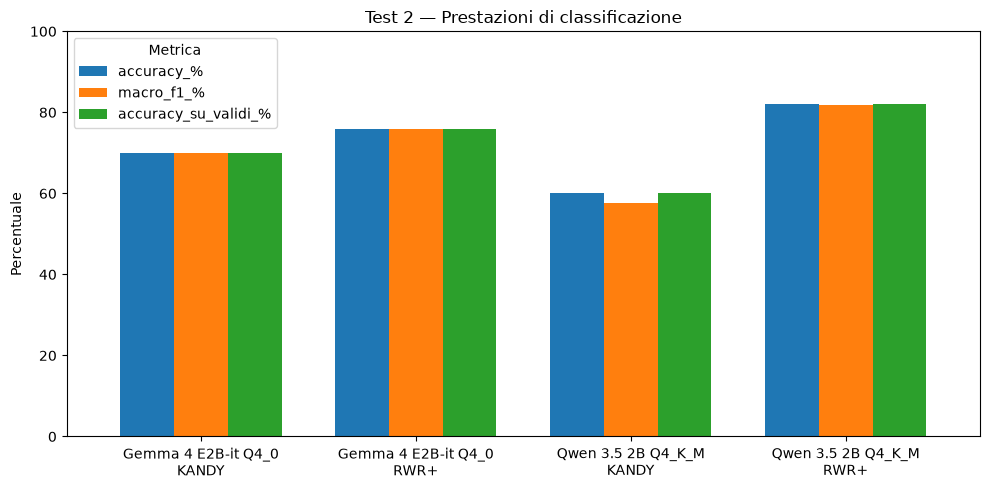

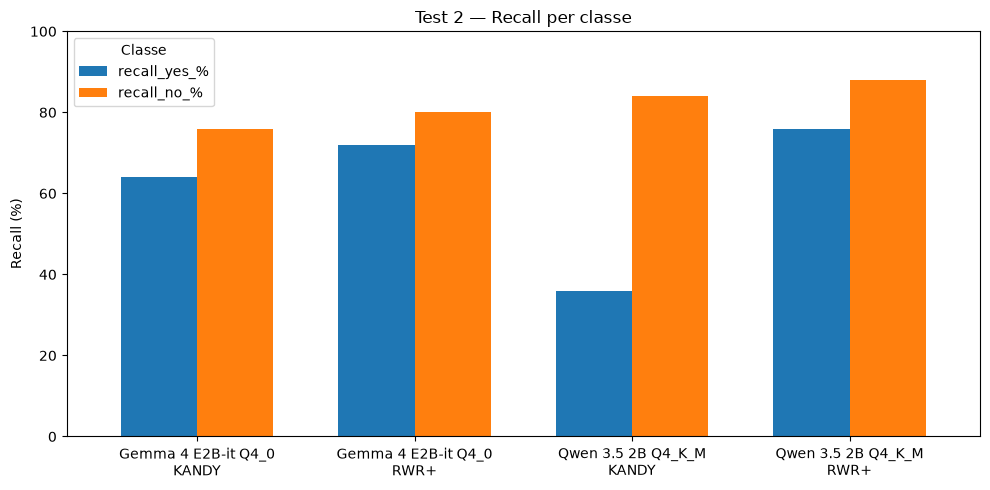

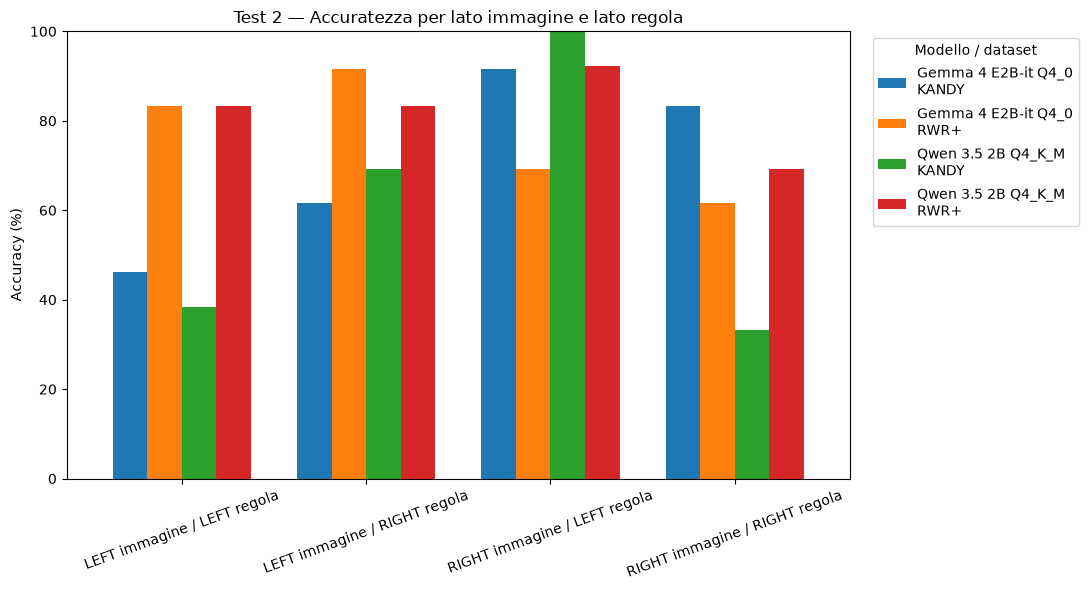

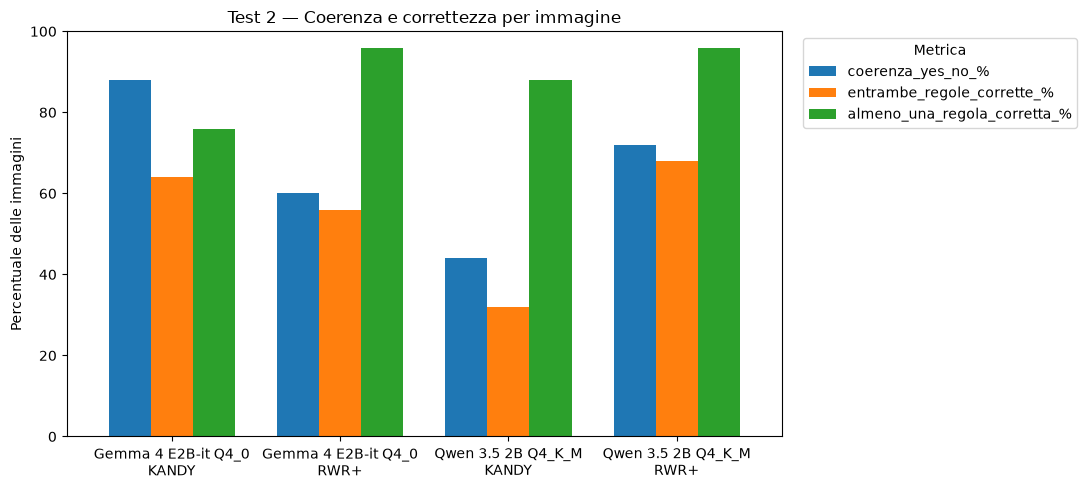

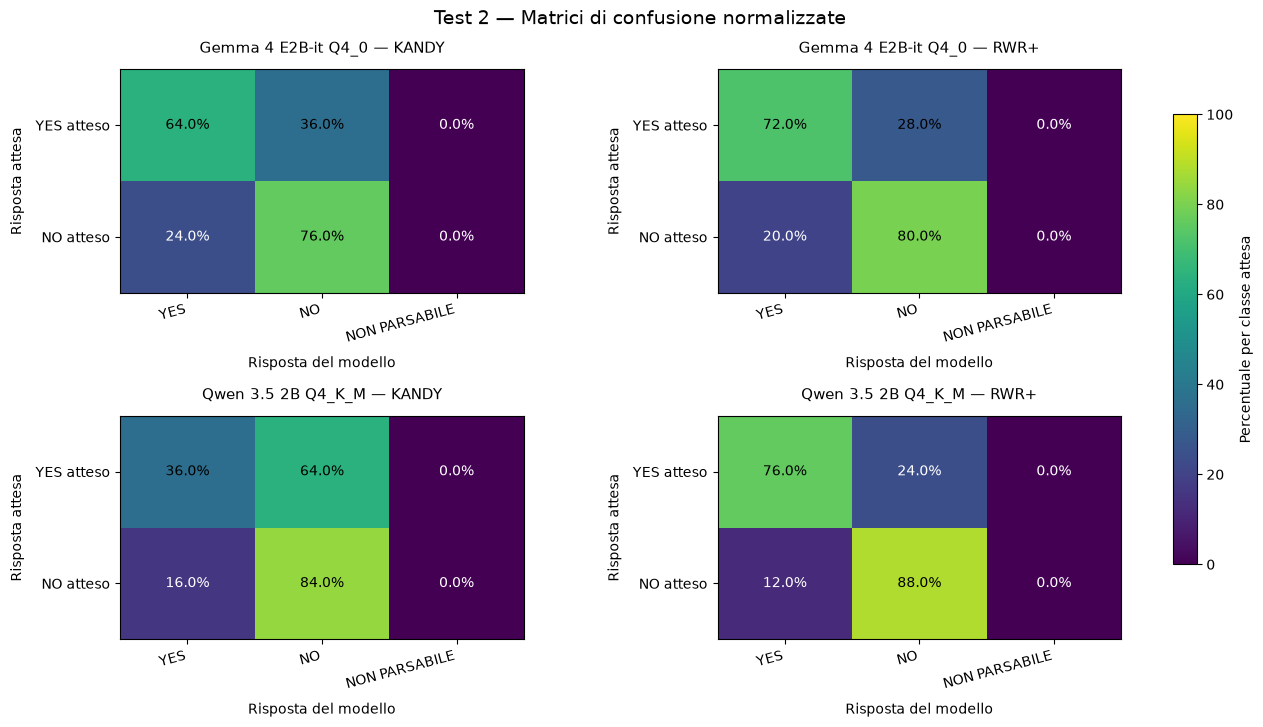

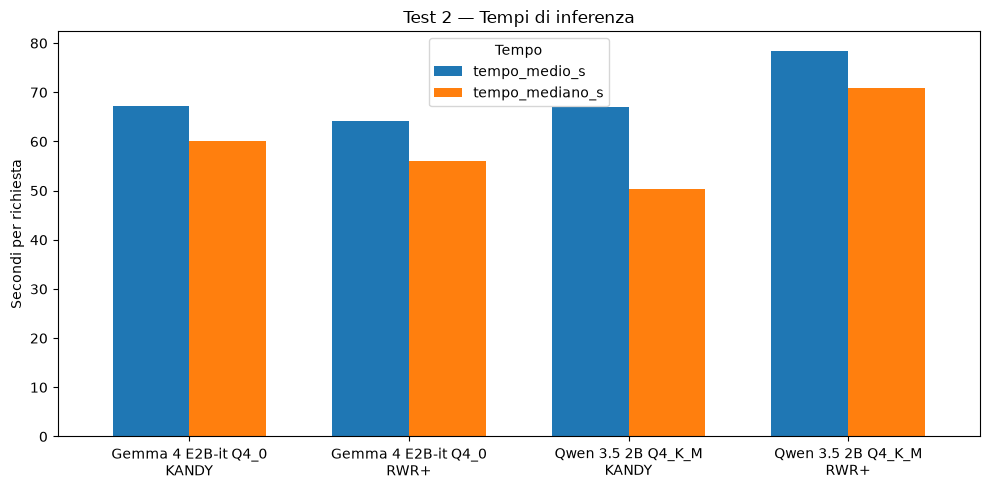


Tutti i risultati sono stati salvati in:
/home/cosimo/progetti/tesi/results/vlm_preliminary/test2_comparison


In [15]:
#SECONDO TEST - RISULTATI


#etichette dei modelli
MODEL_LABELS_VLM = {
    "qwen35_2b": "Qwen 3.5 2B",
    "gemma4_e2b_it": "Gemma 4 E2B-it"
}


#lettura dei jsonl
def leggi_jsonl_vlm(path):

    records = []

    with Path(path).open("r", encoding="utf-8") as file:

        for line_number, line in enumerate(file, start=1):

            if not line.strip():
                continue

            try:
                records.append(json.loads(line))

            except json.JSONDecodeError as error:
                raise ValueError(
                    f"JSON non valido in {path}, riga {line_number}: {error}"
                )

    return records


#carichiamo l'ultimo run disponibile per ogni modello
def carica_ultimi_run(test_prefix, test_name):

    rows = []

    for model_key, model_label in MODEL_LABELS_VLM.items():

        model_dir = Path(EXPERIMENTS_DIR) / model_key

        if not model_dir.is_dir():
            continue

        candidates = sorted(
            model_dir.glob(f"{test_prefix}_*.jsonl"),
            key=lambda path: path.stat().st_mtime,
            reverse=True
        )

        for path in candidates:

            records = leggi_jsonl_vlm(path)

            selected = [
                record for record in records
                if record.get("model") == model_key
                and record.get("test") == test_name
            ]

            if not selected:
                continue

            for record in selected:

                record["_source_jsonl"] = str(path.resolve())

                record["model_label"] = record.get(
                    "model_label",
                    model_label
                )

                rows.append(record)

            #manteniamo soltanto il run più recente
            break

    return pd.DataFrame(rows)


#normalizziamo le risposte
def normalizza_yes_no(value):

    if value is None:
        return None

    value = str(value).strip().upper()

    if value in ["YES", "NO"]:
        return value

    return None


#calcoliamo una percentuale senza divisioni per zero
def percentuale_test2(numeratore, denominatore):

    if denominatore == 0:
        return np.nan

    return round(numeratore / denominatore * 100, 2)


#carichiamo i risultati
test2_df = carica_ultimi_run(
    "test_2_rule_application",
    "test_2_rule_application"
)

if test2_df.empty:
    raise ValueError(
        "Non trovo risultati del Test 2. "
        "Esegui prima l'inferenza per almeno un modello."
    )


#costruiamo il dettaglio delle classificazioni
test2_rows = []

for record in test2_df.to_dict("records"):

    gold = normalizza_yes_no(
        record.get("correct_answer")
    )

    prediction = normalizza_yes_no(
        record.get("predicted_answer")
    )

    if prediction is None:

        parsed = record.get("parsed_response")

        if isinstance(parsed, dict):

            prediction = normalizza_yes_no(
                parsed.get("membership")
                or parsed.get("answer")
            )


    if gold is None:
        continue


    image_side = str(
        record.get("image_side", "")
    ).strip().lower()

    rule_side = str(
        record.get("rule_side", "")
    ).strip().lower()

    test2_rows.append({

        "model": record.get("model"),
        "model_label": record.get("model_label"),
        "dataset": record.get("dataset"),

        "problem_id": record.get("problem_id"),
        "task_id": record.get("task_id"),

        "image_path": record.get("image_path"),
        "image_side": image_side,
        "image_index": record.get("image_index"),
        "rule_side": rule_side,

        "correct_answer": gold,

        "prediction": prediction,
        "prediction_label": prediction or "NON PARSABILE",

        #un output non interpretabile conta come errore
        "is_correct": prediction == gold,

        "response_valid": prediction in ["YES", "NO"],

        "status": record.get("status"),
        "elapsed_seconds": record.get("elapsed_seconds")
    })


dettaglio_test2 = pd.DataFrame(test2_rows)

if dettaglio_test2.empty:
    raise ValueError("Nessun risultato del Test 2 valutabile.")


print("Richieste caricate:", len(dettaglio_test2))
print(
    "Modelli:",
    dettaglio_test2["model_label"].unique().tolist()
)


metriche_test2 = []

for (model, dataset), frame in dettaglio_test2.groupby(
    ["model_label", "dataset"],
    dropna=False
):

    y_true = frame["correct_answer"]
    y_pred = frame["prediction"]

    n = len(frame)

    #conteggi della matrice binaria
    tp = int(
        ((y_true == "YES") & (y_pred == "YES")).sum()
    )

    tn = int(
        ((y_true == "NO") & (y_pred == "NO")).sum()
    )

    fp_yes = int(
        ((y_true == "NO") & (y_pred == "YES")).sum()
    )

    fp_no = int(
        ((y_true == "YES") & (y_pred == "NO")).sum()
    )

    #precision e recall per YES
    precision_yes = (
        tp / (tp + fp_yes)
        if (tp + fp_yes) else np.nan
    )

    recall_yes = (
        tp / (y_true == "YES").sum()
        if (y_true == "YES").sum() else np.nan
    )

    #precision e recall per NO
    precision_no = (
        tn / (tn + fp_no)
        if (tn + fp_no) else np.nan
    )

    recall_no = (
        tn / (y_true == "NO").sum()
        if (y_true == "NO").sum() else np.nan
    )

    #f1 per classe
    f1_yes = (
        2 * precision_yes * recall_yes /
        (precision_yes + recall_yes)
        if (
            not pd.isna(precision_yes)
            and not pd.isna(recall_yes)
            and precision_yes + recall_yes > 0
        )
        else 0.0
    )

    f1_no = (
        2 * precision_no * recall_no /
        (precision_no + recall_no)
        if (
            not pd.isna(precision_no)
            and not pd.isna(recall_no)
            and precision_no + recall_no > 0
        )
        else 0.0
    )

    macro_f1 = np.mean([f1_yes, f1_no])

    valid_frame = frame[
        frame["response_valid"]
    ]

    if (
        len(valid_frame) > 0
        and valid_frame["correct_answer"].nunique() == 2
        and valid_frame["prediction"].nunique() == 2
    ):

        valid_tp = (
            (valid_frame["correct_answer"] == "YES")
            & (valid_frame["prediction"] == "YES")
        ).sum()

        valid_tn = (
            (valid_frame["correct_answer"] == "NO")
            & (valid_frame["prediction"] == "NO")
        ).sum()

        valid_fp = (
            (valid_frame["correct_answer"] == "NO")
            & (valid_frame["prediction"] == "YES")
        ).sum()

        valid_fn = (
            (valid_frame["correct_answer"] == "YES")
            & (valid_frame["prediction"] == "NO")
        ).sum()

        denominator_mcc = np.sqrt(
            (valid_tp + valid_fp)
            * (valid_tp + valid_fn)
            * (valid_tn + valid_fp)
            * (valid_tn + valid_fn)
        )

        mcc = (
            (valid_tp * valid_tn - valid_fp * valid_fn)
            / denominator_mcc
            if denominator_mcc > 0
            else np.nan
        )

        observed_agreement = (
            valid_frame["correct_answer"]
            == valid_frame["prediction"]
        ).mean()

        actual_yes_rate = (
            valid_frame["correct_answer"] == "YES"
        ).mean()

        predicted_yes_rate = (
            valid_frame["prediction"] == "YES"
        ).mean()

        expected_agreement = (
            actual_yes_rate * predicted_yes_rate
            + (1 - actual_yes_rate) * (1 - predicted_yes_rate)
        )

        kappa = (
            (observed_agreement - expected_agreement)
            / (1 - expected_agreement)
            if expected_agreement < 1
            else np.nan
        )

    else:

        mcc = np.nan
        kappa = np.nan


    metriche_test2.append({

        "model": model,
        "dataset": dataset,

        "richieste": n,

        "YES_attesi": int((y_true == "YES").sum()),
        "NO_attesi": int((y_true == "NO").sum()),

        "accuracy_%": percentuale_test2(
            int(frame["is_correct"].sum()), n
        ),

        "balanced_accuracy_%": percentuale_test2(
            np.mean([recall_yes, recall_no]) * 100,
            100
        ) if not pd.isna(recall_yes) and not pd.isna(recall_no)
        else np.nan,

        "precision_yes_%": round(precision_yes * 100, 2)
        if not pd.isna(precision_yes) else np.nan,

        "recall_yes_%": round(recall_yes * 100, 2)
        if not pd.isna(recall_yes) else np.nan,

        "f1_yes_%": round(f1_yes * 100, 2),

        "precision_no_%": round(precision_no * 100, 2)
        if not pd.isna(precision_no) else np.nan,

        "recall_no_%": round(recall_no * 100, 2)
        if not pd.isna(recall_no) else np.nan,

        "f1_no_%": round(f1_no * 100, 2),

        "macro_f1_%": round(macro_f1 * 100, 2),

        "mcc": round(mcc, 3)
        if not pd.isna(mcc) else np.nan,

        "cohen_kappa": round(kappa, 3)
        if not pd.isna(kappa) else np.nan,

        "output_validi_%": percentuale_test2(
            int(frame["response_valid"].sum()), n
        ),

        "accuracy_su_validi_%": percentuale_test2(
            int(valid_frame["is_correct"].sum()),
            len(valid_frame)
        )
    })


metriche_test2 = pd.DataFrame(metriche_test2)


confusione_test2 = pd.crosstab(
    [
        dettaglio_test2["model_label"],
        dettaglio_test2["dataset"],
        dettaglio_test2["correct_answer"]
    ],
    dettaglio_test2["prediction_label"]
).reindex(
    columns=["YES", "NO", "NON PARSABILE"],
    fill_value=0
)


#versione normalizzata per riga
confusione_test2_pct = confusione_test2.div(
    confusione_test2.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

metriche_lato_test2 = []

for (
    model,
    dataset,
    image_side,
    rule_side
), frame in dettaglio_test2.groupby(
    ["model_label", "dataset", "image_side", "rule_side"],
    dropna=False
):

    n = len(frame)

    #diagonale: immagine e regola dello stesso lato
    matching = image_side == rule_side

    expected = "YES" if matching else "NO"

    predicted_yes = int(
        (frame["prediction"] == "YES").sum()
    )

    predicted_no = int(
        (frame["prediction"] == "NO").sum()
    )

    metriche_lato_test2.append({

        "model": model,
        "dataset": dataset,

        "image_side": image_side,
        "rule_side": rule_side,

        "combinazione": (
            f"Immagine {image_side.upper()} / "
            f"Regola {rule_side.upper()}"
        ),

        "classe_attesa": expected,

        "richieste": n,

        "corrette": int(frame["is_correct"].sum()),

        "accuracy_%": percentuale_test2(
            int(frame["is_correct"].sum()), n
        ),

        "risposte_yes_%": percentuale_test2(
            predicted_yes, n
        ),

        "risposte_no_%": percentuale_test2(
            predicted_no, n
        ),

        "output_validi_%": percentuale_test2(
            int(frame["response_valid"].sum()), n
        )
    })


metriche_lato_test2 = pd.DataFrame(metriche_lato_test2)

#ogni immagine deve essere valutata con entrambe le regole
pair_columns = [
    "model",
    "model_label",
    "dataset",
    "problem_id",
    "image_side",
    "image_index",
    "image_path"
]

pair_rows = []

for keys, frame in dettaglio_test2.groupby(
    pair_columns,
    dropna=False
):

    if not isinstance(keys, tuple):
        keys = (keys,)

    row_info = dict(zip(pair_columns, keys))

    #una coppia completa deve contenere entrambe le regole
    complete_pair = (
        len(frame) == 2
        and set(frame["rule_side"]) == {"left", "right"}
    )

    predictions_valid = (
        complete_pair
        and frame["response_valid"].all()
    )

    #ci aspettiamo una risposta YES e una NO
    structurally_consistent = (
        predictions_valid
        and set(frame["prediction"]) == {"YES", "NO"}
    )

    correct_rules = int(frame["is_correct"].sum())

    both_correct = (
        complete_pair
        and correct_rules == 2
    )

    if not complete_pair:

        outcome = "coppia incompleta"

    elif not predictions_valid:

        outcome = "output incompleto"

    elif correct_rules == 2:

        outcome = "entrambe corrette"

    elif correct_rules == 1:

        outcome = "una corretta"

    else:

        outcome = "nessuna corretta"


    row_info.update({

        "numero_risposte": len(frame),

        "coppia_completa": complete_pair,

        "output_validi": predictions_valid,

        "coerenza_yes_no": structurally_consistent,

        "regole_corrette": correct_rules,

        "entrambe_corrette": both_correct,

        "accuratezza_coppia_%": (
            correct_rules / 2 * 100
            if complete_pair else np.nan
        ),

        "esito_coppia": outcome
    })

    pair_rows.append(row_info)


dettaglio_coppie_test2 = pd.DataFrame(pair_rows)


#riepilogo delle prestazioni per immagine
metriche_coppie_test2 = []

for (model, dataset), frame in dettaglio_coppie_test2.groupby(
    ["model_label", "dataset"],
    dropna=False
):

    complete = frame[
        frame["coppia_completa"]
    ]

    valid_pairs = complete[
        complete["output_validi"]
    ]

    metriche_coppie_test2.append({

        "model": model,
        "dataset": dataset,

        "immagini": len(frame),

        "coppie_complete": len(complete),

        "coppie_con_output_validi": len(valid_pairs),

        "coerenza_yes_no_%": percentuale_test2(
            int(valid_pairs["coerenza_yes_no"].sum()),
            len(valid_pairs)
        ),

        "entrambe_regole_corrette_%": percentuale_test2(
            int(complete["entrambe_corrette"].sum()),
            len(complete)
        ),

        "almeno_una_regola_corretta_%": percentuale_test2(
            int((complete["regole_corrette"] >= 1).sum()),
            len(complete)
        ),

        "media_regole_corrette_per_immagine": round(
            complete["regole_corrette"].mean(), 2
        ) if not complete.empty else np.nan
    })


metriche_coppie_test2 = pd.DataFrame(
    metriche_coppie_test2
)


#distribuzione degli esiti delle coppie
distribuzione_coppie_test2 = (
    dettaglio_coppie_test2
    .groupby(
        ["model_label", "dataset", "esito_coppia"]
    )
    .size()
    .unstack(fill_value=0)
)


metriche_problema_test2 = (
    dettaglio_test2
    .groupby(
        ["model_label", "dataset", "problem_id"],
        dropna=False
    )
    .agg(
        richieste=("task_id", "count"),
        corrette=("is_correct", "sum"),
        output_validi=("response_valid", "sum"),
        tempo_medio_s=("elapsed_seconds", "mean")
    )
    .reset_index()
)

metriche_problema_test2["accuracy_%"] = (
    metriche_problema_test2["corrette"]
    / metriche_problema_test2["richieste"] * 100
).round(2)

metriche_problema_test2["output_validi_%"] = (
    metriche_problema_test2["output_validi"]
    / metriche_problema_test2["richieste"] * 100
).round(2)

metriche_problema_test2["tempo_medio_s"] = (
    metriche_problema_test2["tempo_medio_s"]
).round(2)

metriche_tecniche_test2 = (
    dettaglio_test2
    .groupby(
        ["model_label", "dataset"],
        dropna=False
    )
    .agg(
        richieste=("task_id", "count"),

        tempo_medio_s=("elapsed_seconds", "mean"),

        tempo_mediano_s=("elapsed_seconds", "median"),

        tempo_totale_s=("elapsed_seconds", "sum")
    )
    .reset_index()
)

metriche_tecniche_test2["tempo_medio_s"] = (
    metriche_tecniche_test2["tempo_medio_s"].round(2)
)

metriche_tecniche_test2["tempo_mediano_s"] = (
    metriche_tecniche_test2["tempo_mediano_s"].round(2)
)

metriche_tecniche_test2["tempo_totale_min"] = (
    metriche_tecniche_test2["tempo_totale_s"] / 60
).round(2)


paired_test2 = dettaglio_test2.pivot_table(
    index=["dataset", "task_id"],
    columns="model",
    values="is_correct",
    aggfunc="first"
).reset_index()

if {"qwen35_2b", "gemma4_e2b_it"}.issubset(
    paired_test2.columns
):

    paired_test2 = paired_test2.dropna(
        subset=["qwen35_2b", "gemma4_e2b_it"]
    )

    paired_test2["confronto"] = np.select(
        [
            paired_test2["qwen35_2b"]
            & ~paired_test2["gemma4_e2b_it"],

            paired_test2["gemma4_e2b_it"]
            & ~paired_test2["qwen35_2b"]
        ],
        [
            "Qwen migliore",
            "Gemma migliore"
        ],
        default="Parità"
    )

    confronto_diretto_test2 = (
        paired_test2["confronto"].value_counts()
    )

else:

    paired_test2 = pd.DataFrame()
    confronto_diretto_test2 = pd.Series(dtype=int)


print("\n1. METRICHE GENERALI E PER CLASSE")
display(metriche_test2)

print("\n2. MATRICE DI CONFUSIONE")
display(confusione_test2)

print("\n3. PRESTAZIONI PER LATO IMMAGINE E REGOLA")
display(metriche_lato_test2)

print("\n4. COERENZA DELLE DUE RISPOSTE PER IMMAGINE")
display(metriche_coppie_test2)

print("\nDISTRIBUZIONE DEGLI ESITI DELLE COPPIE")
display(distribuzione_coppie_test2)

print("\n5. PRESTAZIONI PER PROBLEMA")
display(metriche_problema_test2)

print("\n6. TEMPI DI INFERENZA")
display(metriche_tecniche_test2)

if not confronto_diretto_test2.empty:
    print("\n7. CONFRONTO DIRETTO QWEN / GEMMA")
    display(confronto_diretto_test2)

TEST2_METRICS_DIR = (
    Path(EXPERIMENTS_DIR) / "test2_comparison"
)

TEST2_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


dettaglio_test2.to_csv(
    TEST2_METRICS_DIR / "test2_dettaglio.csv",
    index=False
)

metriche_test2.to_csv(
    TEST2_METRICS_DIR / "test2_metriche_generali.csv",
    index=False
)

confusione_test2.to_csv(
    TEST2_METRICS_DIR / "test2_matrice_confusione.csv"
)

confusione_test2_pct.to_csv(
    TEST2_METRICS_DIR / "test2_matrice_confusione_percentuali.csv"
)

metriche_lato_test2.to_csv(
    TEST2_METRICS_DIR / "test2_metriche_lato_regola.csv",
    index=False
)

dettaglio_coppie_test2.to_csv(
    TEST2_METRICS_DIR / "test2_dettaglio_coppie.csv",
    index=False
)

metriche_coppie_test2.to_csv(
    TEST2_METRICS_DIR / "test2_metriche_coppie.csv",
    index=False
)

metriche_problema_test2.to_csv(
    TEST2_METRICS_DIR / "test2_metriche_problema.csv",
    index=False
)

metriche_tecniche_test2.to_csv(
    TEST2_METRICS_DIR / "test2_metriche_tecniche.csv",
    index=False
)

paired_test2.to_csv(
    TEST2_METRICS_DIR / "test2_confronto_modelli.csv",
    index=False
)


#accuracy, macro f1 e accuracy sugli output validi
if not metriche_test2.empty:

    plot_performance = metriche_test2.copy()

    plot_performance["gruppo"] = (
        plot_performance["model"]
        + "\n"
        + plot_performance["dataset"]
    )

    plot_performance = plot_performance.set_index(
        "gruppo"
    )[
        [
            "accuracy_%",
            "macro_f1_%",
            "accuracy_su_validi_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    plot_performance.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title("Test 2 — Prestazioni di classificazione")
    ax.set_ylabel("Percentuale")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(title="Metrica")
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()

    fig.savefig(
        TEST2_METRICS_DIR / "01_prestazioni_generali.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#recall delle due classi
if not metriche_test2.empty:

    plot_recall = metriche_test2.copy()

    plot_recall["gruppo"] = (
        plot_recall["model"]
        + "\n"
        + plot_recall["dataset"]
    )

    plot_recall = plot_recall.set_index(
        "gruppo"
    )[
        [
            "recall_yes_%",
            "recall_no_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    plot_recall.plot(
        kind="bar",
        ax=ax,
        width=0.7
    )

    ax.set_title("Test 2 — Recall per classe")
    ax.set_ylabel("Recall (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(title="Classe")
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()

    fig.savefig(
        TEST2_METRICS_DIR / "02_recall_per_classe.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#accuratezza sulle quattro combinazioni immagine-regola
if not metriche_lato_test2.empty:

    plot_side = metriche_lato_test2.copy()

    plot_side["gruppo"] = (
        plot_side["model"]
        + "\n"
        + plot_side["dataset"]
    )

    plot_side["combinazione"] = (
        plot_side["image_side"].str.upper()
        + " immagine / "
        + plot_side["rule_side"].str.upper()
        + " regola"
    )

    side_pivot = plot_side.pivot_table(
        index="combinazione",
        columns="gruppo",
        values="accuracy_%",
        aggfunc="first"
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    side_pivot.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title("Test 2 — Accuratezza per lato immagine e lato regola")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(
        title="Modello / dataset",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    ax.tick_params(axis="x", rotation=20)

    fig.tight_layout()

    fig.savefig(
        TEST2_METRICS_DIR / "03_accuracy_lati.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#accuratezza stretta per coppia di risposte
if not metriche_coppie_test2.empty:

    plot_pairs = metriche_coppie_test2.copy()

    plot_pairs["gruppo"] = (
        plot_pairs["model"]
        + "\n"
        + plot_pairs["dataset"]
    )

    plot_pairs = plot_pairs.set_index(
        "gruppo"
    )[
        [
            "coerenza_yes_no_%",
            "entrambe_regole_corrette_%",
            "almeno_una_regola_corretta_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(11, 5))

    plot_pairs.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title("Test 2 — Coerenza e correttezza per immagine")
    ax.set_ylabel("Percentuale delle immagini")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.legend(
        title="Metrica",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()

    fig.savefig(
        TEST2_METRICS_DIR / "04_coerenza_per_immagine.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#matrici di confusione normalizzate

groups = list(
    dettaglio_test2.groupby(
        ["model_label", "dataset"],
        dropna=False
    )
)

if groups:

    n_groups = len(groups)
    n_cols = 2
    n_rows = int(np.ceil(n_groups / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(13, 7.5),
        squeeze=False
    )

    prediction_labels = [
        "YES",
        "NO",
        "NON PARSABILE"
    ]

    fig.subplots_adjust(
        left=0.10,
        right=0.87,
        bottom=0.12,
        top=0.88,
        wspace=0.48,
        hspace=0.55
    )

    image = None

    for ax, ((model, dataset), frame) in zip(
        axes.flat,
        groups
    ):

        matrix = pd.crosstab(
            frame["correct_answer"],
            frame["prediction_label"],
            normalize="index"
        ).reindex(
            index=["YES", "NO"],
            columns=prediction_labels,
            fill_value=0
        ) * 100

        image = ax.imshow(
            matrix.values,
            vmin=0,
            vmax=100,
            aspect="auto"
        )

        ax.set_title(
            f"{model} — {dataset}",
            fontsize=11,
            pad=12
        )

        ax.set_xticks(range(len(prediction_labels)))
        ax.set_xticklabels(
            prediction_labels,
            rotation=15,
            ha="right"
        )

        ax.set_yticks([0, 1])
        ax.set_yticklabels([
            "YES atteso",
            "NO atteso"
        ])

        #aggiungiamo le percentuali nelle celle
        for row_index in range(matrix.shape[0]):

            for col_index in range(matrix.shape[1]):

                value = matrix.iloc[row_index, col_index]

                text_color = (
                    "white" if value < 25 else "black"
                )

                ax.text(
                    col_index,
                    row_index,
                    f"{value:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=10,
                    color=text_color
                )

        ax.set_xlabel("Risposta del modello", labelpad=8)
        ax.set_ylabel("Risposta attesa", labelpad=8)

    for ax in axes.flat[n_groups:]:
        ax.set_visible(False)

    colorbar_ax = fig.add_axes([
        0.91,
        0.22,
        0.018,
        0.60
    ])

    fig.colorbar(
        image,
        cax=colorbar_ax,
        label="Percentuale per classe attesa"
    )

    fig.suptitle(
        "Test 2 — Matrici di confusione normalizzate",
        fontsize=14,
        y=0.96
    )

    fig.savefig(
        TEST2_METRICS_DIR / "05_matrici_confusione.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


#tempi di inferenza
if not metriche_tecniche_test2.empty:

    plot_times = metriche_tecniche_test2.copy()

    plot_times["gruppo"] = (
        plot_times["model_label"]
        + "\n"
        + plot_times["dataset"]
    )

    plot_times = plot_times.set_index(
        "gruppo"
    )[
        [
            "tempo_medio_s",
            "tempo_mediano_s"
        ]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    plot_times.plot(
        kind="bar",
        ax=ax,
        width=0.7
    )

    ax.set_title("Test 2 — Tempi di inferenza")
    ax.set_ylabel("Secondi per richiesta")
    ax.set_xlabel("")
    ax.legend(title="Tempo")
    ax.tick_params(axis="x", rotation=0)

    fig.tight_layout()

    fig.savefig(
        TEST2_METRICS_DIR / "06_tempi_inferenza.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


print("\nTutti i risultati sono stati salvati in:")
print(TEST2_METRICS_DIR)

## Terzo Test - Generazione 20 Ipotesi

In questo terzo test vengono sottoposti ai due modelli le matrici bongard di riferimento e si richiede loro di formulare 20 ipotesi di regole che separano correttamente i due lati della matrice.

In [12]:
#PREPARAZIONE DEI TASK DEL TERZO TEST

#utilizziamo gli stessi problemi del Test 1
if "test1_tasks" not in globals() or not test1_tasks:
    raise RuntimeError(
        "Non trovo test1_tasks. Esegui prima la preparazione del Test 1."
    )


TEST3_TASKS = []

for task in test1_tasks:

    image_path = Path(task["image_path"])

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Matrice non trovata: {image_path}"
        )

    TEST3_TASKS.append({

        "task_id": (
            f"generate::{task['dataset']}::{task['problem_id']}"
        ),

        "dataset": task["dataset"],
        "problem_id": task["problem_id"],

        "image_path": image_path,

        #riferimento utilizzato esclusivamente dal revisore
        "reference": task["reference"]
    })


#controlliamo che non ci siano task duplicati
task_ids = [
    task["task_id"]
    for task in TEST3_TASKS
]

if len(task_ids) != len(set(task_ids)):
    raise ValueError("Sono presenti task duplicati nel Test 3.")


#controlliamo la distribuzione
test3_preparation_df = pd.DataFrame([
    {
        "dataset": task["dataset"],
        "problem_id": task["problem_id"],
        "image_path": str(task["image_path"])
    }
    for task in TEST3_TASKS
])


print("Problemi KANDY:", 
      (test3_preparation_df["dataset"] == "KANDY").sum())

print("Problemi RWR+:", 
      (test3_preparation_df["dataset"] == "RWR+").sum())

print("Totale problemi:", len(TEST3_TASKS))

display(test3_preparation_df)

Problemi KANDY: 38
Problemi RWR+: 38
Totale problemi: 76


,dataset,problem_id,image_path
0,KANDY,easy-0,/home/cosimo/progetti/tesi/data/processed/data...
1,KANDY,easy-1,/home/cosimo/progetti/tesi/data/processed/data...
2,KANDY,easy-2,/home/cosimo/progetti/tesi/data/processed/data...
3,KANDY,easy-3,/home/cosimo/progetti/tesi/data/processed/data...
4,KANDY,easy-4,/home/cosimo/progetti/tesi/data/processed/data...
...,...,...,...
71,RWR+,Q18,/home/cosimo/progetti/tesi/data/processed/data...
72,RWR+,Q17,/home/cosimo/progetti/tesi/data/processed/data...
73,RWR+,Q22,/home/cosimo/progetti/tesi/data/processed/data...
74,RWR+,Q01,/home/cosimo/progetti/tesi/data/processed/data...


In [ ]:
#TERZO TEST - GENERAZIONE DI 20 IPOTESI


import re
from datetime import datetime

TEST3_MAX_OUTPUT_TOKENS = max(
    int(MAX_OUTPUT_TOKENS),
    3072
)


#selezione dei task in base alla configurazione yaml

if RUN_MODE == "full":

    TEST3_TASKS_TO_RUN = TEST3_TASKS.copy()

elif RUN_MODE == "pilot":

    #test1_tasks è già limitato da PILOT_LIMIT nella cella 13
    TEST3_TASKS_TO_RUN = TEST3_TASKS.copy()

else:

    raise ValueError(
        f"RUN_MODE non riconosciuto: {RUN_MODE}"
    )


if not TEST3_TASKS_TO_RUN:
    raise ValueError(
        "Non ci sono task da eseguire nel Test 3."
    )


print("Modalità esecuzione:", RUN_MODE)
print("Limite pilot per dataset:", PILOT_LIMIT)

print(
    "Problemi KANDY:",
    sum(t["dataset"] == "KANDY" for t in TEST3_TASKS_TO_RUN)
)

print(
    "Problemi RWR+:",
    sum(t["dataset"] == "RWR+" for t in TEST3_TASKS_TO_RUN)
)

print(
    "Totale problemi da eseguire:",
    len(TEST3_TASKS_TO_RUN)
)


display(
    pd.DataFrame([
        {
            "dataset": task["dataset"],
            "problem_id": task["problem_id"]
        }
        for task in TEST3_TASKS_TO_RUN
    ])
)

#andiamo a forzare lo schema della risposta
#per ottenere esattamente 20 ipotesi

TEST3_RESPONSE_SCHEMA = {

    "type": "object",

    "properties": {

        "hypotheses": {

            "type": "array",

            #numero di ipotesi obbligatorio
            "minItems": 20,
            "maxItems": 20,

            "items": {

                "type": "object",

                "properties": {

                    "left_rule": {
                        "type": "string",
                        "minLength": 1
                    },

                    "right_rule": {
                        "type": "string",
                        "minLength": 1
                    }
                },

                "required": [
                    "left_rule",
                    "right_rule"
                ],

                "additionalProperties": False
            }
        }
    },

    "required": [
        "hypotheses"
    ],

    "additionalProperties": False
}


system_prompt_test3 = """
You are an expert in visual concept learning and Bongard problems.

Analyze the attached Bongard matrix.

The first two columns contain the LEFT group.
The last two columns contain the RIGHT group.

Identify the abstract visual distinction between the groups.

Generate 20 distinct candidate hypotheses.

Each hypothesis must contain:
- one concise rule for the LEFT group
- one concise rule for the RIGHT group

Rules must be short, precise and visually grounded.

Prefer simple sentences of approximately 8-12 words per rule.

Consider:
- geometric properties
- colors and patterns
- number of objects
- shapes and orientation
- spatial relationships
- presence or absence of features
- relationships between objects

Do not describe individual images.
Focus on the properties that distinguish the two groups.

Do not use external knowledge.
Do not invent details that are not visible.
"""


user_prompt_test3 = """
Analyze the attached Bongard matrix.

The first two columns represent the LEFT group.
The last two columns represent the RIGHT group.

Generate exactly 20 distinct candidate hypotheses.

Each candidate must contain:
- left_rule: a concise visual rule describing LEFT
- right_rule: a concise visual rule describing RIGHT

Requirements:

1. Generate exactly 20 hypotheses.
2. Include both rules in every hypothesis.
3. Use short and precise descriptions.
4. Avoid introductory text and explanations.
5. Avoid repeating the same hypothesis with minor wording changes.
6. Include different plausible interpretations of the visual distinction.
7. Do not use information external to the images.

Return only a JSON object with the following structure:

{
  "hypotheses": [
    {
      "left_rule": "Short description of LEFT",
      "right_rule": "Short description of RIGHT"
    }
  ]
}

The hypotheses array must contain exactly 20 objects.
Do not include any other fields or text.
"""


#convertiamo l'immagine in base64
def image_to_data_url_test3(image_path):

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Immagine non trovata: {image_path}"
        )

    mime_type, _ = mimetypes.guess_type(
        image_path.name
    )

    if not mime_type or not mime_type.startswith("image/"):
        raise ValueError(
            f"Formato immagine non riconosciuto: {image_path}"
        )

    encoded = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    return f"data:{mime_type};base64,{encoded}"


#estraiamo le ipotesi dal JSON
def parse_test3_response(raw_response):

    raw = str(raw_response or "").strip()

    if not raw:
        return None

    #rimuoviamo eventuali blocchi markdown
    clean = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        raw,
        flags=re.IGNORECASE
    ).strip()

    try:
        decoded = json.loads(clean)

    except json.JSONDecodeError:

        #tentiamo il recupero di un oggetto JSON parziale
        start = clean.find("{")

        if start < 0:
            return None

        try:
            decoded, _ = json.JSONDecoder().raw_decode(
                clean[start:]
            )

        except json.JSONDecodeError:
            return None


    if not isinstance(decoded, dict):
        return None

    hypotheses = decoded.get("hypotheses")

    if not isinstance(hypotheses, list):
        return None


    parsed_hypotheses = []

    for hypothesis in hypotheses:

        if not isinstance(hypothesis, dict):
            continue

        left_rule = str(
            hypothesis.get("left_rule", "")
        ).strip()

        right_rule = str(
            hypothesis.get("right_rule", "")
        ).strip()

        if not left_rule or not right_rule:
            continue

        parsed_hypotheses.append({

            "left_rule": left_rule,
            "right_rule": right_rule
        })


    if not parsed_hypotheses:
        return None

    return {
        "hypotheses": parsed_hypotheses[:20]
    }


model_response = requests.get(
    f"{BASE_URL}/models",
    timeout=10
)

model_response.raise_for_status()

available_models = model_response.json().get("data", [])

if not available_models:
    raise RuntimeError(
        "Nessun modello disponibile nel server."
    )

SERVER_MODEL_NAME = available_models[0]["id"]


print("Modello selezionato:", ACTIVE_MODEL)
print("Modello caricato nel server:", SERVER_MODEL_NAME)
print("Massimo token output:", TEST3_MAX_OUTPUT_TOKENS)


run_timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

RESULT_FILE = MODEL_RESULTS_DIR / (
    f"test_3_generation_20_{run_timestamp}.jsonl"
)

records = []


for index, task in enumerate(
    TEST3_TASKS_TO_RUN,
    start=1
):

    print(
        f"\nProblema {index}/{len(TEST3_TASKS_TO_RUN)}: "
        f"{task['dataset']} - {task['problem_id']}"
    )

    start_time = time.perf_counter()
    response = None

    image_path = Path(task["image_path"])

    try:

        relative_image_path = str(
            image_path.relative_to(PROJECT_ROOT)
        )

    except ValueError:

        relative_image_path = str(image_path)


    record = {

        "test": "test_3_generation_20",

        "task_id": task["task_id"],

        "model": ACTIVE_MODEL,
        "model_label": MODEL_LABEL,
        "server_model_name": SERVER_MODEL_NAME,

        "dataset": task["dataset"],
        "problem_id": task["problem_id"],

        "board_path": relative_image_path,
        "image_path": relative_image_path,
        "input_images": [relative_image_path],

        #riferimento conservato soltanto per la valutazione
        "reference": task["reference"],

        "thinking_enabled": THINKING_ENABLED,
        "reasoning_budget": THINKING_BUDGET,
        "max_output_tokens": TEST3_MAX_OUTPUT_TOKENS,

        "prompt_version": "test3_v2_schema20_concise",

        "raw_response": None,
        "reasoning_response": None,
        "parsed_response": None,

        "num_hypotheses": 0,

        "status": "pending",

        "finish_reason": None,
        "usage": None,
        "timings": None,
        "elapsed_seconds": None
    }


    try:

        #convertiamo la matrice
        image_data_url = image_to_data_url_test3(
            image_path
        )


        #prepariamo il payload multimodale
        payload = {

            "model": SERVER_MODEL_NAME,

            #generazione vincolata tramite JSON Schema
            "response_format": {

                "type": "json_schema",

                "json_schema": {

                    "name": "test3_hypotheses",

                    "schema": TEST3_RESPONSE_SCHEMA
                }
            },

            "messages": [

                {
                    "role": "system",
                    "content": system_prompt_test3
                },

                {
                    "role": "user",
                    "content": [

                        {
                            "type": "image_url",
                            "image_url": {
                                "url": image_data_url
                            }
                        },

                        {
                            "type": "text",
                            "text": user_prompt_test3
                        }
                    ]
                }
            ],

            "temperature": TEMPERATURE,
            "top_p": TOP_P,
            "seed": RANDOM_SEED,

            "max_tokens": TEST3_MAX_OUTPUT_TOKENS,

            "stream": False
        }


        #inviamo la richiesta al server
        response = requests.post(
            f"{BASE_URL}/chat/completions",
            json=payload,
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        result = response.json()

        choices = result.get("choices", [])

        if not choices:
            raise ValueError(
                "Il server non ha restituito risposte."
            )


        message = choices[0].get("message", {})

        raw_response = message.get("content") or ""
        reasoning_response = message.get("reasoning_content") or ""

        record["raw_response"] = raw_response
        record["reasoning_response"] = reasoning_response

        record["finish_reason"] = choices[0].get(
            "finish_reason"
        )

        record["usage"] = result.get("usage")
        record["timings"] = result.get("timings")


        #analizziamo la risposta
        parsed = parse_test3_response(
            raw_response
        )


        if parsed is not None:

            record["parsed_response"] = parsed

            hypotheses = parsed["hypotheses"]

            record["num_hypotheses"] = len(
                hypotheses
            )

            #20 coppie complete e con entrambe le regole
            if len(hypotheses) == 20:

                record["status"] = "valid_output"

            elif record["finish_reason"] == "length":

                record["status"] = "truncated_output"

            else:

                record["status"] = "incomplete_output"


        elif record["finish_reason"] == "length":

            record["status"] = "truncated_output"

        elif reasoning_response and not raw_response.strip():

            record["status"] = "reasoning_without_final"

        elif not raw_response.strip():

            record["status"] = "empty_output"

        else:

            record["status"] = "invalid_output_format"


    except requests.exceptions.Timeout:

        record["status"] = "timeout_error"

    except requests.exceptions.HTTPError as error:

        record["status"] = "http_error"

        record["error"] = (
            response.text[:3000]
            if response is not None
            else str(error)
        )

    except requests.exceptions.RequestException as error:

        record["status"] = "request_error"
        record["error"] = str(error)

    except Exception as error:

        record["status"] = "execution_error"
        record["error"] = str(error)


    finally:

        record["elapsed_seconds"] = round(
            time.perf_counter() - start_time,
            2
        )

        #salviamo immediatamente ogni risultato
        records.append(record)

        with open(
            RESULT_FILE,
            "a",
            encoding="utf-8"
        ) as file:

            file.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )


        print(
            "Ipotesi estratte:",
            record["num_hypotheses"]
        )

        print(
            "Stato:",
            record["status"]
        )

        print(
            "Finish reason:",
            record["finish_reason"]
        )

        print(
            "Tempo:",
            record["elapsed_seconds"],
            "secondi"
        )

        if record["status"] != "valid_output":

            print(
                "Errore:",
                record.get("error", "")
            )

            print(
                "Risposta:",
                record["raw_response"][:1500]
                if record["raw_response"]
                else "[vuota]"
            )


test3_results_df = pd.DataFrame(records)

display(
    test3_results_df[
        [
            "dataset",
            "problem_id",
            "num_hypotheses",
            "status",
            "finish_reason",
            "elapsed_seconds"
        ]
    ]
)


#riepilogo degli output
print("\nRIEPILOGO TEST 3")

print(
    test3_results_df["status"].value_counts()
)

print(
    "\nNumero medio di ipotesi:",
    round(
        test3_results_df["num_hypotheses"].mean(),
        2
    )
)

print(
    "\nOutput con esattamente 20 ipotesi:",
    int(
        test3_results_df["num_hypotheses"].eq(20).sum()
    ),
    "/",
    len(test3_results_df)
)

print("\nRisultati salvati in:", RESULT_FILE)

## Terzo Test - Risultati

Funzioni di caricamento Test 3 definite.
qwen35_2b: 76 problemi caricati da /home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b/test_3_generation_20_20261116_153605.jsonl
gemma4_e2b_it: 76 problemi caricati da /home/cosimo/progetti/tesi/results/vlm_preliminary/gemma4_e2b_it/test_3_generation_20_20261116_110847.jsonl
RUN DEL TEST 3


,model,dataset,problem_id,status,elapsed_seconds
0,qwen35_2b,KANDY,easy-0,valid_output,147.04
1,qwen35_2b,KANDY,easy-1,valid_output,130.43
2,qwen35_2b,KANDY,easy-2,valid_output,151.83
3,qwen35_2b,KANDY,easy-3,valid_output,167.10
4,qwen35_2b,KANDY,easy-4,valid_output,135.13
...,...,...,...,...,...
147,gemma4_e2b_it,RWR+,Q18,valid_output,149.62
148,gemma4_e2b_it,RWR+,Q17,valid_output,147.61
149,gemma4_e2b_it,RWR+,Q22,valid_output,143.82
150,gemma4_e2b_it,RWR+,Q01,valid_output,149.17



File di revisione trovati:
/home/cosimo/progetti/tesi/results/vlm_preliminary/gemma4_e2b_it/review_all_tests.jsonl
/home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b/review_all_tests.jsonl

Annotazioni Test 3 caricate: 3040
Ipotesi con annotazione: 3040

1. HIT@K E RANKING


,model,dataset,problemi,output_con_20_ipotesi,output_con_20_ipotesi_%,ipotesi_medie_generate,problemi_con_revisione_completa,revisione_completa_%,problemi_con_revisione_semantica_completa,revisione_semantica_completa_%,...,copertura_hit10_%,hit_at_10_%,problemi_hit20_valutabili,copertura_hit20_%,hit_at_20_%,partial_hit_at_20_%,problemi_mrr_valutabili,mrr,primo_rango_corretto_medio,ipotesi_corrette_medie
0,Gemma 4 E2B-it Q4_0,KANDY,38,38,100.0,20.0,38,100.0,38,100.0,...,100.0,2.63,38,100.0,2.63,23.68,38,0.0033,8.00,0.03
1,Gemma 4 E2B-it Q4_0,RWR+,38,38,100.0,20.0,38,100.0,38,100.0,...,100.0,5.26,38,100.0,13.16,23.68,38,0.0146,11.80,0.18
2,Qwen 3.5 2B Q4_K_M,KANDY,38,38,100.0,20.0,38,100.0,38,100.0,...,100.0,7.89,38,100.0,7.89,15.79,38,0.0614,1.67,0.68
3,Qwen 3.5 2B Q4_K_M,RWR+,38,38,100.0,20.0,38,100.0,38,100.0,...,100.0,0.00,38,100.0,0.00,5.26,38,0.0000,NaN,0.00



2. METRICHE SEMANTICHE


,model,dataset,ipotesi_generate,corrette,parziali,sbagliate,non_valutabili,non_revisionate,review_coverage_%,semantic_coverage_%,corrette_%,parziali_%,sbagliate_%
0,Gemma 4 E2B-it Q4_0,KANDY,760,1,57,702,0,0,100.0,100.0,0.13,7.50,92.37
1,Gemma 4 E2B-it Q4_0,RWR+,760,7,14,739,0,0,100.0,100.0,0.92,1.84,97.24
2,Qwen 3.5 2B Q4_K_M,KANDY,760,26,66,668,0,0,100.0,100.0,3.42,8.68,87.89
3,Qwen 3.5 2B Q4_K_M,RWR+,760,0,3,757,0,0,100.0,100.0,0.00,0.39,99.61


... (6 outputs left out)


6. DETTAGLIO PER PROBLEMA


,model_label,dataset,problem_id,num_hypotheses,ipotesi_corrette,ipotesi_parziali,ipotesi_sbagliate,ipotesi_revisionate,hit_at_1,hit_at_5,hit_at_10,hit_at_20,mrr
0,Qwen 3.5 2B Q4_K_M,KANDY,easy-0,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000
1,Qwen 3.5 2B Q4_K_M,KANDY,easy-1,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000
2,Qwen 3.5 2B Q4_K_M,KANDY,easy-2,20,1,19,0,20,0.0,1.0,1.0,1.0,0.333333
3,Qwen 3.5 2B Q4_K_M,KANDY,easy-3,20,0,20,0,20,0.0,0.0,0.0,0.0,0.000000
4,Qwen 3.5 2B Q4_K_M,KANDY,easy-4,20,0,20,0,20,0.0,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,Gemma 4 E2B-it Q4_0,RWR+,Q18,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000
148,Gemma 4 E2B-it Q4_0,RWR+,Q17,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000
149,Gemma 4 E2B-it Q4_0,RWR+,Q22,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000
150,Gemma 4 E2B-it Q4_0,RWR+,Q01,20,0,0,20,20,0.0,0.0,0.0,0.0,0.000000



7. CONFRONTO DIRETTO QWEN / GEMMA


confronto_hit20
Parità            69
Gemma migliore     5
Qwen migliore      2
Name: count, dtype: int64

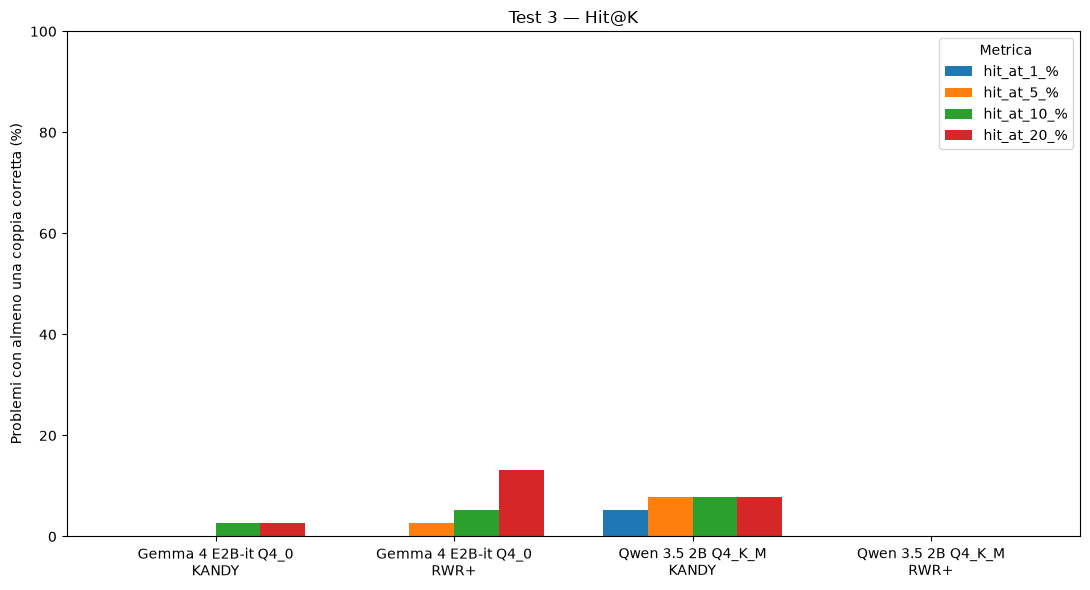

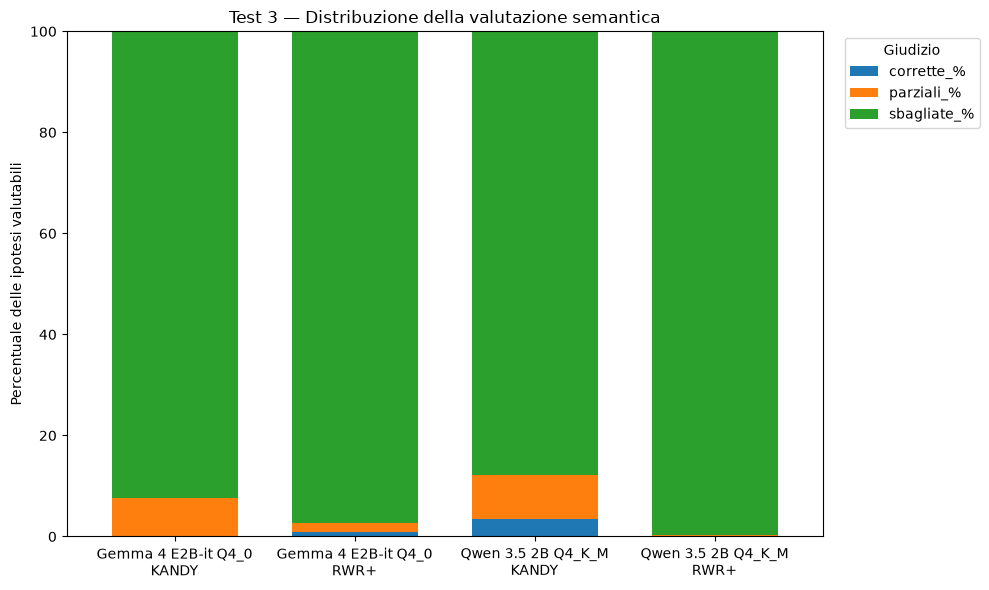

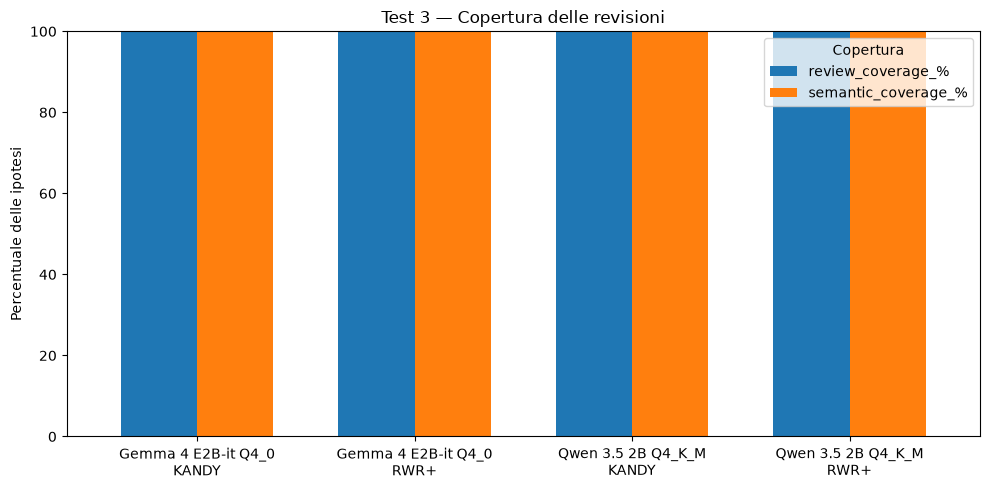

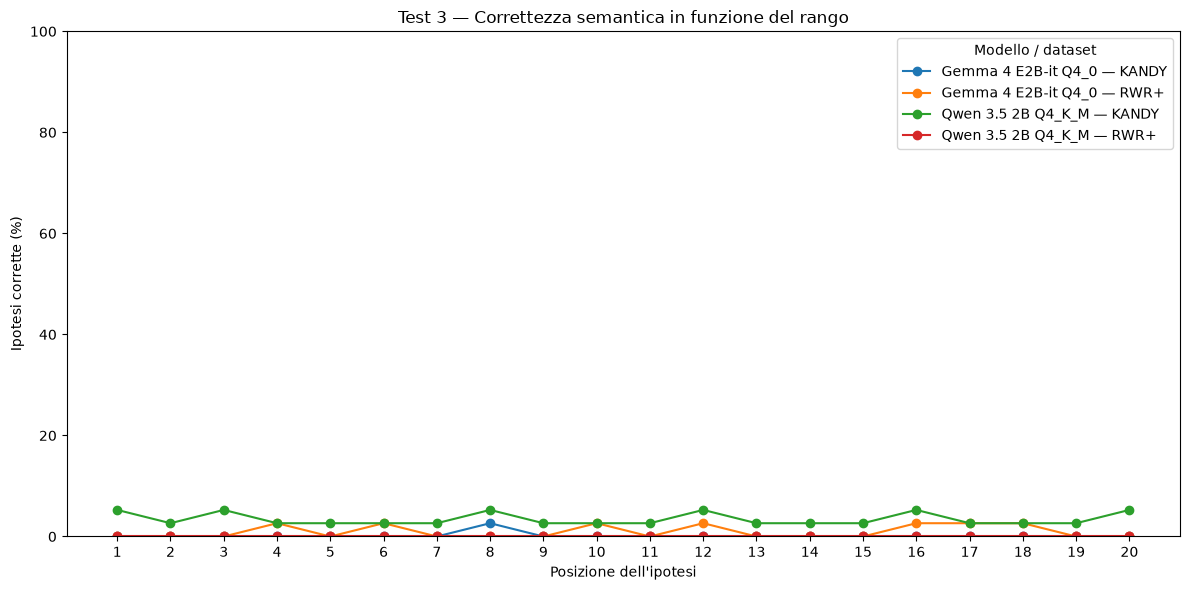

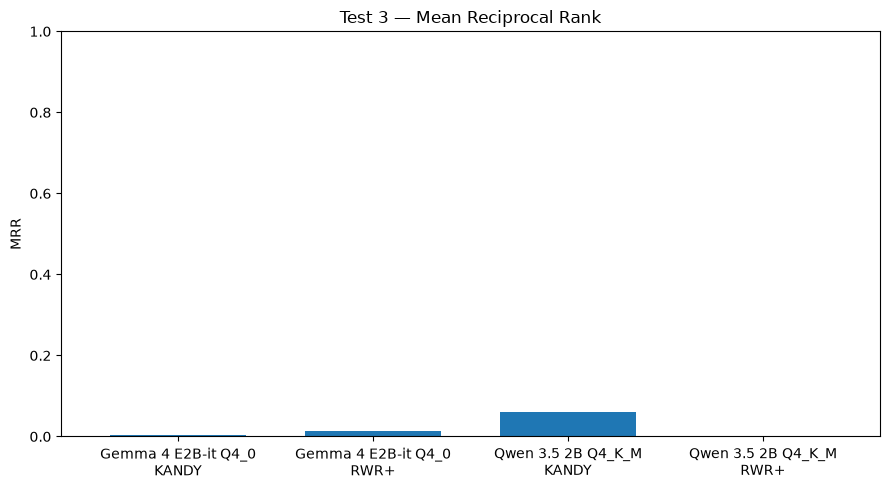


RIEPILOGO TEST 3
Problemi caricati: 152
Ipotesi estratte: 3040
Annotazioni semantiche trovate: 3040
File di revisione trovati: 2

Metriche salvate in: /home/cosimo/progetti/tesi/results/vlm_preliminary/metriche_test3


In [18]:
#TEST 3 - RISULTATI

import json
from pathlib import Path
import pandas as pd


#leggiamo i file jsonl
def leggi_jsonl_vlm(path):

    records = []

    with Path(path).open("r", encoding="utf-8") as file:

        for numero, line in enumerate(file, start=1):

            if not line.strip():
                continue

            try:
                records.append(json.loads(line))

            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"JSON non valido in {Path(path).name}, "
                    f"riga {numero}: {exc}"
                )

    return records


#carichiamo l'ultimo run disponibile per ciascun modello
def carica_ultimi_run(test_name, file_prefix):

    #individuiamo la cartella principale dei risultati
    if "EXPERIMENTS_DIR" in globals():

        search_root = Path(EXPERIMENTS_DIR).expanduser()

    elif "MODEL_RESULTS_DIR" in globals():

        search_root = Path(MODEL_RESULTS_DIR).expanduser().parent

    elif "PROJECT_ROOT" in globals():

        search_root = Path(PROJECT_ROOT).expanduser() / "experiments"

    else:

        search_root = Path.cwd()

    if not search_root.is_dir():
        raise FileNotFoundError(
            f"Cartella dei risultati non trovata: {search_root}"
        )

    #cerchiamo tutti i file del test richiesto
    candidates = list(
        search_root.rglob(f"{file_prefix}*.jsonl")
    )

    if not candidates:
        raise FileNotFoundError(
            f"Nessun file {file_prefix}*.jsonl trovato in "
            f"{search_root}"
        )

    #ordiniamo i file dal più recente al più vecchio
    candidates.sort(
        key=lambda path: path.stat().st_mtime,
        reverse=True
    )

    #conserviamo il run più recente per ciascun modello
    latest_by_model = {}

    for path in candidates:

        records = leggi_jsonl_vlm(path)

        for model in {
            str(record.get("model", "")).strip()
            for record in records
        }:

            if not model or model in latest_by_model:
                continue

            model_records = []

            for record in records:

                if str(record.get("model", "")).strip() != model:
                    continue

                record_test = record.get("test")

                #se il campo test esiste, deve corrispondere
                if record_test not in (None, "", test_name):
                    continue

                model_records.append(record)

            if model_records:
                latest_by_model[model] = (
                    path,
                    model_records
                )

    #uniamo i risultati selezionati
    loaded_records = []

    model_labels = {
        "qwen35_2b": "Qwen 3.5 2B",
        "gemma4_e2b_it": "Gemma 4 E2B-it"
    }

    for model, (path, records) in latest_by_model.items():

        for record in records:

            row = record.copy()

            #conserviamo il percorso per collegare le revisioni
            row["_source_jsonl"] = str(path.resolve())

            #aggiungiamo l'etichetta se non è già presente
            if not row.get("model_label"):
                row["model_label"] = model_labels.get(
                    model,
                    model
                )

            loaded_records.append(row)

        print(
            f"{model}: {len(records)} problemi caricati da {path}"
        )

    if not loaded_records:
        raise ValueError(
            f"Nessun risultato valido trovato per {test_name}."
        )

    return pd.DataFrame(loaded_records)


print("Funzioni di caricamento Test 3 definite.")

#normalizziamo i percorsi per collegare risultati e revisioni
def path_key_test3(value):

    if not value:
        return ""

    try:
        return str(
            Path(str(value)).expanduser().resolve()
        )

    except Exception:
        return str(value)


#normalizziamo i giudizi semantici
def normalizza_assessment_test3(value):

    value = str(value or "").strip().lower()

    mapping = {

        "correct": "correct",
        "corretta": "correct",

        "partial": "partial",
        "parziale": "partial",
        "parzialmente corretta": "partial",

        "incorrect": "incorrect",
        "sbagliata": "incorrect",

        "uncertain": "uncertain",
        "non valutabile": "uncertain",

        "not_reviewed": "not_reviewed"
    }

    return mapping.get(value, "not_reviewed")


#estraiamo le ipotesi dal record
def estrai_hypotheses_test3(record):

    parsed = (
        record.get("parsed_response")
        or record.get("parsed")
    )

    if not isinstance(parsed, dict):

        raw = str(record.get("raw_response") or "")

        try:
            parsed = parse_test3_response(raw)

        except Exception:
            parsed = None

    if not isinstance(parsed, dict):
        return []

    hypotheses = parsed.get("hypotheses", [])

    if not isinstance(hypotheses, list):
        return []

    return [
        hypothesis
        for hypothesis in hypotheses
        if isinstance(hypothesis, dict)
    ][:20]


#determiniamo Hit@K rispettando le revisioni mancanti
def calcola_hit_test3(assessments, k, partial_allowed=False):

    relevant = (
        {"correct", "partial"}
        if partial_allowed
        else {"correct"}
    )

    reviewed = {
        "correct",
        "partial",
        "incorrect"
    }

    first_k = assessments[:k]

    #abbiamo già trovato un'ipotesi positiva
    if any(value in relevant for value in first_k):
        return 1.0

    #non è stata generata nessuna ipotesi
    if len(first_k) == 0:
        return 0.0

    #se tutte le posizioni disponibili sono state revisionate
    #possiamo concludere che non esiste un hit
    if all(value in reviewed for value in first_k):
        return 0.0

    #almeno una posizione è ancora da valutare
    return np.nan


#calcoliamo MRR soltanto quando il rango è determinabile
def calcola_mrr_test3(assessments):

    reviewed = {
        "correct",
        "partial",
        "incorrect"
    }

    first_correct = None

    for rank, assessment in enumerate(assessments, start=1):

        if assessment == "correct":
            first_correct = rank
            break

    #se non esiste una coppia corretta
    if first_correct is None:

        if all(value in reviewed for value in assessments):
            return 0.0

        return np.nan

    #una posizione precedente non revisionata potrebbe
    #contenere una coppia corretta con rango migliore
    previous = assessments[:first_correct - 1]

    if not all(value in reviewed for value in previous):
        return np.nan

    return 1 / first_correct


#calcoliamo una percentuale senza divisioni per zero
def percentuale_test3(n, d):

    if d == 0:
        return np.nan

    return round(n / d * 100, 2)



test3_df = carica_ultimi_run(
    "test_3_generation_20",
    "test_3_generation_20"
)

if test3_df.empty:
    raise ValueError(
        "Non trovo risultati del Test 3."
    )


print("RUN DEL TEST 3")

display(
    test3_df[
        [
            "model",
            "dataset",
            "problem_id",
            "status",
            "elapsed_seconds"
        ]
    ]
)


#cerchiamo i file di revisione nelle cartelle dei risultati
search_roots_test3 = []

if "EXPERIMENTS_DIR" in globals():

    search_roots_test3.append(
        Path(EXPERIMENTS_DIR).resolve()
    )


#aggiungiamo le cartelle dei jsonl
for source in test3_df["_source_jsonl"].dropna().unique():

    search_roots_test3.append(
        Path(source).resolve().parent
    )


#aggiungiamo eventualmente la root del progetto
if "PROJECT_ROOT" in globals():

    search_roots_test3.append(
        Path(PROJECT_ROOT).resolve()
    )


#eliminiamo cartelle duplicate
search_roots_test3 = list({
    str(path): path
    for path in search_roots_test3
}.values())


review_paths_test3 = set()

for root in search_roots_test3:

    if root.is_dir():

        review_paths_test3.update(
            root.rglob("review_all_tests.jsonl")
        )


review_paths_test3 = sorted(review_paths_test3)

print("\nFile di revisione trovati:")

for path in review_paths_test3:
    print(path)


#carichiamo le annotazioni
review_records_test3 = []

for review_path in review_paths_test3:

    for annotation in leggi_jsonl_vlm(review_path):

        if annotation.get("test") != "test_3_generation_20":
            continue

        review_records_test3.append(annotation)


print(
    "\nAnnotazioni Test 3 caricate:",
    len(review_records_test3)
)



review_lookup_test3 = {}

for annotation in review_records_test3:

    source = path_key_test3(
        annotation.get("source_jsonl")
    )

    model = str(
        annotation.get("model", "")
    )

    task_id = str(
        annotation.get("task_id", "")
    )

    #il revisore salva il rango e, come fallback, item_key
    rank_value = annotation.get("rank")

    if rank_value is None:
        rank_value = annotation.get("item_key")

    try:
        rank = int(rank_value)

    except (TypeError, ValueError):
        continue

    key = (
        source,
        model,
        task_id,
        rank
    )

    assessment = normalizza_assessment_test3(
        annotation.get("assessment")
    )

    #se esistono più revisioni dello stesso elemento
    #manteniamo quella aggiornata più recentemente
    previous = review_lookup_test3.get(key)

    updated_at = str(
        annotation.get("updated_at", "")
    )

    if (
        previous is None
        or updated_at >= previous["updated_at"]
    ):

        review_lookup_test3[key] = {

            "assessment": assessment,
            "updated_at": updated_at
        }


#indice degli output non interpretabili
unparsed_lookup_test3 = {}

for annotation in review_records_test3:

    if annotation.get("item_type") != "generation_output":
        continue

    key = (
        path_key_test3(annotation.get("source_jsonl")),
        str(annotation.get("model", "")),
        str(annotation.get("task_id", ""))
    )

    unparsed_lookup_test3[key] = normalizza_assessment_test3(
        annotation.get("assessment")
    )


print(
    "Ipotesi con annotazione:",
    len(review_lookup_test3)
)

hypothesis_rows = []
problem_rows = []

for record in test3_df.to_dict("records"):

    hypotheses = estrai_hypotheses_test3(record)

    source_key = path_key_test3(
        record.get("_source_jsonl")
    )

    task_id = str(
        record.get("task_id", "")
    )

    model = str(
        record.get("model", "")
    )

    model_label = record.get("model_label", model)
    dataset = record.get("dataset")
    problem_id = record.get("problem_id")

    assessments = []


    #recuperiamo il giudizio di ogni ipotesi
    for rank, hypothesis in enumerate(
        hypotheses,
        start=1
    ):

        review_key = (
            source_key,
            model,
            task_id,
            rank
        )

        annotation = review_lookup_test3.get(review_key)

        assessment = (
            annotation["assessment"]
            if annotation is not None
            else "not_reviewed"
        )

        assessments.append(assessment)

        hypothesis_rows.append({

            "model": model,
            "model_label": model_label,
            "dataset": dataset,
            "problem_id": problem_id,
            "task_id": task_id,

            "rank": rank,

            "left_rule": hypothesis.get("left_rule", ""),
            "right_rule": hypothesis.get("right_rule", ""),

            "assessment": assessment,

            "source_jsonl": record.get("_source_jsonl")
        })


    #conteggi delle revisioni
    n_hypotheses = len(hypotheses)

    n_correct = assessments.count("correct")
    n_partial = assessments.count("partial")
    n_incorrect = assessments.count("incorrect")
    n_uncertain = assessments.count("uncertain")
    n_not_reviewed = assessments.count("not_reviewed")

    n_reviewed = (
        n_correct
        + n_partial
        + n_incorrect
        + n_uncertain
    )

    n_assessable = (
        n_correct
        + n_partial
        + n_incorrect
    )


    #completezza della revisione
    review_complete = (
        n_hypotheses > 0
        and n_not_reviewed == 0
    )

    semantic_review_complete = (
        n_hypotheses > 0
        and n_assessable == n_hypotheses
    )


    #Hit@K
    hit_at_1 = calcola_hit_test3(
        assessments, 1
    )

    hit_at_5 = calcola_hit_test3(
        assessments, 5
    )

    hit_at_10 = calcola_hit_test3(
        assessments, 10
    )

    hit_at_20 = calcola_hit_test3(
        assessments, 20
    )


    #Hit@20 meno rigoroso: corretto o parziale
    partial_hit_at_20 = calcola_hit_test3(
        assessments,
        20,
        partial_allowed=True
    )


    #MRR: reciprocal rank della prima coppia interamente corretta
    mrr = calcola_mrr_test3(
        assessments
    )


    #primo rango sicuramente positivo, se presente
    correct_ranks = [
        rank
        for rank, assessment in enumerate(
            assessments,
            start=1
        )
        if assessment == "correct"
    ]

    first_correct_rank = (
        min(correct_ranks)
        if correct_ranks else np.nan
    )


    #controlliamo eventuali output non interpretabili
    unparsed_key = (
        source_key,
        model,
        task_id
    )

    unparsed_assessment = unparsed_lookup_test3.get(
        unparsed_key,
        "not_reviewed"
    )


    problem_rows.append({

        "model": model,
        "model_label": model_label,
        "dataset": dataset,
        "problem_id": problem_id,
        "task_id": task_id,

        "num_hypotheses": n_hypotheses,
        "output_20": n_hypotheses == 20,

        "status": record.get("status"),
        "finish_reason": record.get("finish_reason"),

        "ipotesi_corrette": n_correct,
        "ipotesi_parziali": n_partial,
        "ipotesi_sbagliate": n_incorrect,
        "ipotesi_non_valutabili": n_uncertain,
        "ipotesi_non_revisionate": n_not_reviewed,

        "ipotesi_revisionate": n_reviewed,
        "ipotesi_valutabili": n_assessable,

        "review_complete": review_complete,
        "semantic_review_complete": semantic_review_complete,

        "hit_at_1": hit_at_1,
        "hit_at_5": hit_at_5,
        "hit_at_10": hit_at_10,
        "hit_at_20": hit_at_20,

        "partial_hit_at_20": partial_hit_at_20,

        "first_correct_rank": first_correct_rank,
        "mrr": mrr,

        "unparsed_output_assessment": unparsed_assessment,

        "elapsed_seconds": record.get("elapsed_seconds"),
        "source_jsonl": record.get("_source_jsonl")
    })


ipotesi_test3 = pd.DataFrame(hypothesis_rows)
problemi_test3 = pd.DataFrame(problem_rows)


metriche_test3 = []

for (model, dataset), frame in problemi_test3.groupby(
    ["model_label", "dataset"],
    dropna=False
):

    n_problems = len(frame)

    row = {

        "model": model,
        "dataset": dataset,

        "problemi": n_problems,

        "output_con_20_ipotesi": int(
            frame["output_20"].sum()
        ),

        "output_con_20_ipotesi_%": percentuale_test3(
            int(frame["output_20"].sum()),
            n_problems
        ),

        "ipotesi_medie_generate": round(
            frame["num_hypotheses"].mean(), 2
        ) if n_problems else np.nan,

        "problemi_con_revisione_completa": int(
            frame["review_complete"].sum()
        ),

        "revisione_completa_%": percentuale_test3(
            int(frame["review_complete"].sum()),
            n_problems
        ),

        "problemi_con_revisione_semantica_completa": int(
            frame["semantic_review_complete"].sum()
        ),

        "revisione_semantica_completa_%": percentuale_test3(
            int(frame["semantic_review_complete"].sum()),
            n_problems
        )
    }


    #metriche Hit@K e copertura
    for k in [1, 5, 10, 20]:

        column = f"hit_at_{k}"

        valid = frame[column].dropna()

        row[f"problemi_hit{k}_valutabili"] = len(valid)

        row[f"copertura_hit{k}_%"] = percentuale_test3(
            len(valid),
            n_problems
        )

        row[f"hit_at_{k}_%"] = round(
            valid.mean() * 100, 2
        ) if not valid.empty else np.nan


    #misura meno rigorosa: corretta o parziale
    partial_valid = frame["partial_hit_at_20"].dropna()

    row["partial_hit_at_20_%"] = round(
        partial_valid.mean() * 100, 2
    ) if not partial_valid.empty else np.nan


    #MRR
    valid_mrr = frame["mrr"].dropna()

    row["problemi_mrr_valutabili"] = len(valid_mrr)

    row["mrr"] = round(
        valid_mrr.mean(), 4
    ) if not valid_mrr.empty else np.nan


    #rango medio della prima ipotesi corretta
    valid_ranks = frame["first_correct_rank"].dropna()

    row["primo_rango_corretto_medio"] = round(
        valid_ranks.mean(), 2
    ) if not valid_ranks.empty else np.nan


    #media delle ipotesi corrette per problema
    row["ipotesi_corrette_medie"] = round(
        frame["ipotesi_corrette"].mean(), 2
    )


    metriche_test3.append(row)


metriche_test3 = pd.DataFrame(metriche_test3)

CATEGORIE_TEST3 = [
    "correct",
    "partial",
    "incorrect",
    "uncertain",
    "not_reviewed"
]


if not ipotesi_test3.empty:

    semantica_test3 = (
        ipotesi_test3
        .groupby(
            ["model_label", "dataset", "assessment"],
            dropna=False
        )
        .size()
        .unstack(fill_value=0)
        .reindex(
            columns=CATEGORIE_TEST3,
            fill_value=0
        )
    )

    #percentuali sul totale delle ipotesi generate
    semantica_test3_pct = semantica_test3.div(
        semantica_test3.sum(axis=1).replace(0, np.nan),
        axis=0
    ) * 100

else:

    semantica_test3 = pd.DataFrame()
    semantica_test3_pct = pd.DataFrame()


#metriche semantiche aggregate
metriche_semantiche_test3 = []

for (model, dataset), frame in ipotesi_test3.groupby(
    ["model_label", "dataset"],
    dropna=False
):

    counts = frame["assessment"].value_counts()

    n_total = len(frame)

    n_correct = int(counts.get("correct", 0))
    n_partial = int(counts.get("partial", 0))
    n_incorrect = int(counts.get("incorrect", 0))
    n_uncertain = int(counts.get("uncertain", 0))
    n_not_reviewed = int(counts.get("not_reviewed", 0))

    n_assessable = (
        n_correct + n_partial + n_incorrect
    )

    n_reviewed = (
        n_assessable + n_uncertain
    )

    metriche_semantiche_test3.append({

        "model": model,
        "dataset": dataset,

        "ipotesi_generate": n_total,

        "corrette": n_correct,
        "parziali": n_partial,
        "sbagliate": n_incorrect,

        "non_valutabili": n_uncertain,
        "non_revisionate": n_not_reviewed,

        "review_coverage_%": percentuale_test3(
            n_reviewed,
            n_total
        ),

        "semantic_coverage_%": percentuale_test3(
            n_assessable,
            n_total
        ),

        "corrette_%": percentuale_test3(
            n_correct,
            n_assessable
        ),

        "parziali_%": percentuale_test3(
            n_partial,
            n_assessable
        ),

        "sbagliate_%": percentuale_test3(
            n_incorrect,
            n_assessable
        )
    })


metriche_semantiche_test3 = pd.DataFrame(
    metriche_semantiche_test3
)


metriche_rango_test3 = []

if not ipotesi_test3.empty:

    for (model, dataset, rank), frame in ipotesi_test3.groupby(
        ["model_label", "dataset", "rank"],
        dropna=False
    ):

        counts = frame["assessment"].value_counts()

        n = len(frame)

        n_correct = int(counts.get("correct", 0))
        n_partial = int(counts.get("partial", 0))
        n_incorrect = int(counts.get("incorrect", 0))

        n_assessable = (
            n_correct + n_partial + n_incorrect
        )

        metriche_rango_test3.append({

            "model": model,
            "dataset": dataset,
            "rank": rank,

            "ipotesi_generate": n,

            "corrette": n_correct,
            "parziali": n_partial,
            "sbagliate": n_incorrect,

            "valutate": n_assessable,

            "corrette_%": percentuale_test3(
                n_correct,
                n_assessable
            )
        })


metriche_rango_test3 = pd.DataFrame(
    metriche_rango_test3
)


metriche_tecniche_test3 = (
    test3_df
    .groupby(
        ["model_label", "dataset"],
        dropna=False
    )
    .agg(

        problemi=("task_id", "count"),

        tempo_medio_s=("elapsed_seconds", "mean"),

        tempo_mediano_s=("elapsed_seconds", "median"),

        tempo_totale_s=("elapsed_seconds", "sum")
    )
    .reset_index()
)


#aggiungiamo gli stati delle risposte
status_counts_test3 = (
    test3_df
    .groupby(
        ["model_label", "dataset", "status"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

metriche_tecniche_test3 = metriche_tecniche_test3.merge(
    status_counts_test3,
    on=["model_label", "dataset"],
    how="left"
)


metriche_tecniche_test3["tempo_medio_s"] = (
    metriche_tecniche_test3["tempo_medio_s"].round(2)
)

metriche_tecniche_test3["tempo_mediano_s"] = (
    metriche_tecniche_test3["tempo_mediano_s"].round(2)
)

metriche_tecniche_test3["tempo_totale_min"] = (
    metriche_tecniche_test3["tempo_totale_s"] / 60
).round(2)


paired_test3 = problemi_test3.pivot_table(

    index=["dataset", "problem_id"],

    columns="model",

    values=[
        "hit_at_20",
        "mrr"
    ],

    aggfunc="first"
)


if not paired_test3.empty:

    paired_test3.columns = [
        f"{metric}_{model}"
        for metric, model in paired_test3.columns
    ]

    paired_test3 = paired_test3.reset_index()


    if {
        "hit_at_20_qwen35_2b",
        "hit_at_20_gemma4_e2b_it"
    }.issubset(paired_test3.columns):

        valid_pairs = paired_test3.dropna(
            subset=[
                "hit_at_20_qwen35_2b",
                "hit_at_20_gemma4_e2b_it"
            ]
        ).copy()

        valid_pairs["confronto_hit20"] = np.select(
            [

                valid_pairs["hit_at_20_qwen35_2b"]
                > valid_pairs["hit_at_20_gemma4_e2b_it"],

                valid_pairs["hit_at_20_qwen35_2b"]
                < valid_pairs["hit_at_20_gemma4_e2b_it"]
            ],

            [
                "Qwen migliore",
                "Gemma migliore"
            ],

            default="Parità"
        )

        paired_test3 = valid_pairs

    else:

        paired_test3 = pd.DataFrame()

else:

    paired_test3 = pd.DataFrame()


TEST3_METRICS_DIR = (
    Path(EXPERIMENTS_DIR) / "metriche_test3"
)

TEST3_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("\n1. HIT@K E RANKING")

display(metriche_test3)


print("\n2. METRICHE SEMANTICHE")

display(metriche_semantiche_test3)


print("\n3. DETTAGLIO DELLA REVISIONE")

display(semantica_test3)


print("\n4. ANALISI PER POSIZIONE DELL'IPOTESI")

display(metriche_rango_test3)


print("\n5. METRICHE TECNICHE")

display(metriche_tecniche_test3)


print("\n6. DETTAGLIO PER PROBLEMA")

display(
    problemi_test3[
        [
            "model_label",
            "dataset",
            "problem_id",
            "num_hypotheses",
            "ipotesi_corrette",
            "ipotesi_parziali",
            "ipotesi_sbagliate",
            "ipotesi_revisionate",
            "hit_at_1",
            "hit_at_5",
            "hit_at_10",
            "hit_at_20",
            "mrr"
        ]
    ]
)


if not paired_test3.empty:

    print("\n7. CONFRONTO DIRETTO QWEN / GEMMA")

    display(paired_test3["confronto_hit20"].value_counts())


ipotesi_test3.to_csv(
    TEST3_METRICS_DIR / "test3_dettaglio_ipotesi.csv",
    index=False
)

problemi_test3.to_csv(
    TEST3_METRICS_DIR / "test3_dettaglio_problemi.csv",
    index=False
)

metriche_test3.to_csv(
    TEST3_METRICS_DIR / "test3_hit_at_k_mrr.csv",
    index=False
)

metriche_semantiche_test3.to_csv(
    TEST3_METRICS_DIR / "test3_metriche_semantiche.csv",
    index=False
)

semantica_test3.to_csv(
    TEST3_METRICS_DIR / "test3_semantica_conteggi.csv"
)

metriche_rango_test3.to_csv(
    TEST3_METRICS_DIR / "test3_metriche_per_rango.csv",
    index=False
)

metriche_tecniche_test3.to_csv(
    TEST3_METRICS_DIR / "test3_metriche_tecniche.csv",
    index=False
)

paired_test3.to_csv(
    TEST3_METRICS_DIR / "test3_confronto_modelli.csv",
    index=False
)


if not metriche_test3.empty:

    plot_hit = metriche_test3.copy()

    plot_hit["gruppo"] = (
        plot_hit["model"]
        + "\n"
        + plot_hit["dataset"]
    )

    plot_hit = plot_hit.set_index("gruppo")[
        [
            "hit_at_1_%",
            "hit_at_5_%",
            "hit_at_10_%",
            "hit_at_20_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(11, 6))

    plot_hit.plot(
        kind="bar",
        ax=ax,
        width=0.75
    )

    ax.set_title("Test 3 — Hit@K")
    ax.set_ylabel("Problemi con almeno una coppia corretta (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)

    ax.legend(
        title="Metrica"
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    fig.tight_layout()

    fig.savefig(
        TEST3_METRICS_DIR / "01_hit_at_k.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


if not metriche_semantiche_test3.empty:

    plot_semantic = metriche_semantiche_test3.copy()

    plot_semantic["gruppo"] = (
        plot_semantic["model"]
        + "\n"
        + plot_semantic["dataset"]
    )

    plot_semantic = plot_semantic.set_index(
        "gruppo"
    )[
        [
            "corrette_%",
            "parziali_%",
            "sbagliate_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(10, 6))

    plot_semantic.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        width=0.7
    )

    ax.set_title(
        "Test 3 — Distribuzione della valutazione semantica"
    )

    ax.set_ylabel(
        "Percentuale delle ipotesi valutabili"
    )

    ax.set_xlabel("")
    ax.set_ylim(0, 100)

    ax.legend(
        title="Giudizio",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    fig.tight_layout()

    fig.savefig(
        TEST3_METRICS_DIR / "02_semantica_ipotesi.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


if not metriche_semantiche_test3.empty:

    plot_coverage = metriche_semantiche_test3.copy()

    plot_coverage["gruppo"] = (
        plot_coverage["model"]
        + "\n"
        + plot_coverage["dataset"]
    )

    plot_coverage = plot_coverage.set_index(
        "gruppo"
    )[
        [
            "review_coverage_%",
            "semantic_coverage_%"
        ]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    plot_coverage.plot(
        kind="bar",
        ax=ax,
        width=0.7
    )

    ax.set_title(
        "Test 3 — Copertura delle revisioni"
    )

    ax.set_ylabel("Percentuale delle ipotesi")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)

    ax.legend(
        title="Copertura"
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    fig.tight_layout()

    fig.savefig(
        TEST3_METRICS_DIR / "03_copertura_revisioni.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


if not metriche_rango_test3.empty:

    fig, ax = plt.subplots(figsize=(12, 6))

    for (model, dataset), frame in metriche_rango_test3.groupby(
        ["model", "dataset"]
    ):

        frame = frame.sort_values("rank")

        ax.plot(
            frame["rank"],
            frame["corrette_%"],
            marker="o",
            label=f"{model} — {dataset}"
        )

    ax.set_title(
        "Test 3 — Correttezza semantica in funzione del rango"
    )

    ax.set_xlabel("Posizione dell'ipotesi")
    ax.set_ylabel("Ipotesi corrette (%)")
    ax.set_xticks(range(1, 21))
    ax.set_ylim(0, 100)

    ax.legend(
        title="Modello / dataset"
    )

    fig.tight_layout()

    fig.savefig(
        TEST3_METRICS_DIR / "04_correttezza_per_rango.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


if not metriche_test3.empty:

    plot_mrr = metriche_test3.copy()

    plot_mrr["gruppo"] = (
        plot_mrr["model"]
        + "\n"
        + plot_mrr["dataset"]
    )

    plot_mrr = plot_mrr.set_index("gruppo")[
        ["mrr"]
    ]

    fig, ax = plt.subplots(figsize=(9, 5))

    plot_mrr.plot(
        kind="bar",
        ax=ax,
        legend=False,
        width=0.7
    )

    ax.set_title("Test 3 — Mean Reciprocal Rank")
    ax.set_ylabel("MRR")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)

    ax.tick_params(
        axis="x",
        rotation=0
    )

    fig.tight_layout()

    fig.savefig(
        TEST3_METRICS_DIR / "05_mrr.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


print("\nRIEPILOGO TEST 3")

print(
    "Problemi caricati:",
    len(problemi_test3)
)

print(
    "Ipotesi estratte:",
    len(ipotesi_test3)
)

print(
    "Annotazioni semantiche trovate:",
    sum(
        ipotesi_test3["assessment"].isin(
            ["correct", "partial", "incorrect"]
        )
    ) if not ipotesi_test3.empty else 0
)

print(
    "File di revisione trovati:",
    len(review_paths_test3)
)

if not review_paths_test3:

    print(
        "\nATTENZIONE: non trovo review_all_tests.jsonl. "
        "Le ipotesi risultano ancora non revisionate."
    )

print(
    "\nMetriche salvate in:",
    TEST3_METRICS_DIR
)

## Quarto Test - Contesto KANDY Target RWR+

Nel quarto test viene valutata la capacità di applicare la regola astratta a un target concreto: a ogni richiesta vengono presentate due immagini composte da esempi appartenenti rispettivamente ai gruppi LEFT e RIGHT di una matrice Bongard del dataset KANDY, viene poi proposta una terza immagine, proveniente dal dataset RWR+, la quale costituisce il target da classificare. Il modello deve quindi individuare la caratteristica visiva o la relazione che distingue i due gruppi di riferimento e applicarla all'immagine target, stabilendo se questa appartenga al gruppo LEFT oppure al gruppo RIGHT.

In [31]:
#PREPARAZIONE DEI TASK DEL QUARTO TEST

from math import ceil


if not Path(CROSS_TEST_MANIFEST_PATH).is_file():
    raise FileNotFoundError(
        f"Manifest cross-dataset non trovato: {CROSS_TEST_MANIFEST_PATH}"
    )


test4_manifest = pd.read_csv(CROSS_TEST_MANIFEST_PATH)

required_test4_columns = {
    "problem_id",
    "target_image",
    "target_gold_side",
    "left_context_kandy",
    "right_context_kandy"
}

missing_columns = required_test4_columns - set(test4_manifest.columns)

if missing_columns:
    raise ValueError(
        f"Colonne mancanti nel manifest Test 4: {missing_columns}"
    )

if test4_manifest.empty:
    raise ValueError("Il manifest cross-dataset è vuoto.")


#risolviamo i percorsi relativi a OVERLAP_DIR
def resolve_overlap_image(image_ref):

    path = Path(str(image_ref))

    if not path.is_absolute():
        path = Path(OVERLAP_DIR) / path

    path = path.resolve()

    if not path.is_file():
        raise FileNotFoundError(
            f"Immagine cross-dataset non trovata: {path}"
        )

    return path


#leggiamo le liste di immagini dal manifest
def parse_manifest_image_list(value):

    if isinstance(value, list):
        return [str(path) for path in value]

    if pd.isna(value):
        return []

    paths = json.loads(str(value))

    if not isinstance(paths, list):
        raise ValueError("Una lista di immagini del manifest non è valida.")

    return [str(path) for path in paths]


#creiamo un foglio visivo con le immagini di un lato
def crea_foglio_contesto(image_paths, output_path):

    if not image_paths:
        raise ValueError("Il foglio di contesto non può essere vuoto.")

    tile_width = 280
    tile_height = 280
    columns = 3
    rows = ceil(len(image_paths) / columns)
    margin = 14

    sheet_width = (
        columns * tile_width +
        (columns + 1) * margin
    )

    sheet_height = (
        rows * tile_height +
        (rows + 1) * margin
    )

    sheet = Image.new(
        "RGB",
        (sheet_width, sheet_height),
        "white"
    )

    resampling = getattr(Image, "Resampling", Image).LANCZOS

    for index, image_path in enumerate(image_paths):

        with Image.open(image_path) as image:
            tile = image.convert("RGB")

        tile.thumbnail(
            (tile_width, tile_height),
            resampling
        )

        column = index % columns
        row = index // columns

        x = (
            margin +
            column * (tile_width + margin) +
            (tile_width - tile.width) // 2
        )

        y = (
            margin +
            row * (tile_height + margin) +
            (tile_height - tile.height) // 2
        )

        sheet.paste(tile, (x, y))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    sheet.save(output_path)

    return output_path


#cartella condivisa degli input visivi
TEST4_INPUTS_DIR = (
    Path(EXPERIMENTS_DIR) / "test4_shared_inputs"
)

TEST4_INPUTS_DIR.mkdir(parents=True, exist_ok=True)


#prepariamo gli episodi
TEST4_TASKS = []
sheet_cache = {}

for _, row in test4_manifest.iterrows():

    problem_id = str(row["problem_id"])
    gold_side = str(row["target_gold_side"]).strip().lower()

    if gold_side not in ["left", "right"]:
        raise ValueError(
            f"Lato gold non valido per {problem_id}: {gold_side}"
        )

    left_refs = parse_manifest_image_list(
        row["left_context_kandy"]
    )

    right_refs = parse_manifest_image_list(
        row["right_context_kandy"]
    )

    if not left_refs or not right_refs:
        raise ValueError(
            f"Contesto vuoto per il problema {problem_id}"
        )

    left_paths = [
        resolve_overlap_image(path)
        for path in left_refs
    ]

    right_paths = [
        resolve_overlap_image(path)
        for path in right_refs
    ]

    target_path = resolve_overlap_image(
        row["target_image"]
    )


    #il contesto è uguale per i due target dello stesso problema
    if problem_id not in sheet_cache:

        safe_problem_id = re.sub(
            r"[^A-Za-z0-9_.-]+",
            "_",
            problem_id
        )

        problem_input_dir = (
            TEST4_INPUTS_DIR / safe_problem_id
        )

        left_sheet = crea_foglio_contesto(
            left_paths,
            problem_input_dir / "context_left.png"
        )

        right_sheet = crea_foglio_contesto(
            right_paths,
            problem_input_dir / "context_right.png"
        )

        sheet_cache[problem_id] = {
            "left_sheet": left_sheet,
            "right_sheet": right_sheet
        }


    sheets = sheet_cache[problem_id]

    TEST4_TASKS.append({

        "task_id": f"cross::{problem_id}::{gold_side}",

        "dataset": "Cross-dataset",
        "problem_id": problem_id,

        "left_context_paths": left_paths,
        "right_context_paths": right_paths,

        "left_sheet_path": sheets["left_sheet"],
        "right_sheet_path": sheets["right_sheet"],

        "target_path": target_path,
        "correct_side": gold_side,

        "kandy_count_left": len(left_paths),
        "kandy_count_right": len(right_paths)
    })


if not TEST4_TASKS:
    raise ValueError("Nessun episodio disponibile per il Test 4.")


#controlliamo che ogni problema abbia entrambi i target
test4_gold_sides = (
    pd.DataFrame(TEST4_TASKS)
    .groupby("problem_id")["correct_side"]
    .apply(set)
)

incomplete_problems = [
    problem_id
    for problem_id, sides in test4_gold_sides.items()
    if sides != {"left", "right"}
]

if incomplete_problems:
    raise ValueError(
        "Alcuni problemi non hanno entrambi i target: "
        f"{incomplete_problems}"
    )


#riepilogo
print("Problemi cross-dataset:", test4_manifest["problem_id"].nunique())
print("Episodi Test 4:", len(TEST4_TASKS))
print("Richieste previste per modello:", len(TEST4_TASKS))

display(
    pd.DataFrame([
        {
            "problem_id": task["problem_id"],
            "target_gold": task["correct_side"],
            "contesto_left": task["kandy_count_left"],
            "contesto_right": task["kandy_count_right"],
            "target_path": str(task["target_path"])
        }
        for task in TEST4_TASKS
    ])
)

Problemi cross-dataset: 3
Episodi Test 4: 6
Richieste previste per modello: 6


,problem_id,target_gold,contesto_left,contesto_right,target_path
0,easy-0__Q05,left,5,5,/home/cosimo/progetti/tesi/data/processed/data...
1,easy-0__Q05,right,5,5,/home/cosimo/progetti/tesi/data/processed/data...
2,easy-2__Q08,left,5,5,/home/cosimo/progetti/tesi/data/processed/data...
3,easy-2__Q08,right,5,5,/home/cosimo/progetti/tesi/data/processed/data...
4,hard-2__Q37,left,2,5,/home/cosimo/progetti/tesi/data/processed/data...
5,hard-2__Q37,right,2,5,/home/cosimo/progetti/tesi/data/processed/data...


In [32]:
#QUARTO TEST - GENERALIZZAZIONE CROSS-DATASET

#prompt di sistema
system_prompt_test4 = """
You are an expert in visual concept recognition and Bongard problems.

Your task is to classify a target image using two groups of visual examples.

You will receive three images:
1. A contact sheet containing examples from the LEFT group.
2. A contact sheet containing examples from the RIGHT group.
3. A single target image to classify.

The examples come from KANDY.
The target image comes from a different visual dataset.

Your task is to transfer the visual concept distinguishing the
LEFT and RIGHT groups to the target image.

First, identify the visual property or relationship that
distinguishes the two context groups.

Then examine the target image and determine which of these
two concepts it is more consistent with.

IMPORTANT:
- Do not classify based only on object identity or image category.
- Do not assume that the target must look similar to the examples
  in terms of background, photographic style or depicted objects.
- Focus on potentially transferable visual properties and
  relationships, such as color, shape, number, arrangement,
  orientation, size, composition and spatial relationships.
- Compare the target against the distinguishing features of
  BOTH groups.
- Do not conclude that neither group applies. You must select
  the group that best matches the relevant visual concept.
- Do not invent visual properties that cannot be observed.
- Do not use external knowledge.

You must make exactly ONE classification.

The classification field must contain exactly one of these values:
LEFT
RIGHT

The text "LEFT or RIGHT" is NOT a valid classification.
Never reproduce both alternatives in the answer.

Your answer must follow exactly this format:

CLASSIFICATION: [ONE CHOICE]
EXPLANATION: [One or two concise sentences, maximum 35 words.]

Explain which visible property or relationship supports
your classification.

Do not include any additional text.
"""


#prompt utente
user_prompt_test4 = """
The first attached image contains examples from the LEFT group.
The second attached image contains examples from the RIGHT group.
The third attached image is the target.

Determine which group the target belongs to.

Compare the distinguishing visual properties of both context
groups with the target.

Remember that the target comes from a different dataset.
Its objects and visual style may differ from the context images.

Look for the underlying visual property or relationship that
transfers across the two datasets.

You MUST choose exactly one group.

Return exactly two fields:

CLASSIFICATION: LEFT

or

CLASSIFICATION: RIGHT

Choose only one of these classifications.
Do not write "LEFT or RIGHT" in the classification field.

EXPLANATION: Briefly describe the visible feature or relationship
that supports your choice.

Do not provide additional text.
"""


#convertiamo le immagini in base64
def image_to_data_url_test4(image_path):

    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(image_path)

    mime_type, _ = mimetypes.guess_type(image_path.name)

    if not mime_type or not mime_type.startswith("image/"):
        raise ValueError(
            f"Formato immagine non riconosciuto: {image_path}"
        )

    encoded = base64.b64encode(
        image_path.read_bytes()
    ).decode("utf-8")

    return f"data:{mime_type};base64,{encoded}"


#estraiamo classificazione e spiegazione
def parse_test4_response(raw_response):

    text = re.sub(
        r"```[a-zA-Z]*|```",
        "",
        str(raw_response or "")
    ).strip()

    if not text:
        return None

    #rimuoviamo eventuale formattazione markdown
    text = text.replace("**", "").replace("__", "")

    #proviamo prima a interpretare un eventuale json
    try:

        data = json.loads(text)

        if isinstance(data, dict):

            classification = (
                data.get("classification")
                or data.get("prediction")
                or data.get("answer")
            )

            classification = str(
                classification or ""
            ).strip().lower()

            explanation = (
                data.get("explanation")
                or data.get("rationale")
                or data.get("justification")
                or ""
            )

            if classification in ["left", "right"]:

                return {
                    "classification": classification,
                    "explanation": str(explanation).strip()
                }

    except (json.JSONDecodeError, TypeError):
        pass


    #cerchiamo una classificazione esplicita su una riga
    classification_match = re.search(
        r"^\s*(?:CLASSIFICATION|ANSWER)\s*:\s*(LEFT|RIGHT)\s*[.!]?\s*$",
        text,
        flags=re.IGNORECASE | re.MULTILINE
    )

    #fallback per risposte composte da LEFT o RIGHT nella prima riga
    if classification_match is None:

        lines = [
            line.strip()
            for line in text.splitlines()
            if line.strip()
        ]

        if lines and lines[0].upper() in ["LEFT", "RIGHT"]:

            classification = lines[0].lower()

        else:

            return None

    else:

        classification = classification_match.group(1).lower()


    #estraiamo separatamente la spiegazione
    explanation_match = re.search(
        r"^\s*EXPLANATION\s*:\s*(.*?)(?=\n\s*(?:CLASSIFICATION|ANSWER)\s*:|\Z)",
        text,
        flags=re.IGNORECASE | re.MULTILINE | re.DOTALL
    )

    explanation = (
        explanation_match.group(1).strip()
        if explanation_match else ""
    )

    return {
        "classification": classification,
        "explanation": explanation
    }


#recuperiamo il modello caricato nel server
model_response = requests.get(
    f"{BASE_URL}/models",
    timeout=10
)

model_response.raise_for_status()

available_models = model_response.json().get("data", [])

if not available_models:
    raise RuntimeError(
        "Nessun modello disponibile nel server."
    )

SERVER_MODEL_NAME = available_models[0]["id"]

print("Modello selezionato:", ACTIVE_MODEL)
print("Modello caricato nel server:", SERVER_MODEL_NAME)


#prepariamo il file dei risultati
run_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

RESULT_FILE = MODEL_RESULTS_DIR / (
    f"test_4_context_generalization_{run_timestamp}.jsonl"
)

records = []


#eseguiamo una richiesta per ogni target
for index, task in enumerate(TEST4_TASKS, start=1):

    print(
        f"\nEpisodio {index}/{len(TEST4_TASKS)}: "
        f"{task['problem_id']} - target {task['correct_side']}"
    )

    start_time = time.perf_counter()
    response = None

    left_sheet = Path(task["left_sheet_path"])
    right_sheet = Path(task["right_sheet_path"])
    target_path = Path(task["target_path"])

    input_paths = [
        left_sheet,
        right_sheet,
        target_path
    ]

    input_paths_relative = [
        str(path.relative_to(PROJECT_ROOT))
        for path in input_paths
    ]

    target_path_relative = str(
        target_path.relative_to(PROJECT_ROOT)
    )


    record = {

        "test": "test_4_context_generalization",
        "task_id": task["task_id"],

        "model": ACTIVE_MODEL,
        "model_label": MODEL_LABEL,
        "server_model_name": SERVER_MODEL_NAME,

        "dataset": "Cross-dataset",
        "problem_id": task["problem_id"],

        "experiment": "KANDY context -> RWR+ target",

        #ordine richiesto dal revisore universale
        "input_images": input_paths_relative,
        "target_path": target_path_relative,

        "kandy_count_left": task["kandy_count_left"],
        "kandy_count_right": task["kandy_count_right"],
        "rwr_count_left": 0,
        "rwr_count_right": 0,

        #riferimento conservato solo per valutazione
        "correct_side": task["correct_side"],

        "reference": {
            "context_source": "KANDY",
            "target_source": "RWR+",
            "correct_side": task["correct_side"]
        },

        "thinking_enabled": THINKING_ENABLED,
        "reasoning_budget": THINKING_BUDGET,
        "max_output_tokens": MAX_OUTPUT_TOKENS,

        "prompt_version": "test4_v3_cross_dataset_transfer_focus",

        "raw_response": None,
        "reasoning_response": None,

        "parsed_response": None,
        "predicted_side": None,
        "explanation": None,

        "is_correct": None,

        "status": "pending",
        "finish_reason": None,
        "usage": None,
        "timings": None,
        "elapsed_seconds": None
    }


    try:

        #prepariamo le tre immagini nell'ordine definito
        image_content = []

        for image_path in input_paths:

            image_content.append({
                "type": "image_url",
                "image_url": {
                    "url": image_to_data_url_test4(image_path)
                }
            })

        image_content.append({
            "type": "text",
            "text": user_prompt_test4
        })


        payload = {

            "model": SERVER_MODEL_NAME,

            "messages": [
                {
                    "role": "system",
                    "content": system_prompt_test4
                },
                {
                    "role": "user",
                    "content": image_content
                }
            ],

            "temperature": TEMPERATURE,
            "top_p": TOP_P,
            "seed": RANDOM_SEED,
            "max_tokens": MAX_OUTPUT_TOKENS,
            "stream": False
        }


        response = requests.post(
            f"{BASE_URL}/chat/completions",
            json=payload,
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        result = response.json()
        choices = result.get("choices", [])

        if not choices:
            raise ValueError(
                "Il server non ha restituito risposte."
            )

        message = choices[0].get("message", {})

        raw_response = message.get("content") or ""
        reasoning_response = (
            message.get("reasoning_content") or ""
        )

        record["raw_response"] = raw_response
        record["reasoning_response"] = reasoning_response

        record["finish_reason"] = (
            choices[0].get("finish_reason")
        )

        record["usage"] = result.get("usage")
        record["timings"] = result.get("timings")


        #estraiamo classificazione e spiegazione
        parsed_response = parse_test4_response(raw_response)

        if parsed_response is not None:

            predicted_side = parsed_response["classification"]
            explanation = parsed_response["explanation"]

            record["parsed_response"] = parsed_response
            record["predicted_side"] = predicted_side
            record["explanation"] = explanation

            record["is_correct"] = (
                predicted_side == task["correct_side"]
            )

            record["status"] = "valid_output"


        elif reasoning_response and not raw_response.strip():

            record["status"] = "reasoning_without_final"

        elif not raw_response.strip():

            record["status"] = "empty_output"

        else:

            record["status"] = "invalid_output_format"


    except requests.exceptions.Timeout:

        record["status"] = "timeout_error"

    except requests.exceptions.HTTPError as error:

        record["status"] = "http_error"

        record["error"] = (
            response.text[:3000]
            if response is not None else str(error)
        )

    except requests.exceptions.RequestException as error:

        record["status"] = "request_error"
        record["error"] = str(error)

    except Exception as error:

        record["status"] = "execution_error"
        record["error"] = str(error)


    finally:

        record["elapsed_seconds"] = round(
            time.perf_counter() - start_time,
            2
        )

        records.append(record)

        #salviamo ogni episodio immediatamente
        with open(RESULT_FILE, "a", encoding="utf-8") as file:

            file.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

        print("Predizione:", record["predicted_side"])
        print("Spiegazione:", record["explanation"])
        print("Stato:", record["status"])
        print("Finish reason:", record["finish_reason"])
        print("Tempo:", record["elapsed_seconds"], "secondi")


#riepilogo del run
test4_results_df = pd.DataFrame(records)

display(
    test4_results_df[
        [
            "problem_id",
            "correct_side",
            "predicted_side",
            "explanation",
            "is_correct",
            "status",
            "elapsed_seconds"
        ]
    ]
)

print("\nRisultati salvati in:", RESULT_FILE)

Modello selezionato: qwen35_2b
Modello caricato nel server: /home/cosimo/.cache/huggingface/hub/models--gguf--Qwen3.5-2B-GGUF/snapshots/47f5192dcee31b32db0ba0acc04cccef89cb4b2c/qwen3.5-2b-Q4_K_M.gguf

Episodio 1/6: easy-0__Q05 - target left
Predizione: right
Spiegazione: The target image depicts a field of red and white striped tents, which is a realistic scene. The LEFT group consists of abstract geometric shapes (triangles) on grey backgrounds, while the RIGHT group consists of abstract geometric shapes (dots/squares) on grey backgrounds. The target image does not fit the abstract geometric theme of the LEFT group, but it shares the "striped" and "colorful" visual properties of the RIGHT group's examples (which feature colored shapes on grey). However, the target is a photograph of tents, which is a distinct visual concept. The most consistent property is the presence of distinct, colorful objects (stripes) against a background, which aligns more with the RIGHT group's variety of col

,problem_id,correct_side,predicted_side,explanation,is_correct,status,elapsed_seconds
0,easy-0__Q05,left,right,The target image depicts a field of red and wh...,False,valid_output,173.40
1,easy-0__Q05,right,right,The target image depicts a grilled food item (...,True,valid_output,130.44
2,easy-2__Q08,left,right,"The target image is a white plate, which is vi...",False,valid_output,157.64
3,easy-2__Q08,right,right,The target image displays a stack of golden-br...,True,valid_output,163.05
4,hard-2__Q37,left,right,The target image displays a person's legs and ...,False,valid_output,114.46
5,hard-2__Q37,right,right,The target image displays a group of people si...,True,valid_output,145.39



Risultati salvati in: /home/cosimo/progetti/tesi/results/vlm_preliminary/qwen35_2b/test_4_context_generalization_20261117_121827.jsonl
